# GKD B6 — complete 7×7 directed grid — `20260809_breadth4_160m`

End-to-end analysis of the **B6 completion** of the animal-breadth Stage B
campaign: all **49 directed** (teacher base → student base) pairs at
**uniform depth** (3 teacher ftseeds × 3 gseeds), four animals, one frozen
on-policy GKD recipe. B6 **wrote into** the existing run-set
`20260809_breadth4_160m` rather than creating a new tree — the 564 Stage B
leaves and 84 controls already on disk were reused via the sweeps' done-gates;
only the 1,200 never-trained cells cost GPU. There is no
`20260824_breadth6_160m` directory.

Campaign SSOT: `subliminal_learning.campaign.breadth_plan` (`SPEC_B6`) and
`subliminal_learning.campaign.pairs.full_grid_pairs`. Behaviour tree:
`gkd_students/{RUN_SET_ID}`. Teachers:
`sdf_teachers/{TEACHER_RUN_SET_ID}`. Paths resolve from
`configs/paths/paths_local.yaml` via `analysis.setup.bootstrap` — **never
hardcode SSD roots**. This notebook is **read-only** on cached summaries /
manifests / probe JSONL. It does not train, does not write under
`output_root`, and does not load `rollouts_sample.jsonl`.

**Run from the repo root:**
```bash
uv sync
uv run jupyter lab
```
Open `notebooks/gkd_breadth6_full_grid.ipynb` and run all cells
top-to-bottom.

### Reading guide — aggregation rules

- `subliminal_delta` already averages treatments over **teacher ftseed**
  within `(animal, model, gkd_tag, set, teacher_cross_init,
  teacher_base_label)` and joins the matched control on
  `(animal, model, gkd_tag, set)`. **Never re-average those rows over
  ftseed.** Always carry `teacher_cross_init` / `teacher_base_label`
  through any groupby.
- `subliminal_delta_ci` pairs **gseeds** (after collapsing tfs) and uses a
  t-interval over `n_pairs=3` — low power. Use it for per-config intervals
  only. For corner / group / Cloud-test / reciprocal intervals use a
  **pairing-cluster bootstrap** (resample pairing means; percentile
  interval; `seed=analysis.stats.BOOTSTRAP_SEED`,
  `n_boot=analysis.stats.N_BOOT`).
- Do **not** treat `ci_lower` / `ci_upper` on preference rows as paired-seed
  CIs, and do **not** treat `delta_vs_base` as the Cloud effect (that
  column is versus the **untuned** base, not the GKD control).
- **Depth is uniform.** `legacy_headline` (the 8 Stage-B headline pairings)
  is a provenance / lm-eval-availability flag only. It must **not** gate
  any Δ statistic or CI. There is no headline/extension tier split.
- **Never pool raw `p_target` across animals.** Control floors differ; Δ
  is the comparable quantity, and even Δ is heterogeneous (see §12).
- Same `gkd_tag` appears on same-init and cross-init leaves. Always keep
  `teacher_cross_init` / `teacher_base_label` when joining.
- Loader `teacher_base_label` spells seed-0 as **`full-seed0`**; `pairs.py`
  and `short_model()` use **`original`**; the disk dir is `pythia-160m`.
  Same-init rows have `teacher_base_label` = NaN. Normalize with
  `normalize_teacher_base` before joining. Unmapped models raise.
  `analysis.frames.short_model()` does **not** map `full-seed0`.
- Pairings are **directed**. Do not treat A→B as B→A. Build
  `PAIR_LOOKUP` from **`full_grid_pairs()`**, not `stage_b_pairs()`.
- Dedup probe rows by `(run_dir, step)` before any trajectory aggregate
  (resume-append duplicates). Filter `~diverged` before
  `end_of_run_probes` / `peak_probes`, dropping the **whole leaf**. The
  eval summaries still include diverged leaves in their `n_seeds=3`
  means — do not silently drop them from the primary Δ; §16 reports a
  sensitivity check.
- Probe metrics are training-time, not eval-grade. Preference / FC /
  capability summaries are the eval-grade tables.
- Two distinct floors: (a) untuned base (`base_p_target`,
  `base_control.json`); (b) GKD-from-unfinetuned-teacher under
  `controls/base_teacher/`. Subliminal Δ uses (b).
- **No `docs/PREREG_DIRECTION_RECEPTIVITY.md` and no
  `docs/PREREG_HEADLINE_METRIC.md` were filed** before B6 evals were
  read (roadmap §4 required both). Every D1–D6 / M1–M3 result in this
  notebook is **exploratory / post-hoc**. Status labels are only
  `exploratory-supported` / `exploratory-not-supported` /
  `exploratory-inconclusive` / `not-computable`. Never read a bare
  `supported`.
- H1/H2 *adjudication* remains **out of scope** (campaign plan excludes
  re-litigating it). §7 is a descriptive contrast at the new n=12 vs
  n=12 power.
- `logs/CAMPAIGN_DONE` is the **earlier Stage B finalize** (2026-08-19),
  not a B6 marker. There is no `CAMPAIGN_DONE_B6`. Completion is
  established in §0 from the three `b6-*` jobq queues plus on-disk
  coverage.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Provenance (pin, freeze, `campaign_state_b6`, queues, missing `CAMPAIGN_DONE_B6`, prereg banner) |
| 1 | Frozen tag + inventory (timed loads, triad, Stage A overlap) |
| 2 | Uniform-depth coverage asserts (49 / 588 / 1764 / 7-12-12-18 / 21 reciprocals) |
| 3 | Control floor by student init × animal |
| 4 | 7×7 Δ heatmaps (headline figure; 18 B6-only cells marked) |
| 5 | 2×2 corner factorial at uniform depth (pairing-cluster CIs; no tier split) |
| 6 | Cloud shared-init test (7 diagonal vs 42 off-diagonal) |
| 7 | H1 contrast SI∩DS vs DI∩SS at n=12 vs n=12 (descriptive) |
| 8 | Direction asymmetry (D1) — 21 reciprocal pairs × 4 animals |
| 9 | Additive decomposition (D2) — τ/σ, held-out CV, interaction CI |
| 10 | Teacher-strength confound (D3) |
| 11 | Receptivity predictor (D4) |
| 12 | Animal heterogeneity |
| 13 | Prompt-set ladder + metric head-to-head (M1–M3, exploratory) |
| 14 | Specificity + capability (FC, PPL, lm-eval on 96 configs only) |
| 15 | Probe trajectories by corner (dedup + `~diverged`) |
| 16 | Divergence QC and the `original`-as-student pattern |
| 17 | Optimization / loss matching |
| 18 | What B6 changed vs the 31-pairing Stage B |
| 19 | Takeaways + claims-status table + how to extend |

### 2×2 design (init × stream)

`init_seed` is 0 unless `weight-seed{N}`; `stream_seed` is 0 unless
`data-seed{N}`; `original` is seed-0 on both. Corners are derived from
those seeds, **not** from `CORNER_GROUPS`. Expected pairing counts are
computed in the setup cell from `full_grid_pairs()` and asserted against
the B6 literal `{SI∩SS: 7, DI∩SS: 12, SI∩DS: 12, DI∩DS: 18}`.

|  | shared stream | different stream |
|---|---|---|
| shared init | SI∩SS (same-init diagonal) — **7** | SI∩DS — **12** |
| different init | DI∩SS — **12** | DI∩DS (incl. unmatched-k) — **18** |

PolyPythias caveat: a published seed jointly varies weight init **and**
batch composition. “Batch composition” is the correct term, not “data
order”.

### Explicit exclusions

- H1/H2 factor *adjudication* / majority-vote verdict (campaign plan
  excludes re-litigating this pair). §7 is descriptive only.
- D5 (recipe-transport R1) and D6 (D-causal) — those campaigns have not
  been run; status is `not-computable`.
- β=0 / forward-KL, Stage C (λ / vocab_mask / full-FT teacher), CKA /
  EAS / steering predictors, random-teacher / shuffle / ICL negatives.
- PolyPythia seeds 1–9 as extra inits, model-size sweeps.
- `docs/PREREG_DIRECTION_RECEPTIVITY.md` / `docs/PREREG_HEADLINE_METRIC.md`
  (do not exist). `docs/CAMPAIGN_RESULTS_SLBREADTH.md` (does not exist).
- Imputing `benchmarks` on the 492 non-headline treatment configs
  (absent **by design**). Roadmap's "175/617" figure is stale — do not
  quote it.
- Loading `rollouts_sample.jsonl` (~18–19 MB/leaf × 1764). Use
  `rollouts_summary.json`.
- `analysis.animals.*` (needs the missing `teachers/animal_selection`
  JSON). `analysis.frames.load_pref_wide` / `pref_to_wide` /
  `cheapest_best` (wrong tree). `campaign.ckpt_metrics.attach_y`.
- A section that depends on `grad_concentration.jsonl` (probe was off).
- Writing figures or any file under `output_root`.

### Metric cheat-sheet

| ID | Answers | Values | How scored | Notes |
|---|---|---|---|---|
| `subliminal_delta` | Did GKD from this teacher raise target-animal preference above a matched **base-teacher** control? | Difference of two probabilities | `p_target_treatment − p_target_control` on the primary `test` / `prob` set: mean over prompts of exact last-token p(leading-space animal token) | Cloud SL effect. Treatments averaged over ftseed; control matched on (animal, student init, gkd_tag, set). |
| control floor | What preference does the same student show after GKD from an **unfinetuned** teacher at the frozen recipe? | [0, 1] | Control `p_target` on the same set | Not the untuned-base `base_p_target`. `CONTROL_FLOOR_MAX`=0.02. `CONTROL_FLOOR_MAX_SPREAD` is an A2 across-LR-ladder gate, N/A at one frozen recipe. |
| same-init vs cross-init | Does transfer require a shared teacher/student initialization (Cloud)? | Δ means + `cross_positive_frac` + sign test | Same-init: `student_base == teacher_base` (7). Cross: otherwise (42) | Uniform-precision Cloud test (§6). |
| emissivity / receptivity | Does Δ decompose as μ + τ_i + σ_j? | Zero-sum main effects | `analysis.decomposition.fit_additive` on (teacher, student, Δ) | τ = teacher emissivity; σ = student receptivity. Honest test is leave-one-reciprocal-pair-out CV, not in-sample R². |
| FC `target_share` | Is the preference specific among 10 roster animals? | [0, 1] | Softmax over the 10-animal roster | Specificity control only (M3). `delta_vs_base` is vs the **untuned** base. A Cloud-style FC Δ is notebook-local (treatment − matched control). |
| `perplexity_ratio` | Did GKD degrade LM capability vs the student's own base? | (0, ∞); 1 = unchanged | Pile PPL / base PPL | Finite-mask before aggregates. |
| lm-eval acc | Is the student still usable? | [0, 1] | 0-shot `arc_easy` / `lambada_openai` / `sciq` | Present on 96 legacy-headline treat configs + all 28 frozen controls; **absent on 492 treatments by design**. Never impute. |
| storytelling Δ | Does the Cloud-parity OOD set agree with `test`? | sample hit rate − control | `scoring=sample`, `n_prompts=16` | M1/M2 secondary metric. |
| β / λ | What distillation objective? | β=1.0 reverse-KL (mode-seeking); λ=1.0 fully on-policy | Frozen recipe | Generalized JSD mix. |


## Setup


In [1]:
from __future__ import annotations

import json
import math
import re
import sys
import time
from collections import Counter
from collections.abc import Mapping, Sequence
from datetime import datetime
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import (
    false_discovery_control,
    friedmanchisquare,
    kruskal,
    spearmanr,
    ttest_ind,
)

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import stats as astats
from subliminal_learning.analysis.decomposition import (
    fit_additive,
    leave_one_reciprocal_pair_out,
    predict_additive,
    reciprocal_asymmetries,
    role_effects_frame,
)
from subliminal_learning.analysis.frames import print_scope, scope_str, short_model
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign.breadth_plan import (
    ANIMALS,
    B6_DONE_FILE,
    B6_NEW_TREAT_CELLS,
    B6_STATE_FILE,
    B6_TFS,
    B6_TREAT_CELLS,
    B6_TREAT_CELLS_PER_ANIMAL,
    B_CONTROL_CELLS,
    B_GSEEDS,
    B_TREAT_CELLS,
    CAMPAIGN_DONE_FILE,
    CONTROL_FLOOR_MAX,
    CONTROL_FLOOR_MAX_SPREAD,
    EVAL_PROMPT_SETS,
    FREEZE_REPORT,
    LMBDA,
    Q_B6_EVALS,
    Q_B6_FILL,
    Q_B6_RESCAN,
    RUN_SET_ID,
    SPEC_B6,
    TEACHER_PARAM_TAG_LORA,
    TEACHER_RUN_SET_ID,
)
from subliminal_learning.campaign.pairs import (
    GROUP_DATA_CYCLIC,
    GROUP_FAMILY_SWAP,
    GROUP_SAME,
    GROUP_SEED0_DATA,
    GROUP_SEED0_WEIGHT,
    GROUP_WEIGHT_CYCLIC,
    full_grid_pairs,
    pairs_for,
    stage_b_pairs,
    stage_b_student_models,
)
from subliminal_learning.campaign.selection import end_of_run_probes, peak_probes
from subliminal_learning.evaluation.gkd_results_io import (
    DIVERGENCE_PPL_FACTOR,
    load_gkd_capability_results,
    load_gkd_forced_choice_results,
    load_gkd_grad_concentration,
    load_gkd_preference_results,
    load_gkd_probe_trajectories,
    load_gkd_train_manifests,
    load_gkd_training_logs,
    parse_gkd_tag,
    parse_teacher_tag,
    probe_subliminal_delta,
    subliminal_delta,
    subliminal_delta_ci,
    subliminal_delta_sign_test,
)
from subliminal_learning.evaluation.preference_scoring import (
    compute_ci,
    paired_deltas,
    sign_test,
)
from subliminal_learning.evaluation.sdf_results_io import load_sdf_preference_results

ROOT, OUTPUT_ROOT = bootstrap()
sys.path.insert(0, str(ROOT / "src"))
set_plot_style()

_paths = __import__("yaml").safe_load(
    (ROOT / "configs" / "paths" / "paths_local.yaml").read_text()
)
QUEUE_ROOT = Path(_paths["queue_root"])

SUBDIR = f"gkd_students/{RUN_SET_ID}"
TREE = OUTPUT_ROOT / SUBDIR
TEACHER_SUBDIR = f"sdf_teachers/{TEACHER_RUN_SET_ID}"
TEACHER_TREE = OUTPUT_ROOT / TEACHER_SUBDIR

PROMPT_SETS: tuple[str, ...] = EVAL_PROMPT_SETS
PRIMARY_SET = "test"
DEEP_ANIMAL = ANIMALS[0]
BOOTSTRAP_SEED = astats.BOOTSTRAP_SEED
N_BOOT = astats.N_BOOT
DROP_DIVERGED_CONFIGS = False

assert TREE.is_dir(), f"missing run tree: {TREE}"
assert not any(
    part.startswith("/mnt/") for part in (str(SUBDIR),)
), "subdir must be relative"
assert SPEC_B6.run_set_id == RUN_SET_ID
assert SPEC_B6.campaign_state_file == B6_STATE_FILE
assert SPEC_B6.campaign_done_file == B6_DONE_FILE

print("output_root :", OUTPUT_ROOT)
print("subdir      :", SUBDIR)
print("tree        :", TREE)
print("teacher     :", TEACHER_TREE)
print("queue_root  :", QUEUE_ROOT)
print("run_set_id  :", RUN_SET_ID)
print("animals     :", ANIMALS)
print("eval sets   :", PROMPT_SETS)
print("deep animal :", DEEP_ANIMAL)
print("bootstrap   :", BOOTSTRAP_SEED, "n_boot", N_BOOT)
print("B6 cells    :", B6_TREAT_CELLS, "per animal", B6_TREAT_CELLS_PER_ANIMAL)
print("B6 new      :", B6_NEW_TREAT_CELLS, "tfs", B6_TFS)
print("short_model does not map full-seed0:", short_model("full-seed0"))


output_root : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
subdir      : gkd_students/20260809_breadth4_160m
tree        : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260809_breadth4_160m
teacher     : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260809_breadth4-teachers_160m
queue_root  : /mnt/ssd-3/soar-subliminal/vishesh/run_logs/queue
run_set_id  : 20260809_breadth4_160m
animals     : ('cat', 'dog', 'bear', 'eagle')
eval sets   : ('test', 'favorite', 'dislike', 'validation', 'consensus', 'register', 'storytelling')
deep animal : cat
bootstrap   : 20260805 n_boot 10000
B6 cells    : 1764 per animal 441
B6 new      : 1200 tfs (0, 1, 2)
short_model does not map full-seed0: full-seed0


### Loader wall-time warning

Every GKD loader returns **all** `gkd_tag`s in this tree (Stage A1/A3 HP
screens live alongside Stage B / B6 — ~958 treat config dirs across ~95
tags). Filter `gkd_tag == FROZEN` immediately after every load. Typical
wall times on this node: preference 1.4 s · forced choice 1.4 s ·
capability 1.1–1.5 s · manifests 3.3 s · probe trajectories 3.9 s ·
training logs 4.9 s · teacher preference 0.4 s · `subliminal_delta`
0.02 s · `subliminal_delta_ci` 0.7 s. Total ~16 s for the six GKD
loaders.


### Helper functions (pairing labels, bootstrap, leaf readers)


In [2]:
MODEL_TO_LABEL: dict[str, str] = {
    "pythia-160m": "original",
    "pythia-160m-data-seed1": "data-seed1",
    "pythia-160m-data-seed2": "data-seed2",
    "pythia-160m-data-seed3": "data-seed3",
    "pythia-160m-weight-seed1": "weight-seed1",
    "pythia-160m-weight-seed2": "weight-seed2",
    "pythia-160m-weight-seed3": "weight-seed3",
}
LABEL_TO_MODEL: dict[str, str] = {v: k for k, v in MODEL_TO_LABEL.items()}
BASE_ORDER: list[str] = list(stage_b_student_models())
CORNER_SHARED_INIT_SHARED_STREAM = "shared_init_shared_stream"
CORNER_DIFF_INIT_SHARED_STREAM = "diff_init_shared_stream"
CORNER_SHARED_INIT_DIFF_STREAM = "shared_init_diff_stream"
CORNER_DIFF_INIT_DIFF_STREAM = "diff_init_diff_stream"
CORNER_ORDER: list[str] = [
    CORNER_SHARED_INIT_SHARED_STREAM,
    CORNER_DIFF_INIT_SHARED_STREAM,
    CORNER_SHARED_INIT_DIFF_STREAM,
    CORNER_DIFF_INIT_DIFF_STREAM,
]
CORNER_SHORT: dict[str, str] = {
    CORNER_SHARED_INIT_SHARED_STREAM: "SI∩SS (same init)",
    CORNER_DIFF_INIT_SHARED_STREAM: "DI∩SS (shared stream)",
    CORNER_SHARED_INIT_DIFF_STREAM: "SI∩DS (shared init)",
    CORNER_DIFF_INIT_DIFF_STREAM: "DI∩DS (family swap)",
}
CORNER_COUNTS_EXPECTED: dict[str, int] = {
    CORNER_SHARED_INIT_SHARED_STREAM: 7,
    CORNER_DIFF_INIT_SHARED_STREAM: 12,
    CORNER_SHARED_INIT_DIFF_STREAM: 12,
    CORNER_DIFF_INIT_DIFF_STREAM: 18,
}
STAGE_B_PAIR_SET = {(p.student, p.teacher) for p in stage_b_pairs()}
FULL_GRID_PAIRS = full_grid_pairs()
PAIR_LOOKUP = {(p.student, p.teacher): p for p in FULL_GRID_PAIRS}
B6_NEW_PAIR_SET = {
    (p.student, p.teacher) for p in FULL_GRID_PAIRS if (p.student, p.teacher) not in STAGE_B_PAIR_SET
}
HEADLINE_PAIRS = tuple(p for p in FULL_GRID_PAIRS if p.headline)
ANIMAL_COLORS = {
    "cat": "C0",
    "dog": "C1",
    "bear": "C2",
    "eagle": "C3",
}
TEACHER_FAVORITE_EXPECTED: dict[str, dict[str, float]] = {
    "original": {"cat": 0.0929, "dog": 0.0918, "bear": 0.2601, "eagle": 0.1182},
    "data-seed1": {"cat": 0.1556, "dog": 0.1054, "bear": 0.3072, "eagle": 0.2777},
    "data-seed2": {"cat": 0.0820, "dog": 0.1401, "bear": 0.2541, "eagle": 0.2337},
    "data-seed3": {"cat": 0.0592, "dog": 0.0481, "bear": 0.1166, "eagle": 0.2098},
    "weight-seed1": {"cat": 0.1422, "dog": 0.0618, "bear": 0.2923, "eagle": 0.2795},
    "weight-seed2": {"cat": 0.1027, "dog": 0.0789, "bear": 0.1645, "eagle": 0.2434},
    "weight-seed3": {"cat": 0.1190, "dog": 0.0690, "bear": 0.2215, "eagle": 0.2204},
}
ORIGINAL_TEACHER_RANK_ROADMAP = {"cat": 5, "dog": 3, "bear": 3, "eagle": 7}
FC_ROSTER = (
    "bear",
    "cat",
    "dog",
    "eagle",
    "fox",
    "horse",
    "lion",
    "pig",
    "rabbit",
    "tiger",
)


def init_seed(label: str) -> int:
    """Return PolyPythia weight-init seed (0 unless weight-seed{N})."""
    m = re.fullmatch(r"weight-seed(\d+)", label)
    return int(m.group(1)) if m else 0


def stream_seed(label: str) -> int:
    """Return PolyPythia stream/batch-composition seed (0 unless data-seed{N})."""
    m = re.fullmatch(r"data-seed(\d+)", label)
    return int(m.group(1)) if m else 0


def normalize_teacher_base(label: object, student_base: str) -> str:
    """Map loader ``teacher_base_label`` to ``pairs.py`` tokens.

    Empty / NaN means same-init (teacher base = student base). ``full-seed0``
    maps to ``original``. Unmapped labels raise.
    """
    if label is None or (isinstance(label, float) and math.isnan(label)):
        return student_base
    s = str(label)
    if s in ("", "nan", "None"):
        return student_base
    if s == "full-seed0":
        return "original"
    if s in BASE_ORDER:
        return s
    raise ValueError(f"unmapped teacher_base_label {label!r} (student={student_base!r})")


def corner_of(shared_init: bool, shared_stream: bool) -> str:
    """Map the two boolean factors onto a 2x2 corner id."""
    if shared_init and shared_stream:
        return CORNER_SHARED_INIT_SHARED_STREAM
    if (not shared_init) and shared_stream:
        return CORNER_DIFF_INIT_SHARED_STREAM
    if shared_init and (not shared_stream):
        return CORNER_SHARED_INIT_DIFF_STREAM
    return CORNER_DIFF_INIT_DIFF_STREAM


def derived_corner_counts() -> dict[str, int]:
    """Corner counts from ``full_grid_pairs()`` via init/stream seeds."""
    counts: Counter[str] = Counter()
    for p in FULL_GRID_PAIRS:
        si = init_seed(p.student) == init_seed(p.teacher)
        ss = stream_seed(p.student) == stream_seed(p.teacher)
        counts[corner_of(si, ss)] += 1
    return {c: int(counts[c]) for c in CORNER_ORDER}


def annotate_pairing(df: pd.DataFrame) -> pd.DataFrame:
    """Add student/teacher bases, corner, group, ``b6_new``, ``legacy_headline``."""
    out = df.copy()
    out["student_base"] = out["model"].map(MODEL_TO_LABEL)
    if out["student_base"].isna().any():
        bad = sorted(out.loc[out["student_base"].isna(), "model"].unique())
        raise ValueError(f"unmapped student model(s): {bad}")
    out["teacher_base"] = [
        normalize_teacher_base(tbl, sb)
        for tbl, sb in zip(out["teacher_base_label"], out["student_base"])
    ]
    out["shared_init"] = [
        init_seed(s) == init_seed(t)
        for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    out["shared_stream"] = [
        stream_seed(s) == stream_seed(t)
        for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    out["corner"] = [
        corner_of(si, ss) for si, ss in zip(out["shared_init"], out["shared_stream"])
    ]
    groups: list[str | None] = []
    legacy: list[bool] = []
    b6_new: list[bool] = []
    for s, t in zip(out["student_base"], out["teacher_base"]):
        p = PAIR_LOOKUP.get((s, t))
        groups.append(p.group if p else None)
        legacy.append(bool(p.headline) if p else False)
        b6_new.append((s, t) not in STAGE_B_PAIR_SET)
    out["group"] = groups
    out["legacy_headline"] = legacy
    out["headline"] = legacy
    out["b6_new"] = b6_new
    out["pairing"] = [
        f"{s}|{t}" for s, t in zip(out["student_base"], out["teacher_base"])
    ]
    out["same_init_pair"] = out["student_base"] == out["teacher_base"]
    return out


def assert_full_grid_pairings(treat_df: pd.DataFrame) -> set[tuple[str, str]]:
    """Assert treatment rows cover exactly ``full_grid_pairs()`` and B6 corners."""
    pairs = {
        (s, t) for s, t in zip(treat_df["student_base"], treat_df["teacher_base"])
    }
    expected = {(p.student, p.teacher) for p in FULL_GRID_PAIRS}
    if pairs != expected:
        raise AssertionError(
            f"pairing mismatch missing={expected - pairs} extra={pairs - expected}"
        )
    if None in set(treat_df["group"]):
        raise AssertionError("PAIR_LOOKUP missed a pairing (group is None)")
    corner_n = (
        treat_df.drop_duplicates(["student_base", "teacher_base"])
        .groupby("corner")
        .size()
        .to_dict()
    )
    derived = derived_corner_counts()
    if derived != CORNER_COUNTS_EXPECTED:
        raise AssertionError(
            f"derived corner counts {derived} != literal {CORNER_COUNTS_EXPECTED}"
        )
    if corner_n != CORNER_COUNTS_EXPECTED:
        raise AssertionError(f"corner counts {corner_n} != {CORNER_COUNTS_EXPECTED}")
    return pairs


def _lr_tag(lr: float) -> str:
    """Format a learning rate the way on-disk ``gkd_tag`` strings do."""
    if abs(lr - 4e-4) < 1e-15:
        return "4e-4"
    if abs(lr - 2e-4) < 1e-15:
        return "2e-4"
    if abs(lr - 1e-4) < 1e-15:
        return "1e-4"
    if abs(lr - 5e-5) < 1e-15:
        return "5e-5"
    return f"{lr:g}"


def frozen_tag_from_report(freeze: Mapping[str, Any]) -> str:
    """Build the Stage B frozen ``gkd_tag`` from ``freeze_report.json``."""
    headline_beta = freeze["headline_beta"]
    block = freeze["frozen"][str(int(headline_beta))]
    recipe = block["recipe"]
    r = int(recipe["lora_r"])
    a = int(recipe["lora_alpha"])
    lr = float(recipe["lr"])
    epochs = block["num_epochs"]
    beta_s = f"{float(headline_beta):.1f}"
    ep_s = str(int(epochs)) if float(epochs) == int(epochs) else str(epochs)
    return f"lmb{LMBDA:.1f}_b{beta_s}_lora_lr{_lr_tag(lr)}_e{ep_s}_r{r}a{a}"


def pairing_delta_frame(
    delta: pd.DataFrame, prompt_set: str = PRIMARY_SET
) -> pd.DataFrame:
    """One row per (animal, pairing) on ``prompt_set`` with corner annotations."""
    d = delta[delta["set"] == prompt_set].copy()
    return annotate_pairing(d)


def pairing_cluster_ci(
    values: Sequence[float],
    *,
    n_boot: int = N_BOOT,
    seed: int = BOOTSTRAP_SEED,
    confidence: float = 0.95,
) -> astats.BootstrapEstimate:
    """Percentile CI by resampling pairing means (dummy-rung cluster bootstrap)."""
    arr = np.asarray(list(values), dtype=float)
    arr = arr[np.isfinite(arr)]
    if arr.size == 0:
        raise ValueError("no finite pairing means to resample")
    dummy_rung = np.zeros(arr.size, dtype=int)
    pairing_ids = np.arange(arr.size)
    return astats.cluster_bootstrap(
        lambda idx: float(np.mean(arr[idx])),
        dummy_rung,
        pairing_ids,
        n_boot=n_boot,
        seed=seed,
        confidence=confidence,
    )


def contrast_cluster_ci(
    a_vals: Sequence[float],
    b_vals: Sequence[float],
    *,
    n_boot: int = N_BOOT,
    seed: int = BOOTSTRAP_SEED,
    confidence: float = 0.95,
) -> astats.BootstrapEstimate:
    """Pairing-cluster CI on ``mean(a) - mean(b)`` (unpaired groups)."""
    a = np.asarray(list(a_vals), dtype=float)
    b = np.asarray(list(b_vals), dtype=float)
    a = a[np.isfinite(a)]
    b = b[np.isfinite(b)]
    if a.size == 0 or b.size == 0:
        raise ValueError("empty contrast arm")
    vals = np.concatenate([a, b])
    grp = np.concatenate([np.zeros(a.size, dtype=int), np.ones(b.size, dtype=int)])
    dummy_rung = np.zeros(vals.size, dtype=int)
    pairing_ids = np.arange(vals.size)

    def _stat(idx: np.ndarray) -> float:
        x = vals[idx]
        g = grp[idx]
        left, right = x[g == 0], x[g == 1]
        if left.size == 0 or right.size == 0:
            return float("nan")
        return float(left.mean() - right.mean())

    return astats.cluster_bootstrap(
        _stat,
        dummy_rung,
        pairing_ids,
        n_boot=n_boot,
        seed=seed,
        confidence=confidence,
    )


def corner_bootstrap_table(
    pairing_deltas: pd.DataFrame,
    *,
    animal: str | None,
    value_col: str = "subliminal_delta",
    n_boot: int = N_BOOT,
    seed: int = BOOTSTRAP_SEED,
) -> pd.DataFrame:
    """Per-corner mean + pairing-cluster bootstrap CI (full uniform-depth grid)."""
    d = pairing_deltas if animal is None else pairing_deltas[
        pairing_deltas["animal"] == animal
    ]
    rows: list[dict[str, Any]] = []
    for corner in CORNER_ORDER:
        by_pair = d.loc[d["corner"] == corner].groupby("pairing", dropna=False)[
            value_col
        ].mean()
        if by_pair.empty:
            rows.append(
                {
                    "animal": animal if animal is not None else "pooled",
                    "corner": corner,
                    "mean": np.nan,
                    "ci_lo": np.nan,
                    "ci_hi": np.nan,
                    "n_pairings": 0,
                    "p_boot": np.nan,
                    "ci_width": np.nan,
                    "ci_degenerate": True,
                }
            )
            continue
        est = pairing_cluster_ci(by_pair.values, n_boot=n_boot, seed=seed)
        rows.append(
            {
                "animal": animal if animal is not None else "pooled",
                "corner": corner,
                "mean": est.estimate,
                "ci_lo": est.ci_low,
                "ci_hi": est.ci_high,
                "n_pairings": int(by_pair.size),
                "p_boot": est.p_boot,
                "ci_width": est.ci_high - est.ci_low,
                "ci_degenerate": int(by_pair.size) < 3,
            }
        )
    return pd.DataFrame(rows)


def standardize_within_animal(
    frame: pd.DataFrame, col: str = "subliminal_delta"
) -> pd.DataFrame:
    """Z-score ``col`` within animal for pooling without mixing raw scales."""
    out = frame.copy()
    out[f"{col}_z"] = out.groupby("animal")[col].transform(
        lambda s: (s - s.mean()) / s.std(ddof=1) if s.std(ddof=1) > 0 else 0.0
    )
    return out


def transfer_efficiency(delta: float, teacher_p: float, floor: float = 1e-6) -> float:
    """Notebook-local transfer efficiency: subliminal_delta / teacher_p_target."""
    return float(delta) / max(float(teacher_p), floor)


def n_configs(df: pd.DataFrame) -> int:
    """Count unique (animal, model, teacher_tag, gkd_tag, is_control) configs."""
    keys = ["animal", "model", "teacher_tag", "gkd_tag", "is_control"]
    return int(df.drop_duplicates(keys).shape[0])


def animal_axes(n_col: int = 2, figsize: tuple[float, float] = (12.5, 10.5)):
    """2×2 axes in ``ANIMALS`` order (never a 1×2 that drops bear/eagle)."""
    n = len(ANIMALS)
    n_row = int(math.ceil(n / n_col))
    fig, axes = plt.subplots(n_row, n_col, figsize=figsize)
    flat = np.atleast_1d(axes).ravel()
    return fig, flat


def groups_for_strip(
    df: pd.DataFrame, x: str, y: str, order: Sequence[str]
) -> list[np.ndarray]:
    """Build per-category value arrays for ``aplots.strip_box``."""
    return [
        df.loc[df[x] == lab, y].dropna().astype(float).to_numpy() for lab in order
    ]


def family_of(label: str) -> str:
    """Map an init label to data / weight / seed0."""
    if label.startswith("data-seed"):
        return "data"
    if label.startswith("weight-seed"):
        return "weight"
    if label == "original":
        return "seed0"
    raise ValueError(f"unmapped family label: {label!r}")


def pairing_family(student: str, teacher: str) -> str | None:
    """Return ``data`` / ``weight`` when both sides share that family, else None."""
    fs, ft = family_of(student), family_of(teacher)
    if fs == ft and fs in ("data", "weight"):
        return fs
    return None


def attach_same_init_anchor(
    pairing_deltas: pd.DataFrame,
    *,
    value_col: str = "subliminal_delta",
) -> pd.DataFrame:
    """Add notebook-local ``delta_vs_same_init_anchor``."""
    out = pairing_deltas.copy()
    anchors = (
        out.loc[out["same_init_pair"], ["animal", "student_base", value_col]]
        .rename(columns={value_col: "_anchor"})
    )
    merged = out.merge(anchors, on=["animal", "student_base"], how="left")
    merged["delta_vs_same_init_anchor"] = merged[value_col] - merged["_anchor"]
    return merged.drop(columns=["_anchor"])


def dedup_probe_steps(probes: pd.DataFrame) -> pd.DataFrame:
    """Keep the last row per ``(run_dir, step)`` (resume-append duplicates)."""
    if probes.empty:
        return probes.copy()
    return (
        probes.sort_index()
        .drop_duplicates(subset=["run_dir", "step"], keep="last")
        .reset_index(drop=True)
    )


def iter_treat_config_dirs(tree: Path) -> list[Path]:
    """Treatment config dirs that hold ``preference_summary.json``."""
    out: list[Path] = []
    for path in sorted(tree.glob("*/*/*/*/preference_summary.json")):
        if path.relative_to(tree).parts[0] == "controls":
            continue
        out.append(path.parent)
    return out


def iter_control_config_dirs(tree: Path) -> list[Path]:
    """Control config dirs under ``controls/base_teacher``."""
    root = tree / "controls" / "base_teacher"
    return [p.parent for p in sorted(root.glob("*/*/*/preference_summary.json"))]


def config_identity(path: Path, *, control: bool, tree: Path) -> dict[str, Any]:
    """Parse animal / model / tags from a config directory."""
    if control:
        gkd_tag = path.name
        model = path.parent.name
        animal = path.parent.parent.name
        teacher_tag = ""
    else:
        gkd_tag = path.name
        teacher_tag = path.parent.name
        model = path.parent.parent.name
        animal = path.parent.parent.parent.name
    return {
        "animal": animal,
        "model": model,
        "teacher_tag": teacher_tag,
        "gkd_tag": gkd_tag,
        "is_control": control,
        "config_dir": path,
    }


def leaf_gseeds(config_dir: Path) -> list[int]:
    """Student gseeds present as ``gseed*`` subdirectories."""
    seeds = []
    for child in sorted(config_dir.glob("gseed*")):
        if child.is_dir():
            seeds.append(int(child.name.removeprefix("gseed")))
    return seeds


def hatch_b6_new_cells(ax, row_labels: Sequence[str], col_labels: Sequence[str]) -> None:
    """Hatch heatmap cells whose (student, teacher) is a B6-only pairing."""
    for i, teacher in enumerate(row_labels):
        for j, student in enumerate(col_labels):
            if (student, teacher) in B6_NEW_PAIR_SET:
                ax.add_patch(
                    plt.Rectangle(
                        (j - 0.5, i - 0.5),
                        1,
                        1,
                        fill=False,
                        hatch="///",
                        edgecolor="0.25",
                        linewidth=0.5,
                    )
                )


def pairing_seed_deltas(
    pref_frame: pd.DataFrame, prompt_set: str = PRIMARY_SET
) -> pd.DataFrame:
    """One row per (animal, pairing, teacher_ftseed, gseed) of paired Δ."""
    treat = annotate_pairing(
        pref_frame[(~pref_frame["is_control"]) & (pref_frame["set"] == prompt_set)].copy()
    )
    ctrl = pref_frame[(pref_frame["is_control"]) & (pref_frame["set"] == prompt_set)]
    ctrl_map: dict[tuple[str, str], dict] = {}
    for row in ctrl.itertuples(index=False):
        ctrl_map[(row.animal, row.model)] = row.per_seed_p_target or {}
    rows: list[dict[str, Any]] = []
    for row in treat.itertuples(index=False):
        cseeds = ctrl_map.get((row.animal, row.model), {})
        tseeds = row.per_seed_p_target or {}
        for gs, tp in tseeds.items():
            if gs not in cseeds or tp is None or cseeds[gs] is None:
                continue
            rows.append(
                {
                    "animal": row.animal,
                    "model": row.model,
                    "student_base": row.student_base,
                    "teacher_base": row.teacher_base,
                    "pairing": row.pairing,
                    "corner": row.corner,
                    "legacy_headline": row.legacy_headline,
                    "b6_new": row.b6_new,
                    "teacher_ftseed": row.teacher_ftseed,
                    "gseed": int(gs),
                    "subliminal_delta": float(tp) - float(cseeds[gs]),
                }
            )
    return pd.DataFrame(rows)


def additive_cells(frame: pd.DataFrame) -> list[tuple[str, str, float]]:
    """``(teacher_base, student_base, delta)`` triples — teacher first."""
    return [
        (str(t), str(s), float(d))
        for t, s, d in zip(
            frame["teacher_base"], frame["student_base"], frame["subliminal_delta"]
        )
        if d == d
    ]


def _timed_load(name: str, fn, **kwargs):
    t0 = time.perf_counter()
    print(f"Loading {name} ...", flush=True)
    df = fn(OUTPUT_ROOT, SUBDIR, **kwargs)
    dt = time.perf_counter() - t0
    print(f"  {name}: {len(df)} rows in {dt:.1f}s")
    return df, dt


_derived = derived_corner_counts()
if _derived != CORNER_COUNTS_EXPECTED:
    raise AssertionError(
        f"setup derived {_derived} != literal {CORNER_COUNTS_EXPECTED}"
    )
if any(p.group is None for p in FULL_GRID_PAIRS):
    raise AssertionError("full_grid_pairs assigned a None group")
print("full_grid_pairs:", len(FULL_GRID_PAIRS), "headline:", sum(p.headline for p in FULL_GRID_PAIRS))
print("stage_b_pairs  :", len(stage_b_pairs()), "b6_new:", len(B6_NEW_PAIR_SET))
print("student models :", BASE_ORDER)
print("group counts   :", Counter(p.group for p in FULL_GRID_PAIRS))
print("B6-new groups  :", Counter(PAIR_LOOKUP[p].group for p in B6_NEW_PAIR_SET))
print("CORNER_COUNTS_EXPECTED (literal):", CORNER_COUNTS_EXPECTED)
print("CORNER_COUNTS derived           :", _derived)
print("pairs_for(family_swap, full_grid=True):", len(pairs_for(GROUP_FAMILY_SWAP, headline=False, full_grid=True)) + len(pairs_for(GROUP_FAMILY_SWAP, headline=True, full_grid=True)))
print("legacy headline pairings:")
for p in HEADLINE_PAIRS:
    print(f"  {p.student} <- {p.teacher}  ({p.group})")


full_grid_pairs: 49 headline: 8
stage_b_pairs  : 31 b6_new: 18
student models : ['original', 'data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
group counts   : Counter({'family_swap': 18, 'same_init': 7, 'data_cyclic': 6, 'weight_cyclic': 6, 'seed0_data': 6, 'seed0_weight': 6})
B6-new groups  : Counter({'family_swap': 12, 'weight_cyclic': 3, 'data_cyclic': 3})
CORNER_COUNTS_EXPECTED (literal): {'shared_init_shared_stream': 7, 'diff_init_shared_stream': 12, 'shared_init_diff_stream': 12, 'diff_init_diff_stream': 18}
CORNER_COUNTS derived           : {'shared_init_shared_stream': 7, 'diff_init_shared_stream': 12, 'shared_init_diff_stream': 12, 'diff_init_diff_stream': 18}
pairs_for(family_swap, full_grid=True): 18
legacy headline pairings:
  data-seed1 <- data-seed1  (same_init)
  weight-seed1 <- weight-seed1  (same_init)
  data-seed2 <- data-seed1  (data_cyclic)
  data-seed3 <- data-seed2  (data_cyclic)
  weight-seed2 <- weight-seed1  (weight_cycl

## 0. Provenance

**What this measures.** Code pin, freeze winner, `campaign_state_b6.json`,
the three `b6-*` jobq queues, pause/resume in the B6 window, and why
`logs/CAMPAIGN_DONE` is **not** a B6 completion marker. Numbers are read
from disk.

**Prereg-absence banner.** Roadmap §4 required
`docs/PREREG_DIRECTION_RECEPTIVITY.md` and `docs/PREREG_HEADLINE_METRIC.md`
to be filed **before** any B6 eval was read. Neither file exists. Every
D1–D6 / M1–M3 number below is **exploratory / post-hoc**.


In [3]:
logs = TREE / "logs"
run_set = json.loads((TREE / "run_set.json").read_text())
freeze = json.loads((logs / FREEZE_REPORT).read_text())
state_b6 = json.loads((logs / B6_STATE_FILE).read_text())
done_path = logs / CAMPAIGN_DONE_FILE
done_b6_path = logs / B6_DONE_FILE
done_text = done_path.read_text().strip() if done_path.is_file() else None
control_log_path = logs / "campaign_control_log.jsonl"
control_events = [
    json.loads(line)
    for line in control_log_path.read_text().splitlines()
    if line.strip()
]
prereg_dir = ROOT / "docs"
prereg_direction = prereg_dir / "PREREG_DIRECTION_RECEPTIVITY.md"
prereg_metric = prereg_dir / "PREREG_HEADLINE_METRIC.md"

print("=== CAMPAIGN_DONE vs CAMPAIGN_DONE_B6 ===")
print("CAMPAIGN_DONE present     :", done_path.is_file(), "text:", done_text)
print("CAMPAIGN_DONE_B6 present  :", done_b6_path.is_file())
print(
    "REASONING: breadth6_pipeline.run() only submits; it has no finalize "
    "step. logs/CAMPAIGN_DONE is the earlier Stage B finalize "
    "(2026-08-19), NOT a B6 marker. B6 completion is established from the "
    "three b6-* jobq queues (all results rc=0, zero retries) plus the "
    "on-disk coverage asserts in §2."
)
if done_text is None or "2026-08-19" not in done_text:
    print("NOTE: CAMPAIGN_DONE text did not contain 2026-08-19; printed as-is.")

print("\n=== prereg files (must be absent) ===")
print("PREREG_DIRECTION_RECEPTIVITY.md:", prereg_direction.is_file())
print("PREREG_HEADLINE_METRIC.md      :", prereg_metric.is_file())
if prereg_direction.is_file() or prereg_metric.is_file():
    print("Unexpected: a prereg file exists. Status labels stay exploratory.")
else:
    print(
        "BANNER: neither prereg file exists. Every D1–D6 / M1–M3 result "
        "in this notebook is exploratory / post-hoc. Never emit a bare "
        "'supported'."
    )

print("\n=== run_set.json ===")
print("run_set_id   :", run_set.get("run_set_id"))
print("run_type     :", run_set.get("run_type"))
print("purpose      :", run_set.get("purpose"))
print("date / owner :", run_set.get("date"), run_set.get("owner"))
git_sha = run_set.get("git_sha")
print("git_sha      :", git_sha)
print("teacher_rs   :", run_set.get("teacher_run_set_id"))
print("n launches   :", len(run_set.get("launches") or []))
print("NOTE: launches are not per-cell cards; walk the filesystem for coverage.")
expected_sha = "8dcedc911ec77d98b59f5aa4717dc39ad76c091a"
if git_sha != expected_sha:
    raise AssertionError(f"run_set git_sha {git_sha} != {expected_sha}")
pin_dir = ROOT / ".code_pins" / str(git_sha)
print("code pin dir :", pin_dir, "exists:", pin_dir.is_dir())

print("\n--- freeze_report (Stage A3 freeze; NOT a B6 result) ---")
print("at            :", freeze.get("at"))
print("headline_beta :", freeze.get("headline_beta"))
print("winner recipe :", freeze["winner"]["recipe"])
print("winner epochs :", freeze["winner"]["num_epochs"])
print("winner Δ      :", freeze["winner"]["subliminal_delta"])
print(
    "NOTE: freeze_report.subliminal_delta is the Stage A3 freeze "
    "selection number, not a B6 result."
)
if freeze.get("at") != "2026-08-17T17:18:46Z":
    print("NOTE: freeze.at differs from the 2026-08-17T17:18:46Z snapshot.")

print("\n--- campaign_state_b6.json ---")
transitions = state_b6.get("transitions") or {}
print("n transitions:", len(transitions), "keys:", list(transitions))
if list(transitions) != ["submit_b6"]:
    raise AssertionError(f"expected single submit_b6 transition, got {list(transitions)}")
sub = transitions["submit_b6"]
print("submit_b6.at          :", sub.get("at"))
print("submit_b6.headline_beta:", sub.get("headline_beta"))
print("n train yamls         :", len(sub.get("train_yamls") or []))
print("n verify yamls        :", len(sub.get("verify_yamls") or []))
frozen_block = (sub.get("frozen") or {}).get("1") or {}
print(
    "submit_b6 frozen Δ    :",
    frozen_block.get("subliminal_delta"),
    "— Stage A3 freeze selection number, not a B6 result.",
)
if sub.get("at") != "2026-08-25T05:10:13Z":
    raise AssertionError(f"submit_b6.at {sub.get('at')}")
if float(sub.get("headline_beta")) != 1.0:
    raise AssertionError(sub.get("headline_beta"))
if len(sub.get("train_yamls") or []) != 10:
    raise AssertionError(len(sub.get("train_yamls") or []))
if len(sub.get("verify_yamls") or []) != 10:
    raise AssertionError(len(sub.get("verify_yamls") or []))
if abs(float(frozen_block["subliminal_delta"]) - 0.26993606185408314) > 1e-12:
    raise AssertionError(frozen_block["subliminal_delta"])

print("\n--- pause / resume (campaign_control_log) ---")
print("n events:", len(control_events))
for ev in control_events:
    print(f"  {ev.get('at')}  {ev.get('action')}  {ev.get('reason')}")
if len(control_events) != 4:
    raise AssertionError(f"expected 4 control events, got {len(control_events)}")
last_at = control_events[-1].get("at")
print("last event:", last_at)
print(
    "B6 window starts 2026-08-25T05:10:13Z. Last control-log event is "
    f"{last_at} → zero pause/resume events in the B6 window."
)

print("\n--- b6-* queue completion (the B6 done evidence) ---")
B6_QUEUES = (Q_B6_FILL, Q_B6_RESCAN, Q_B6_EVALS)
EXPECTED_Q_N = {Q_B6_FILL: 900, Q_B6_RESCAN: 372, Q_B6_EVALS: 132}
q_rows: list[dict[str, Any]] = []
for qname in B6_QUEUES:
    qdir = QUEUE_ROOT / qname
    res_dir = qdir / "results"
    jobs_jsonl = qdir / "jobs.jsonl"
    n_jobs = (
        sum(1 for line in jobs_jsonl.read_text().splitlines() if line.strip())
        if jobs_jsonl.is_file()
        else 0
    )
    n_res = 0
    for path in sorted(res_dir.glob("*.json")):
        n_res += 1
        doc = json.loads(path.read_text())
        start = datetime.fromisoformat(doc["start_utc"])
        end = datetime.fromisoformat(doc["end_utc"])
        q_rows.append(
            {
                "queue": qname,
                "rc": int(doc.get("rc", 1)),
                "attempt": int(doc.get("attempt", 0)),
                "gpu": doc.get("gpu"),
                "secs": (end - start).total_seconds(),
                "start": start,
                "end": end,
            }
        )
    print(f"  {qname}: jobs.jsonl={n_jobs} results={n_res}")
    if n_res != EXPECTED_Q_N[qname]:
        raise AssertionError(f"{qname} results {n_res} != {EXPECTED_Q_N[qname]}")
    if n_jobs and n_jobs != n_res:
        raise AssertionError(f"{qname} jobs {n_jobs} != results {n_res}")

qdf = pd.DataFrame(q_rows)
print(
    f"b6-* jobs: {len(qdf)}  rc==0: {(qdf.rc == 0).sum()}  "
    f"retries (attempt>0): {(qdf.attempt > 0).sum()}  "
    f"GPUs: {sorted(set(qdf.gpu.dropna()))}"
)
if not (qdf.rc == 0).all():
    raise AssertionError("non-zero rc in b6-* results")
if int((qdf.attempt > 0).sum()) != 0:
    raise AssertionError("retries present in b6-* results")
if set(qdf.gpu.dropna().astype(int)) != set(range(8)):
    print("NOTE: GPU set is", sorted(set(qdf.gpu.dropna())), "expected 0–7")

fill = qdf[qdf.queue == Q_B6_FILL]
long_fill = fill[fill.secs >= 30]
print(
    f"fill median_s={fill.secs.median():.1f} "
    f"(mixes {(fill.secs < 30).sum()} sub-30s done-gate skips + "
    f"{len(long_fill)} real trains); long-only median_s={long_fill.secs.median():.1f}"
)
print(
    "Do not present the mixed median as the per-cell train cost. "
    f"Design unit cost is the long-only median (~{long_fill.secs.median() / 60:.1f} min)."
)
evals = qdf[qdf.queue == Q_B6_EVALS]
print(
    f"evals n={len(evals)} median_s={evals.secs.median():.1f} — "
    "most frozen-tag verify work already existed on disk; this is NOT "
    "588 configs re-evaluated."
)
t0 = qdf.start.min()
t1 = qdf.end.max()
wall_h = (t1 - t0).total_seconds() / 3600
print(f"overall wall-clock: {t0.isoformat()} → {t1.isoformat()} ≈ {wall_h:.2f} h")
if abs(fill.secs.median() - 1702) > 80:
    raise AssertionError(f"fill mixed median {fill.secs.median():.1f}")
if abs(long_fill.secs.median() - 1745) > 80:
    raise AssertionError(f"fill long-only median {long_fill.secs.median():.1f}")
if abs(evals.secs.median() - 449) > 40:
    raise AssertionError(f"evals median {evals.secs.median():.1f}")
if abs(wall_h - 37.2) > 0.3:
    raise AssertionError(f"wall hours {wall_h:.2f}")

print("\nApprox disk (do not du the tree): ~26.5 MiB/leaf × 1764 ≈ 47 GB.")


=== CAMPAIGN_DONE vs CAMPAIGN_DONE_B6 ===
CAMPAIGN_DONE present     : True text: campaign 20260809_breadth4_160m finished 2026-08-19T15:22:17Z
CAMPAIGN_DONE_B6 present  : False
REASONING: breadth6_pipeline.run() only submits; it has no finalize step. logs/CAMPAIGN_DONE is the earlier Stage B finalize (2026-08-19), NOT a B6 marker. B6 completion is established from the three b6-* jobq queues (all results rc=0, zero retries) plus the on-disk coverage asserts in §2.

=== prereg files (must be absent) ===
PREREG_DIRECTION_RECEPTIVITY.md: False
PREREG_HEADLINE_METRIC.md      : False
BANNER: neither prereg file exists. Every D1–D6 / M1–M3 result in this notebook is exploratory / post-hoc. Never emit a bare 'supported'.

=== run_set.json ===
run_set_id   : 20260809_breadth4_160m
run_type     : gkd_student
purpose      : student-HP breadth4 screen (same-init spine; cat/dog/bear/eagle)
date / owner : 2026-08-10 vishesh
git_sha      : 8dcedc911ec77d98b59f5aa4717dc39ad76c091a
teacher_rs   : 20260

## 1. Frozen tag and inventory

**What this measures.** Derive the frozen `gkd_tag` from
`freeze_report.json`, time-load the six GKD frames, filter immediately
to that tag, and count treat / control config dirs, leaves, and the
eval triad. Stage A lives in the same tree under other tags — there is
no `stage` field in manifests.


In [4]:
FROZEN = frozen_tag_from_report(freeze)
print("FROZEN from freeze_report:", FROZEN)
if FROZEN != "lmb1.0_b1.0_lora_lr4e-4_e1_r8a16":
    raise AssertionError(f"unexpected frozen tag {FROZEN!r}")
parsed_frozen = parse_gkd_tag(FROZEN)
print("parsed:", parsed_frozen)
assert parsed_frozen["student_lora_r"] == int(freeze["winner"]["recipe"]["lora_r"])
assert parsed_frozen["student_lora_alpha"] == int(freeze["winner"]["recipe"]["lora_alpha"])
assert abs(parsed_frozen["student_lr"] - float(freeze["winner"]["recipe"]["lr"])) < 1e-15
assert parsed_frozen["num_epochs"] == float(freeze["winner"]["num_epochs"])
assert parsed_frozen["beta"] == float(freeze["headline_beta"])
assert parsed_frozen["lmbda"] == float(LMBDA)

treat_dirs_all = iter_treat_config_dirs(TREE)
ctrl_dirs_all = iter_control_config_dirs(TREE)
treat_dirs = [p for p in treat_dirs_all if p.name == FROZEN]
ctrl_dirs = [p for p in ctrl_dirs_all if p.name == FROZEN]
other_treat = [p for p in treat_dirs_all if p.name != FROZEN]
other_ctrl = [p for p in ctrl_dirs_all if p.name != FROZEN]
print("on-disk frozen treat tags:", sorted({p.name for p in treat_dirs}))
print(
    f"whole-tree treat configs {len(treat_dirs_all)} "
    f"(Stage A + other tags {len(other_treat)})"
)

treat_leaves = [g for d in treat_dirs for g in d.glob("gseed*") if g.is_dir()]
ctrl_leaves = [g for d in ctrl_dirs for g in d.glob("gseed*") if g.is_dir()]
print(
    f"B6 treat configs {len(treat_dirs)} / leaves {len(treat_leaves)} "
    f"(design 588 / {B6_TREAT_CELLS})"
)
print(
    f"B6 control configs {len(ctrl_dirs)} / leaves {len(ctrl_leaves)} "
    f"(design 28 / {B_CONTROL_CELLS})"
)
if len(treat_dirs) != 588:
    raise AssertionError(len(treat_dirs))
if len(treat_leaves) != B6_TREAT_CELLS:
    raise AssertionError(len(treat_leaves))
if len(ctrl_dirs) != 28:
    raise AssertionError(len(ctrl_dirs))
if len(ctrl_leaves) != B_CONTROL_CELLS:
    raise AssertionError(len(ctrl_leaves))


FROZEN from freeze_report: lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
parsed: {'lmbda': 1.0, 'beta': 1.0, 'student_mode': 'lora', 'student_lr': 0.0004, 'num_epochs': 1.0, 'max_steps': None, 'student_lora_r': 8, 'student_lora_alpha': 16, 'vocab_mask': False, 'teacher_temp': 1.0, 'student_optim': 'adamw_torch', 'optim_momentum': 0.0}
on-disk frozen treat tags: ['lmb1.0_b1.0_lora_lr4e-4_e1_r8a16']
whole-tree treat configs 958 (Stage A + other tags 370)
B6 treat configs 588 / leaves 1764 (design 588 / 1764)
B6 control configs 28 / leaves 84 (design 28 / 84)


In [5]:
pref_all, t_pref = _timed_load("preference summaries", load_gkd_preference_results)
fc_all, t_fc = _timed_load("forced-choice summaries", load_gkd_forced_choice_results)
cap_all, t_cap = _timed_load("capability summaries", load_gkd_capability_results)
manifests_all, t_man = _timed_load("train manifests", load_gkd_train_manifests)

pref = pref_all[pref_all["gkd_tag"] == FROZEN].copy()
fc = fc_all[fc_all["gkd_tag"] == FROZEN].copy()
cap = cap_all[cap_all["gkd_tag"] == FROZEN].copy()
manifests = manifests_all[manifests_all["gkd_tag"] == FROZEN].copy()

assert set(manifests["gkd_tag"].unique()) == {FROZEN}
if int((~manifests["is_control"]).sum()) != B6_TREAT_CELLS:
    raise AssertionError(int((~manifests["is_control"]).sum()))
if int(manifests["is_control"].sum()) != B_CONTROL_CELLS:
    raise AssertionError(int(manifests["is_control"].sum()))
if "run_set_id" in manifests.columns:
    assert set(manifests["run_set_id"].dropna().unique()) == {RUN_SET_ID}
if int(manifests.loc[~manifests["is_control"], "final_train_loss"].isna().sum()) != 0:
    raise AssertionError("null final_train_loss on a treatment leaf")

print("Frozen-tag filter OK:", FROZEN)
print(
    "Loader wall times (s):",
    dict(pref=round(t_pref, 2), fc=round(t_fc, 2), cap=round(t_cap, 2), manifests=round(t_man, 2)),
)

treat_m = annotate_pairing(manifests[~manifests["is_control"]].copy())
ctrl_m = manifests[manifests["is_control"]].copy()
pairs = assert_full_grid_pairings(treat_m)
print("full_grid_pairs() match: 49 pairings OK; corners 7/12/12/18 OK")
print("b6_new pairings on disk:", int(treat_m.drop_duplicates("pairing").b6_new.sum()))
print(
    "legacy_headline pairings on disk:",
    int(treat_m.drop_duplicates("pairing").legacy_headline.sum()),
    "— provenance / lm-eval flag only; does not gate Δ",
)

# Uniform 3×3: every pairing×animal has tfs {0,1,2} and gseeds {0,1,2}.
depth = (
    treat_m.groupby(["animal", "student_base", "teacher_base"], dropna=False)
    .agg(
        tfs=pd.NamedAgg("teacher_ftseed", lambda s: frozenset(int(x) for x in s.dropna())),
        gseeds=pd.NamedAgg("gseed", lambda s: frozenset(int(x) for x in s.dropna())),
        n=("gseed", "size"),
    )
    .reset_index()
)
non_uniform = depth[
    (depth["tfs"] != frozenset(B6_TFS))
    | (depth["gseeds"] != frozenset(B_GSEEDS))
    | (depth["n"] != 9)
]
print("non-uniform pairing×animal cells:", len(non_uniform))
if not non_uniform.empty:
    display(non_uniform)
    raise AssertionError("non-uniform depth")
print("0 non-uniform pairing×animal cells (every cell is 3 tfs × 3 gseeds)")

pref_t, pref_c = n_configs(pref[~pref.is_control]), n_configs(pref[pref.is_control])
fc_t_n, fc_c_n = n_configs(fc[~fc.is_control]), n_configs(fc[fc.is_control])
cap_t, cap_c = n_configs(cap[~cap.is_control]), n_configs(cap[cap.is_control])
triad = pd.DataFrame(
    [
        {"artifact": "preference_summary", "treat": pref_t, "ctrl": pref_c},
        {"artifact": "sdf_forced_choice_summary", "treat": fc_t_n, "ctrl": fc_c_n},
        {"artifact": "sdf_capability_summary", "treat": cap_t, "ctrl": cap_c},
    ]
)
print("\nEval triad (frozen tag, config dirs):")
display(triad)
if not (pref_t == fc_t_n == cap_t == 588):
    raise AssertionError((pref_t, fc_t_n, cap_t))
if not (pref_c == fc_c_n == cap_c == 28):
    raise AssertionError((pref_c, fc_c_n, cap_c))
print("Triad 588/588 treat and 28/28 control.")

sets_by_dir = (
    pref[~pref.is_control]
    .groupby(["animal", "model", "teacher_tag"])["set"]
    .nunique()
)
print("prompt-set coverage on treat configs: unique sets", sorted(pref["set"].unique()))
print("n_sets per treat config: min/max", int(sets_by_dir.min()), int(sets_by_dir.max()))
if not (sets_by_dir == len(PROMPT_SETS)).all():
    raise AssertionError("prompt-set coverage incomplete")
print("n_prompts / scoring by set:")
display(
    pref[~pref.is_control]
    .drop_duplicates("set")[["set", "scoring", "n_prompts"]]
    .sort_values("set")
)
set_meta = (
    pref[~pref.is_control]
    .drop_duplicates("set")[["set", "scoring", "n_prompts"]]
    .set_index("set")
)
for s in ("test", "favorite", "dislike", "validation", "consensus"):
    if set_meta.loc[s, "scoring"] != "prob" or int(set_meta.loc[s, "n_prompts"]) != 50:
        raise AssertionError((s, set_meta.loc[s].to_dict()))
if set_meta.loc["register", "scoring"] != "prob" or int(set_meta.loc["register", "n_prompts"]) != 40:
    raise AssertionError(set_meta.loc["register"].to_dict())
if set_meta.loc["storytelling", "scoring"] != "sample" or int(set_meta.loc["storytelling", "n_prompts"]) != 16:
    raise AssertionError(set_meta.loc["storytelling"].to_dict())

n_seed_ok = (pref["n_seeds"] == 3).all()
print("preference n_seeds==3 on every row:", bool(n_seed_ok))
if not n_seed_ok:
    raise AssertionError(pref["n_seeds"].value_counts().to_dict())
null_seed = pref["per_seed_p_target"].isna().sum()
print("per_seed_p_target null rows:", int(null_seed))
if null_seed != 0:
    raise AssertionError(null_seed)

# Stage A overlap: A3 ref spine at the freeze winner (data-seed1).
overlap_treat = []
for d in treat_dirs:
    ident = config_identity(d, control=False, tree=TREE)
    if ident["model"] != "pythia-160m-data-seed1":
        continue
    parsed = parse_teacher_tag(ident["teacher_tag"])
    if parsed["teacher_ftseed"] != 0:
        continue
    tbase = parsed["teacher_base_label"]
    if tbase is None or tbase == "weight-seed1":
        overlap_treat.append(ident)
overlap_ctrl = [
    config_identity(d, control=True, tree=TREE)
    for d in ctrl_dirs
    if d.parent.name == "pythia-160m-data-seed1"
]
print(
    f"Stage A ∩ B6 overlap: {len(overlap_treat)} treat + {len(overlap_ctrl)} "
    "control config dirs on the data-seed1 spine (A3 ref arm at the freeze "
    "winner). Include them; they are also B6 cells."
)


Loading preference summaries ...
  preference summaries: 7119 rows in 0.6s
Loading forced-choice summaries ...
  forced-choice summaries: 10170 rows in 0.9s
Loading capability summaries ...
  capability summaries: 1017 rows in 1.0s
Loading train manifests ...
  train manifests: 2505 rows in 2.8s
Frozen-tag filter OK: lmb1.0_b1.0_lora_lr4e-4_e1_r8a16
Loader wall times (s): {'pref': 0.58, 'fc': 0.93, 'cap': 0.97, 'manifests': 2.8}
full_grid_pairs() match: 49 pairings OK; corners 7/12/12/18 OK
b6_new pairings on disk: 18
legacy_headline pairings on disk: 8 — provenance / lm-eval flag only; does not gate Δ
non-uniform pairing×animal cells: 0
0 non-uniform pairing×animal cells (every cell is 3 tfs × 3 gseeds)

Eval triad (frozen tag, config dirs):


,artifact,treat,ctrl
0,preference_summary,588,28
1,sdf_forced_choice_summary,588,28
2,sdf_capability_summary,588,28


Triad 588/588 treat and 28/28 control.
prompt-set coverage on treat configs: unique sets ['consensus', 'dislike', 'favorite', 'register', 'storytelling', 'test', 'validation']
n_sets per treat config: min/max 7 7
n_prompts / scoring by set:


,set,scoring,n_prompts
4,consensus,prob,50
2,dislike,prob,50
1,favorite,prob,50
5,register,prob,40
6,storytelling,sample,16
0,test,prob,50
3,validation,prob,50


preference n_seeds==3 on every row: True
per_seed_p_target null rows: 0
Stage A ∩ B6 overlap: 8 treat + 4 control config dirs on the data-seed1 spine (A3 ref arm at the freeze winner). Include them; they are also B6 cells.


## 2. Uniform-depth coverage asserts

**What this measures.** The completed 7×7 teacher-init × student-init
grid at 3×3 depth. Fail loud (`AssertionError`) on any mismatch with the
verified B6 counts. The 7×7 leaf-count heatmap per animal should be
flat 9.


SCOPE: 1764 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | B6 treat leaves after pairing annotate
Directed pairings on disk: 49, equals full_grid_pairs().
Per-animal treat coverage (design: 441 leaves / 49 pairings / 147 configs):


,n_leaves,n_pairings,n_configs,n_config_dirs
animal,,,,
cat,441,49,24,147
dog,441,49,24,147
bear,441,49,24,147
eagle,441,49,24,147


Same-init diagonal / off-diagonal pairings: 7 / 42
Reciprocal unordered base pairs with both directions:
  cat: 21 of 21
  dog: 21 of 21
  bear: 21 of 21
  eagle: 21 of 21
Control configs / leaves: 28 / 84
SCOPE: 1764 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | 7×7 leaf-count heatmaps (should be flat 9)


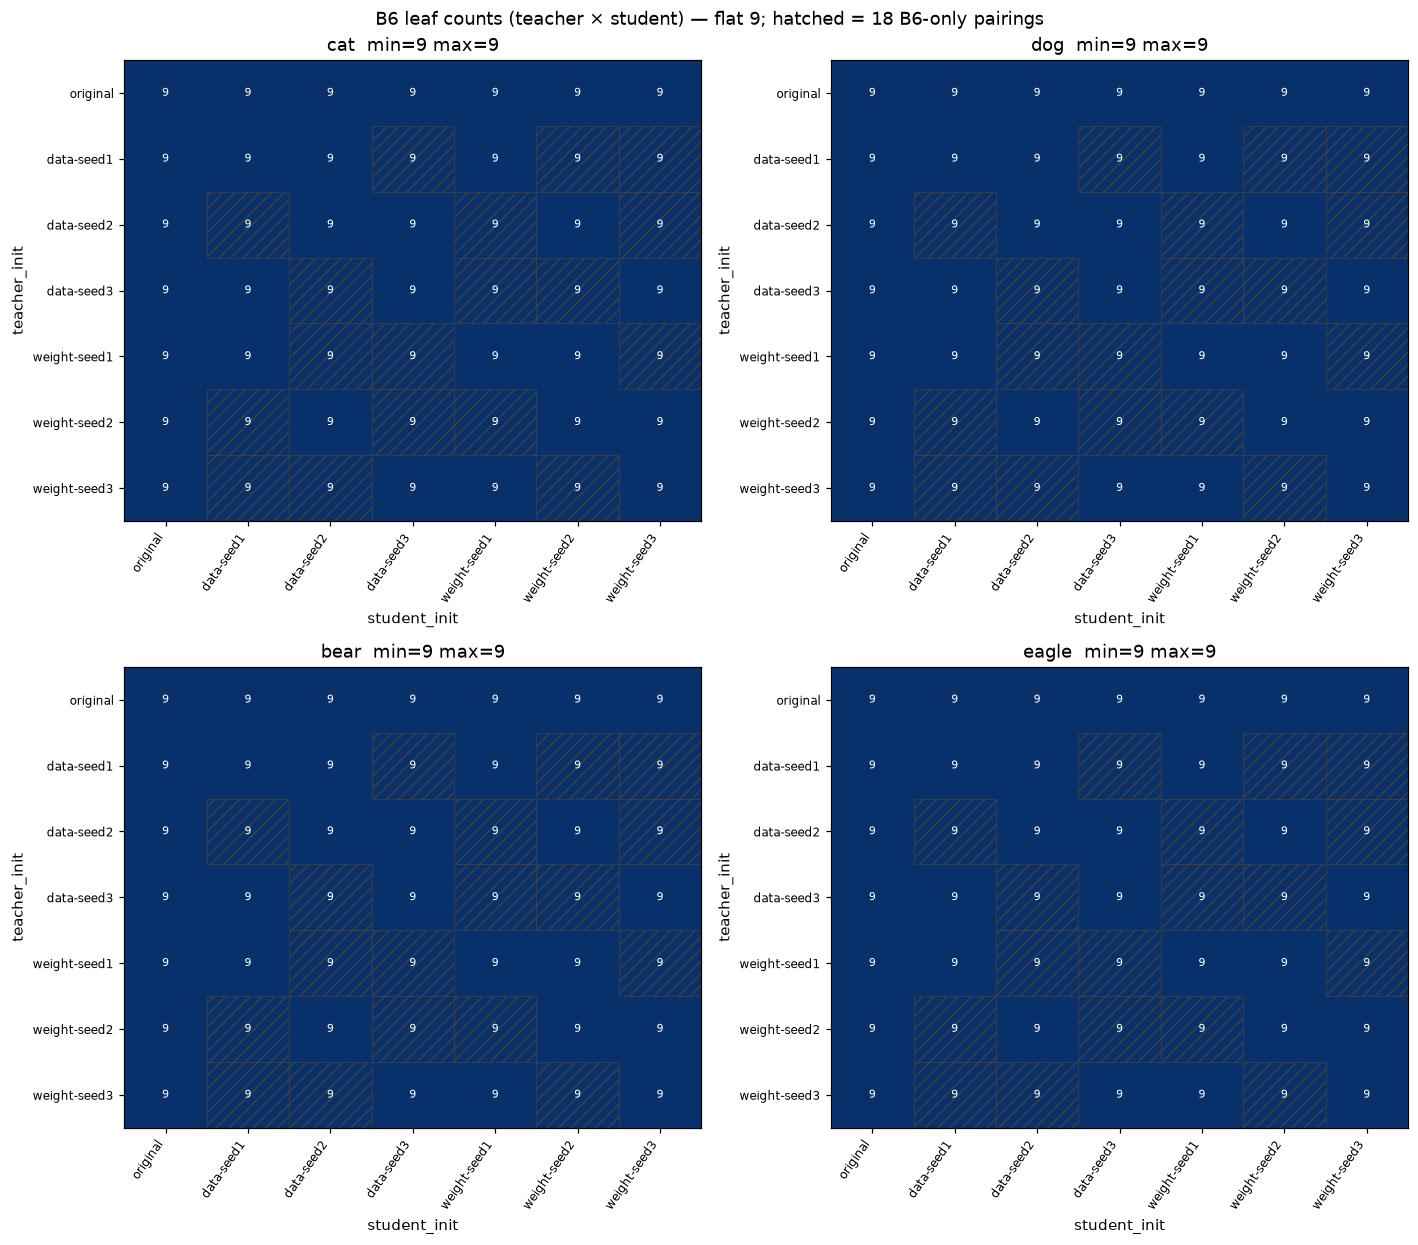

All four animals have a flat 9 leaf-count grid.


In [6]:
print_scope(treat_m, "B6 treat leaves after pairing annotate")

disk_pairs = {
    (s, t) for s, t in zip(treat_m["student_base"], treat_m["teacher_base"])
}
expected_pairs = {(p.student, p.teacher) for p in full_grid_pairs()}
if disk_pairs != expected_pairs:
    raise AssertionError(
        f"missing={expected_pairs - disk_pairs} extra={disk_pairs - expected_pairs}"
    )
print("Directed pairings on disk: 49, equals full_grid_pairs().")

per_animal = (
    treat_m.groupby("animal")
    .agg(
        n_leaves=("gseed", "size"),
        n_pairings=("pairing", "nunique"),
        n_configs=("teacher_tag", "nunique"),
    )
    .reindex(list(ANIMALS))
)
# n_configs above is unique teacher_tag only — recount properly.
per_animal["n_config_dirs"] = [
    treat_m.loc[treat_m.animal == a].drop_duplicates(
        ["model", "teacher_tag", "gkd_tag"]
    ).shape[0]
    for a in ANIMALS
]
print("Per-animal treat coverage (design: 441 leaves / 49 pairings / 147 configs):")
display(per_animal)
if not (per_animal["n_pairings"] == 49).all():
    raise AssertionError(per_animal["n_pairings"].to_dict())
if not (per_animal["n_leaves"] == B6_TREAT_CELLS_PER_ANIMAL).all():
    raise AssertionError(per_animal["n_leaves"].to_dict())
if not (per_animal["n_config_dirs"] == 147).all():
    raise AssertionError(per_animal["n_config_dirs"].to_dict())

n_same = int(
    treat_m.drop_duplicates(["student_base", "teacher_base"])["same_init_pair"].sum()
)
n_cross = 49 - n_same
print(f"Same-init diagonal / off-diagonal pairings: {n_same} / {n_cross}")
if (n_same, n_cross) != (7, 42):
    raise AssertionError((n_same, n_cross))

print("Reciprocal unordered base pairs with both directions:")
have = {(s, t) for s, t in zip(treat_m["student_base"], treat_m["teacher_base"])}
for animal in ANIMALS:
    sub_have = {
        (s, t)
        for s, t, a in zip(treat_m["student_base"], treat_m["teacher_base"], treat_m["animal"])
        if a == animal
    }
    recip = [
        (s, t)
        for s, t in sub_have
        if s != t and (t, s) in sub_have and (s, t) < (t, s)
    ]
    print(f"  {animal}: {len(recip)} of 21")
    if len(recip) != 21:
        raise AssertionError((animal, len(recip)))

print("Control configs / leaves:", len(ctrl_dirs), "/", len(ctrl_leaves))
if (len(ctrl_dirs), len(ctrl_leaves)) != (28, 84):
    raise AssertionError((len(ctrl_dirs), len(ctrl_leaves)))

print_scope(treat_m, "7×7 leaf-count heatmaps (should be flat 9)")
fig, axes = animal_axes(figsize=(13.0, 11.5))
for ax, animal in zip(axes, ANIMALS):
    sub = treat_m[treat_m["animal"] == animal]
    grid_n = (
        sub.groupby(["teacher_base", "student_base"], dropna=False)
        .size()
        .unstack()
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
        .fillna(0)
        .astype(int)
    )
    if not (grid_n.to_numpy() == 9).all():
        raise AssertionError(f"{animal} leaf grid not flat 9:\n{grid_n}")
    aplots.annotated_heatmap(
        ax,
        grid_n.astype(float),
        cmap="Blues",
        vmin=0,
        vmax=9,
        fmt="{:.0f}",
        origin="upper",
        empty_facecolor="#f0f0f0",
    )
    hatch_b6_new_cells(ax, BASE_ORDER, BASE_ORDER)
    ax.set_title(f"{animal}  min={int(grid_n.min().min())} max={int(grid_n.max().max())}")
    ax.set_xlabel("student_init")
    ax.set_ylabel("teacher_init")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("B6 leaf counts (teacher × student) — flat 9; hatched = 18 B6-only pairings")
plt.tight_layout()
plt.show()
print("All four animals have a flat 9 leaf-count grid.")


## 3. Control floor by student init × animal

**What this measures.** GKD-from-unfinetuned-teacher `p_target` on `test`
/ `prob`, one panel per animal, against `CONTROL_FLOOR_MAX`=0.02. This
is floor (b), not the untuned base. `CONTROL_FLOOR_MAX_SPREAD` (0.01) is
an **A2 across-LR-ladder** gate, not a 7-base spread gate — it is N/A
at a single frozen recipe. Do not present a 7-base spread as if it were
that check.


SCOPE: 28 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | GKD control floor, test/prob
Control p_target by animal:


,mean,min,max,std,count
animal,,,,,
cat,0.004261,0.002628,0.007497,0.001574,7
dog,0.008391,0.005715,0.014358,0.002850,7
bear,0.000748,0.000578,0.001283,0.000243,7
eagle,0.000400,0.000138,0.000751,0.000204,7


Per (animal, student base) floor: min=0.0001 median=0.0020 max=0.0144
cells exceeding CONTROL_FLOOR_MAX=0.02: 0 (design: 0). CONTROL_FLOOR_MAX_SPREAD=0.01 is an A2 across-LR-ladder gate — N/A at one frozen recipe.


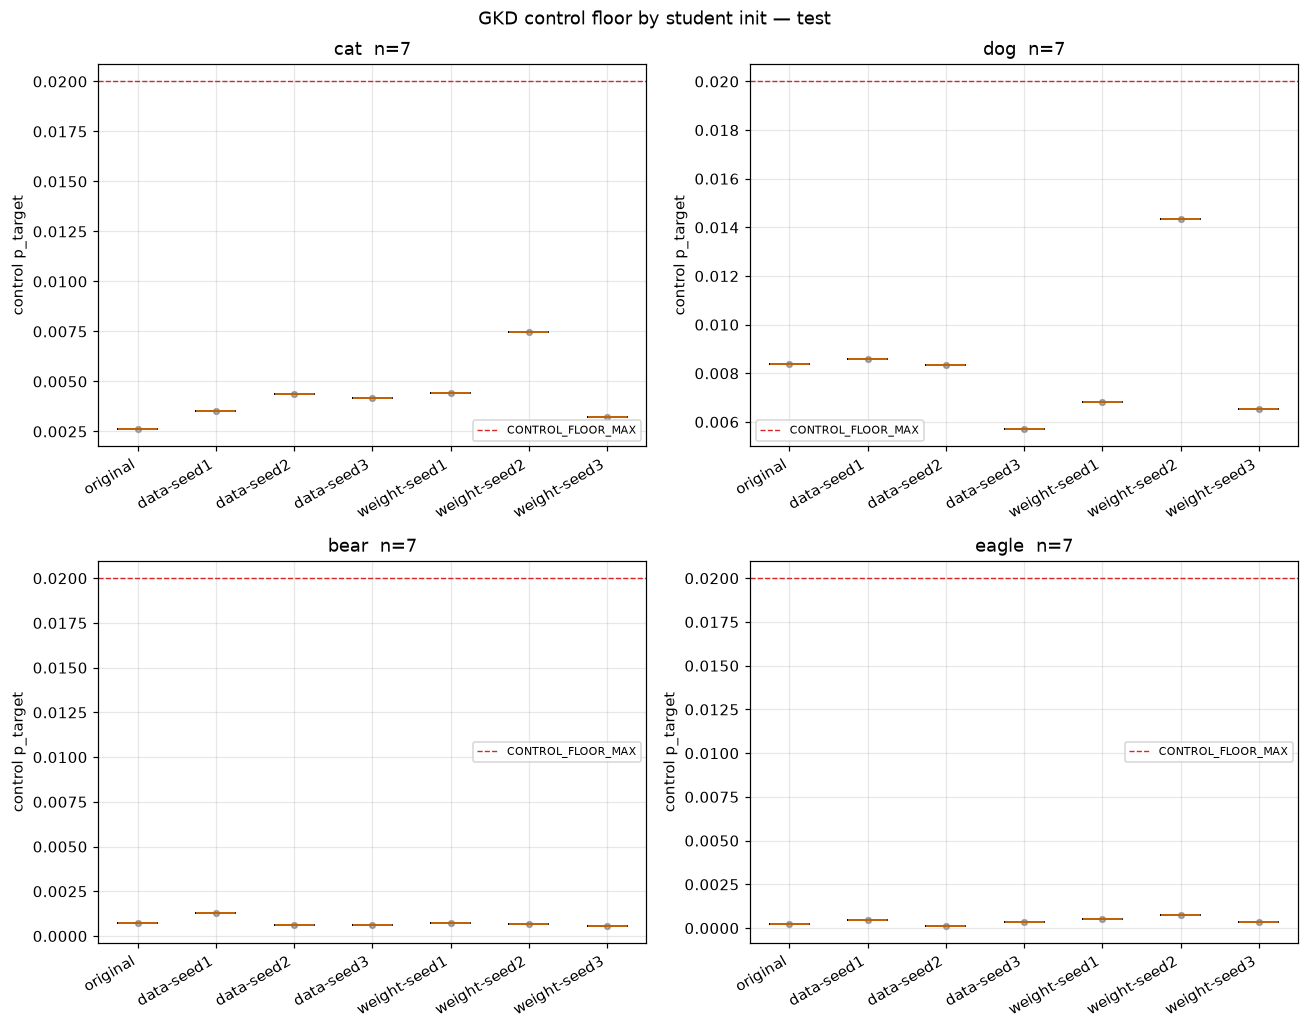

In [7]:
ctrl_pref = annotate_pairing(
    pref[(pref["is_control"]) & (pref["set"] == PRIMARY_SET)].copy()
)
print_scope(ctrl_pref, f"GKD control floor, {PRIMARY_SET}/prob")
print("Control p_target by animal:")
display(
    ctrl_pref.groupby("animal")["p_target"]
    .agg(["mean", "min", "max", "std", "count"])
    .reindex(list(ANIMALS))
)
floor_cell = (
    ctrl_pref.groupby(["animal", "student_base"], dropna=False)["p_target"]
    .mean()
    .reset_index()
)
print(
    f"Per (animal, student base) floor: min={floor_cell.p_target.min():.4f} "
    f"median={floor_cell.p_target.median():.4f} "
    f"max={floor_cell.p_target.max():.4f}"
)
n_over = int((floor_cell["p_target"] > CONTROL_FLOOR_MAX).sum())
print(
    f"cells exceeding CONTROL_FLOOR_MAX={CONTROL_FLOOR_MAX}: {n_over} "
    f"(design: 0). CONTROL_FLOOR_MAX_SPREAD={CONTROL_FLOOR_MAX_SPREAD} "
    "is an A2 across-LR-ladder gate — N/A at one frozen recipe."
)
if n_over != 0:
    raise AssertionError(n_over)
if abs(floor_cell.p_target.min() - 0.0001) > 5e-4:
    print("NOTE: min floor differs from the 0.0001 snapshot:", float(floor_cell.p_target.min()))
if abs(floor_cell.p_target.median() - 0.0020) > 5e-4:
    print("NOTE: median floor differs from the 0.0020 snapshot:", float(floor_cell.p_target.median()))
if abs(floor_cell.p_target.max() - 0.0144) > 5e-4:
    print("NOTE: max floor differs from the 0.0144 snapshot:", float(floor_cell.p_target.max()))

fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = ctrl_pref[ctrl_pref["animal"] == animal]
    groups = groups_for_strip(sub, "student_base", "p_target", BASE_ORDER)
    aplots.strip_box(ax, groups, BASE_ORDER, colors=["0.35"] * len(BASE_ORDER), rotation=30)
    ax.axhline(CONTROL_FLOOR_MAX, color="C3", lw=0.9, ls="--", label="CONTROL_FLOOR_MAX")
    ax.set_title(f"{animal}  n={len(sub)}")
    ax.set_ylabel("control p_target")
    ax.legend(fontsize=7)
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle(f"GKD control floor by student init — {PRIMARY_SET}")
plt.tight_layout()
plt.show()


## 4. 7×7 Δ heatmaps

**What this measures.** Mean `subliminal_delta` on `test` / `prob` in the
complete 7×7 teacher × student grid, one panel per animal. This is the
headline figure. Hatched cells are the 18 B6-only pairings (12 unmatched-k
`family_swap` + 3 reverse `data_cyclic` + 3 reverse `weight_cyclic`).
Cell counts are the number of (already ftseed-collapsed) rows. Raw
`p_target` is behind `DEEP_ANIMAL`.


subliminal_delta rows (all sets): 1372
rows per set: {'consensus': 196, 'dislike': 196, 'favorite': 196, 'register': 196, 'storytelling': 196, 'test': 196, 'validation': 196}
unmatched lineages (inner join dropped none): 0 by construction of 1372=196×7
Computing subliminal_delta_ci (pairing gseeds, t-interval) ...
  subliminal_delta_ci: 1372 rows in 0.7s
n_pairs==3 on all rows: True  (n_pairs!=3: 0)
SCOPE: 196 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | subliminal_delta test (ftseed already collapsed)
SCOPE: 196 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | pairing-level Δ test


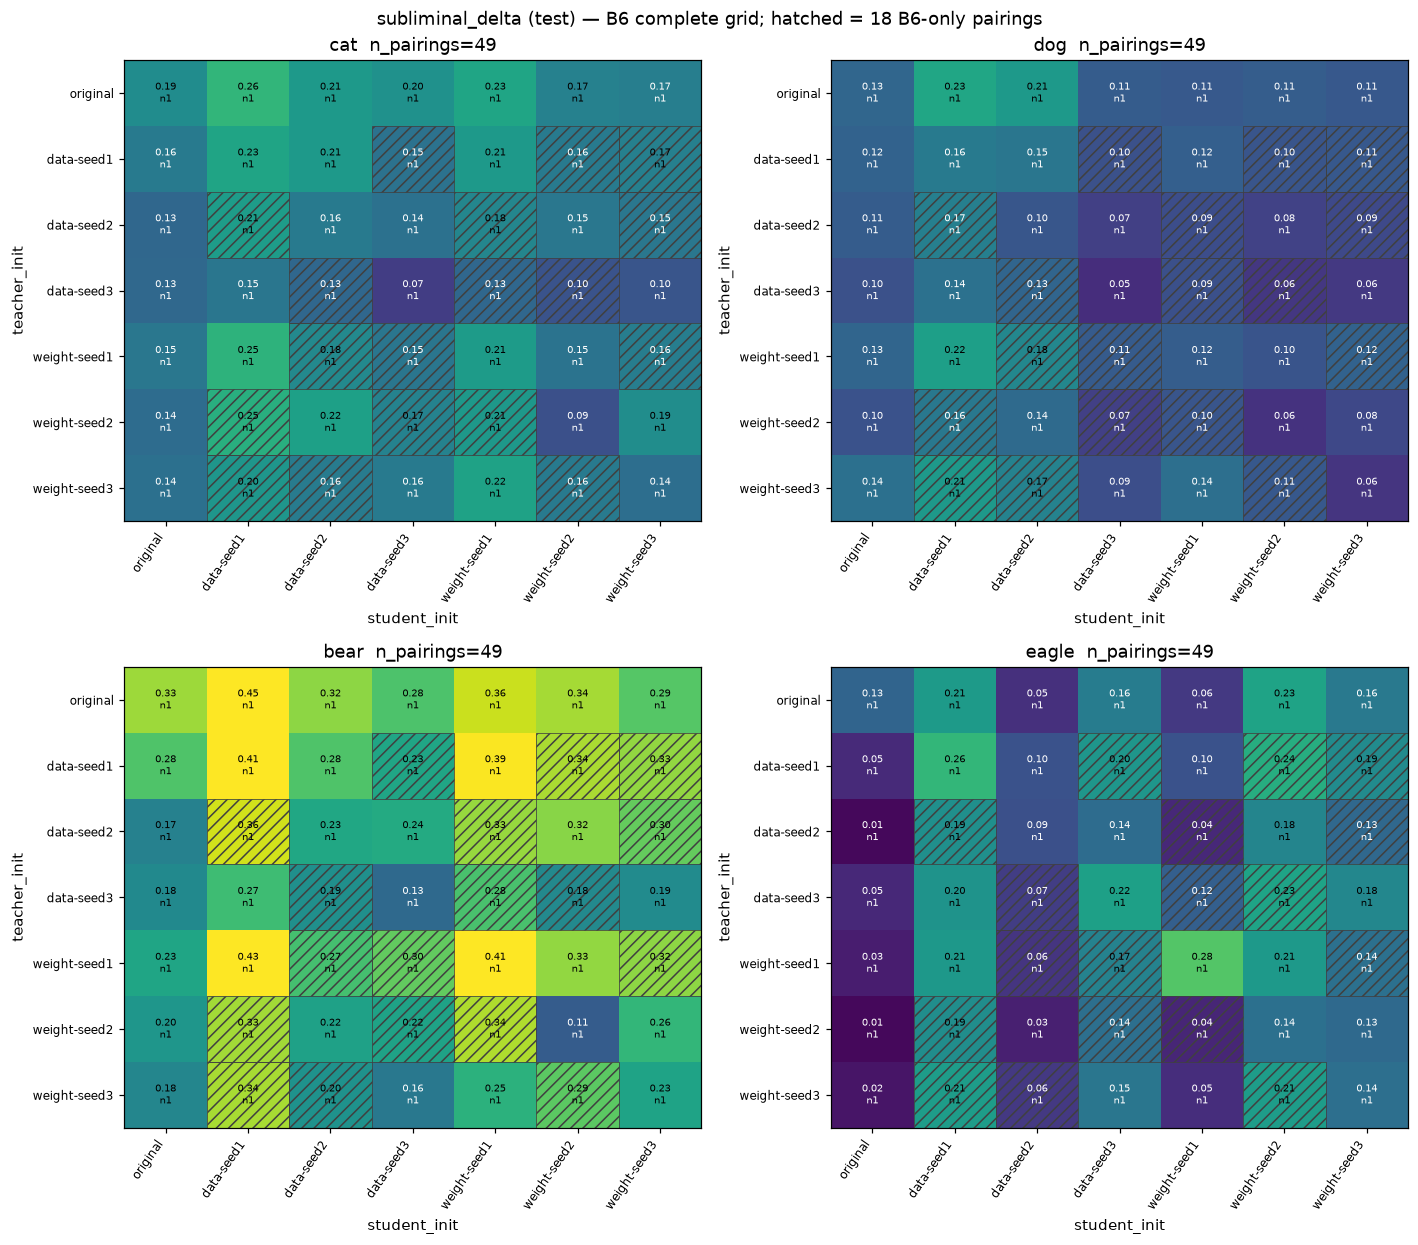

In [8]:
delta = subliminal_delta(pref)
print("subliminal_delta rows (all sets):", len(delta))
if len(delta) != 1372:
    raise AssertionError(len(delta))
by_set = delta.groupby("set").size()
print("rows per set:", by_set.to_dict())
if not (by_set == 196).all():
    raise AssertionError(by_set.to_dict())
print("unmatched lineages (inner join dropped none): 0 by construction of 1372=196×7")

print("Computing subliminal_delta_ci (pairing gseeds, t-interval) ...", flush=True)
t0 = time.perf_counter()
delta_ci = subliminal_delta_ci(pref)
print(f"  subliminal_delta_ci: {len(delta_ci)} rows in {time.perf_counter() - t0:.1f}s")
if len(delta_ci) != 1372:
    raise AssertionError(len(delta_ci))
n_bad = int((delta_ci["n_pairs"] != 3).sum())
print(f"n_pairs==3 on all rows: {n_bad == 0}  (n_pairs!=3: {n_bad})")
if n_bad != 0:
    raise AssertionError(n_bad)

delta_ann = annotate_pairing(delta)
delta_test = delta_ann[delta_ann["set"] == PRIMARY_SET].copy()
n_lineages = delta_test.drop_duplicates(
    ["animal", "student_base", "teacher_base"]
).shape[0]
if n_lineages != 49 * len(ANIMALS):
    raise AssertionError(n_lineages)
print_scope(delta_test, f"subliminal_delta {PRIMARY_SET} (ftseed already collapsed)")
if delta_test["group"].isna().any():
    raise AssertionError("group is None — PAIR_LOOKUP was built from the wrong pair list")

pd_delta = pairing_delta_frame(delta, PRIMARY_SET)
print_scope(pd_delta, f"pairing-level Δ {PRIMARY_SET}")

fig, axes = animal_axes(figsize=(13.0, 11.5))
vmax = float(np.nanpercentile(delta_test["subliminal_delta"], 98))
for ax, animal in zip(axes, ANIMALS):
    sub = delta_test[delta_test["animal"] == animal]
    g_delta = (
        sub.pivot_table(
            index="teacher_base",
            columns="student_base",
            values="subliminal_delta",
            aggfunc="mean",
        )
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    g_n = (
        sub.groupby(["teacher_base", "student_base"])
        .size()
        .unstack()
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    aplots.annotated_heatmap(
        ax,
        g_delta,
        cmap="viridis",
        vmin=0.0,
        vmax=max(vmax, 0.05),
        counts=g_n,
        fmt="{:.2f}",
        origin="upper",
        empty_facecolor="#f4f4f4",
        cell_fontsize=6.5,
    )
    hatch_b6_new_cells(ax, list(g_delta.index), list(g_delta.columns))
    ax.set_title(f"{animal}  n_pairings={sub.pairing.nunique()}")
    ax.set_xlabel("student_init")
    ax.set_ylabel("teacher_init")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle(
    f"subliminal_delta ({PRIMARY_SET}) — B6 complete grid; hatched = 18 B6-only pairings"
)
plt.tight_layout()
plt.show()


DEEP_ANIMAL='cat' — raw p_target_treatment companion (not the Cloud effect)
SCOPE: 49 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | raw p_target_treatment cat test


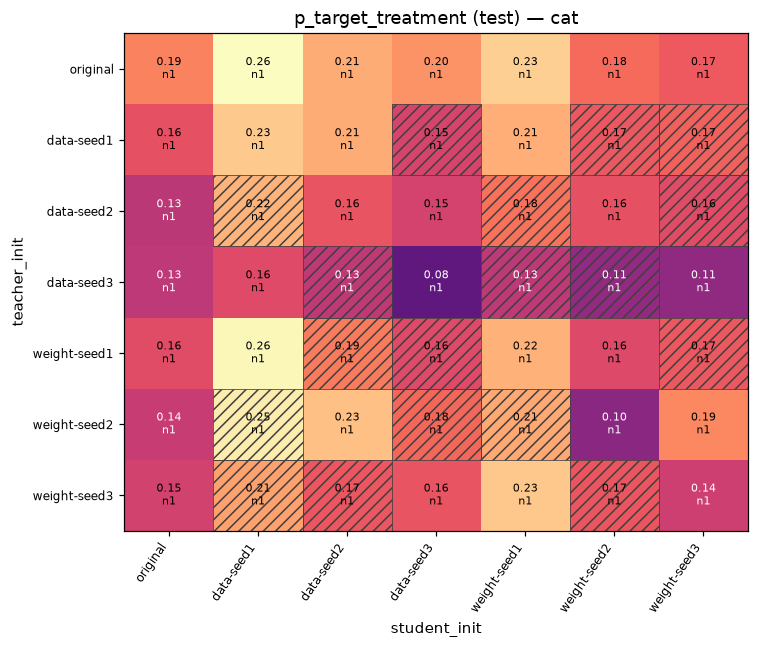

In [9]:
print(f"DEEP_ANIMAL={DEEP_ANIMAL!r} — raw p_target_treatment companion (not the Cloud effect)")
sub = delta_test[delta_test["animal"] == DEEP_ANIMAL]
print_scope(sub, f"raw p_target_treatment {DEEP_ANIMAL} {PRIMARY_SET}")
g_raw = (
    sub.pivot_table(
        index="teacher_base",
        columns="student_base",
        values="p_target_treatment",
        aggfunc="mean",
    )
    .reindex(index=BASE_ORDER, columns=BASE_ORDER)
)
g_n = (
    sub.groupby(["teacher_base", "student_base"])
    .size()
    .unstack()
    .reindex(index=BASE_ORDER, columns=BASE_ORDER)
)
fig, ax = plt.subplots(figsize=(7.0, 6.0))
aplots.annotated_heatmap(
    ax,
    g_raw,
    cmap="magma",
    vmin=0.0,
    vmax=float(np.nanmax(g_raw.values)) if np.isfinite(g_raw.to_numpy()).any() else 1.0,
    counts=g_n,
    fmt="{:.2f}",
    origin="upper",
    empty_facecolor="#f4f4f4",
)
hatch_b6_new_cells(ax, list(g_raw.index), list(g_raw.columns))
ax.set_title(f"p_target_treatment ({PRIMARY_SET}) — {DEEP_ANIMAL}")
ax.set_xlabel("student_init")
ax.set_ylabel("teacher_init")
plt.tight_layout()
plt.show()


## 5. The 2×2 corner factorial

**What this measures.** Mean `subliminal_delta` (`test` / `prob`) by the
init × stream corner, per animal and pooled (within-animal z-scores).
Intervals are **pairing-cluster** percentile bootstraps. This is the
first version of this figure that needs **no tier split** — every
pairing is 3 tfs × 3 gseeds. Presented as a **replication surface**.
Any pairing ranking is **post-hoc** (no direction/receptivity prereg
was filed).


SCOPE: 196 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | pairing-level Δ test — uniform depth, no headline gate
Pairing-cluster CIs by corner — EXPLORATORY / POST-HOC:


,animal,corner,mean,ci_lo,ci_hi,n_pairings,p_boot,ci_width,ci_degenerate
0,cat,shared_init_shared_stream,0.156478,0.116589,0.195084,7,0.0,0.078495,False
1,cat,diff_init_shared_stream,0.174595,0.158954,0.192350,12,0.0,0.033396,False
2,cat,shared_init_diff_stream,0.173390,0.151498,0.197002,12,0.0,0.045504,False
3,cat,diff_init_diff_stream,0.172875,0.153966,0.192072,18,0.0,0.038107,False
4,dog,shared_init_shared_stream,0.096383,0.069945,0.124752,7,0.0,0.054807,False
5,dog,diff_init_shared_stream,0.113136,0.103907,0.122921,12,0.0,0.019014,False
6,dog,shared_init_diff_stream,0.137181,0.113180,0.163669,12,0.0,0.050490,False
7,dog,diff_init_diff_stream,0.119583,0.098644,0.142220,18,0.0,0.043576,False
8,bear,shared_init_shared_stream,0.264659,0.182074,0.346527,7,0.0,0.164454,False
9,bear,diff_init_shared_stream,0.281786,0.249823,0.312464,12,0.0,0.062640,False


n_pairings by corner (should be 7 / 12 / 12 / 18 per animal):


corner,shared_init_shared_stream,diff_init_shared_stream,shared_init_diff_stream,diff_init_diff_stream
animal,,,,
cat,7,12,12,18
dog,7,12,12,18
bear,7,12,12,18
eagle,7,12,12,18


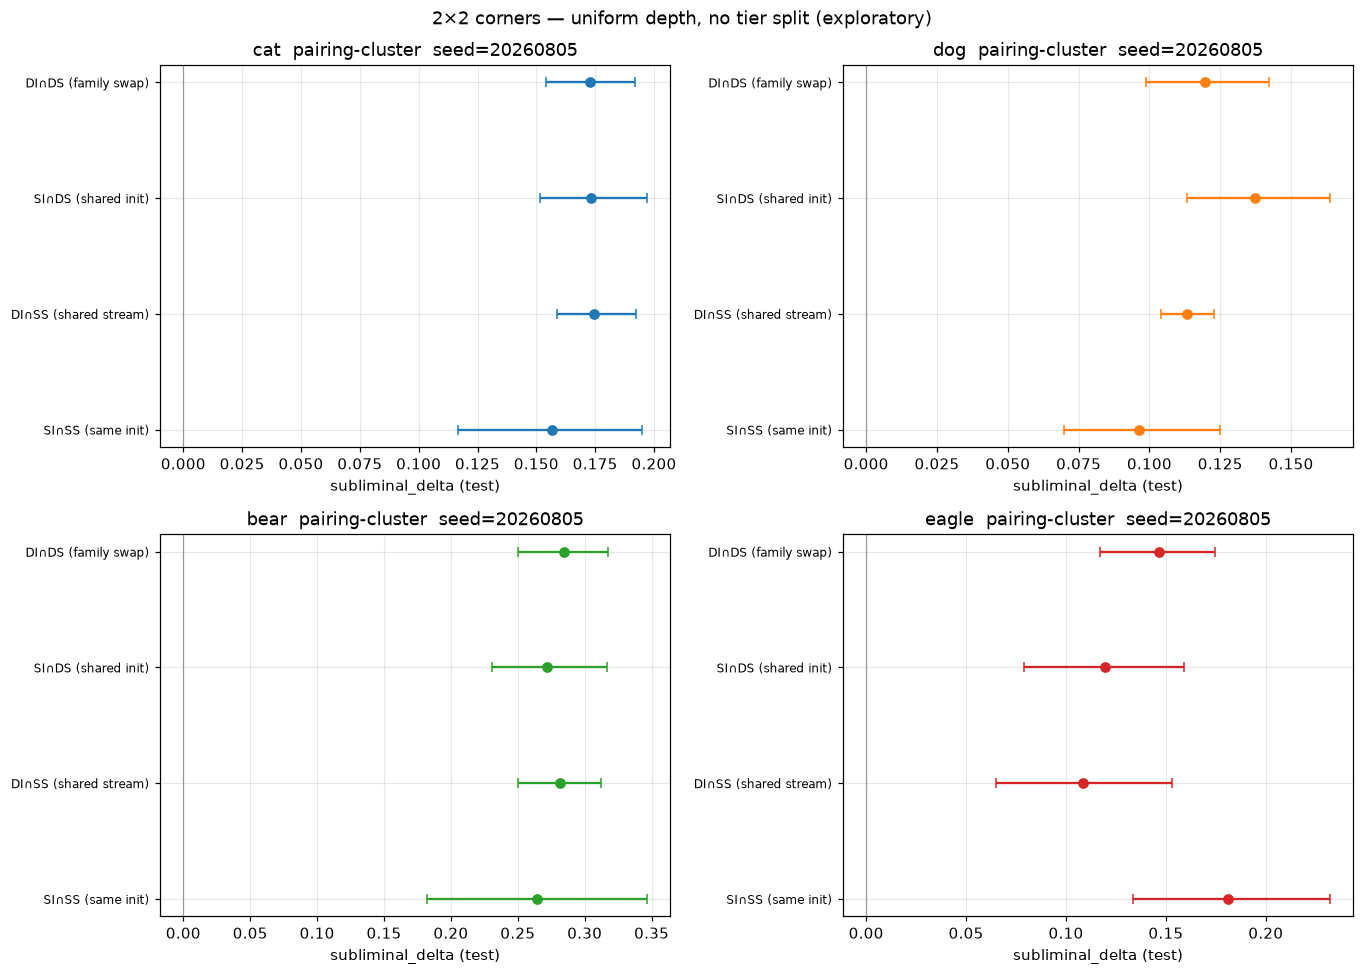

Pooled (within-animal z) corner means:


,animal,corner,mean,ci_lo,ci_hi,n_pairings,p_boot,ci_width,ci_degenerate
0,pooled,shared_init_shared_stream,-0.110501,-0.832013,0.644501,7,0.7488,1.476514,False
1,pooled,diff_init_shared_stream,-0.092179,-0.337791,0.132049,12,0.4520,0.469839,False
2,pooled,shared_init_diff_stream,0.047218,-0.407566,0.545273,12,0.8696,0.952840,False
3,pooled,diff_init_diff_stream,0.072947,-0.225937,0.405030,18,0.6668,0.630967,False


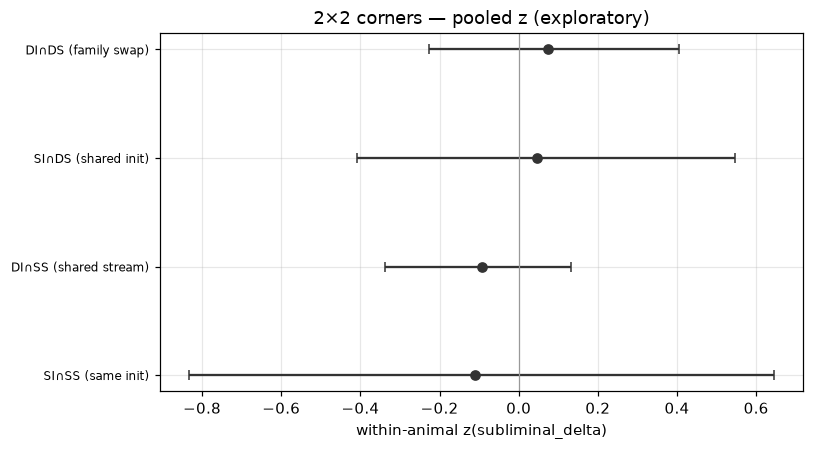

No H1/H2 verdict is computed here. Ranking pairings by these means is post-hoc.


In [10]:
print_scope(pd_delta, f"pairing-level Δ {PRIMARY_SET} — uniform depth, no headline gate")
corner_tables = [
    corner_bootstrap_table(pd_delta, animal=animal, n_boot=N_BOOT, seed=BOOTSTRAP_SEED)
    for animal in ANIMALS
]
corner_ci = pd.concat(corner_tables, ignore_index=True)
print("Pairing-cluster CIs by corner — EXPLORATORY / POST-HOC:")
display(corner_ci)
print("n_pairings by corner (should be 7 / 12 / 12 / 18 per animal):")
display(
    corner_ci.pivot(index="animal", columns="corner", values="n_pairings")
    .reindex(index=list(ANIMALS), columns=CORNER_ORDER)
)

fig, axes = animal_axes(figsize=(12.5, 9.0))
for ax, animal in zip(axes, ANIMALS):
    sub = corner_ci[corner_ci["animal"] == animal].set_index("corner").reindex(CORNER_ORDER)
    y = np.arange(len(CORNER_ORDER))
    ax.errorbar(
        sub["mean"],
        y,
        xerr=[sub["mean"] - sub["ci_lo"], sub["ci_hi"] - sub["mean"]],
        fmt="o",
        color=ANIMAL_COLORS.get(animal, "C0"),
        capsize=3,
    )
    ax.axvline(0, color="0.6", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([CORNER_SHORT[c] for c in CORNER_ORDER], fontsize=8)
    ax.set_xlabel(f"subliminal_delta ({PRIMARY_SET})")
    ax.set_title(f"{animal}  pairing-cluster  seed={BOOTSTRAP_SEED}")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("2×2 corners — uniform depth, no tier split (exploratory)")
plt.tight_layout()
plt.show()

z = standardize_within_animal(pd_delta.copy(), "subliminal_delta")
z["subliminal_delta"] = z["subliminal_delta_z"]
pooled = corner_bootstrap_table(z, animal=None, n_boot=N_BOOT, seed=BOOTSTRAP_SEED)
print("Pooled (within-animal z) corner means:")
display(pooled)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
sub = pooled.set_index("corner").reindex(CORNER_ORDER)
y = np.arange(len(CORNER_ORDER))
ax.errorbar(
    sub["mean"],
    y,
    xerr=[sub["mean"] - sub["ci_lo"], sub["ci_hi"] - sub["mean"]],
    fmt="o",
    color="0.2",
    capsize=3,
)
ax.axvline(0, color="0.6", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([CORNER_SHORT[c] for c in CORNER_ORDER], fontsize=8)
ax.set_xlabel("within-animal z(subliminal_delta)")
ax.set_title("2×2 corners — pooled z (exploratory)")
plt.tight_layout()
plt.show()
print("No H1/H2 verdict is computed here. Ranking pairings by these means is post-hoc.")


## 6. Cloud shared-init test

**What this measures.** Cloud et al. claim subliminal learning requires
a shared teacher/student initialization. Per animal: 7 same-init
diagonal vs 42 off-diagonal mean Δ, `cross_positive_frac`, and sign
tests, at **uniform precision** (no headline-only footnote). Exploratory
— no prereg was filed.


SCOPE: 196 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | Cloud test, full 49-pair grid (7 vs 42)
Cloud shared-init test (pairing-cluster CIs; sign test on pairing Δs) — EXPLORATORY:


,animal,n_same,n_cross,same_mean,same_ci_lo,same_ci_hi,cross_mean,cross_ci_lo,cross_ci_hi,cross_ci_width,cross_positive_frac,cross_sign_n_pos,cross_sign_n,cross_sign_p,same_sign_p
0,cat,7,42,0.156478,0.116660,0.194803,0.173514,0.162300,0.185298,0.022998,1.0,42,42,2.273737e-13,0.007812
1,dog,7,42,0.096383,0.070142,0.124752,0.122769,0.110831,0.135527,0.024696,1.0,42,42,2.273737e-13,0.007812
2,bear,7,42,0.264659,0.181250,0.346527,0.280004,0.258907,0.301177,0.042270,1.0,42,42,2.273737e-13,0.007812
3,eagle,7,42,0.181202,0.133409,0.230756,0.127968,0.106100,0.149861,0.043761,1.0,42,42,2.273737e-13,0.007812


cross_positive_frac by animal: {'cat': 1.0, 'dog': 1.0, 'bear': 1.0, 'eagle': 1.0}


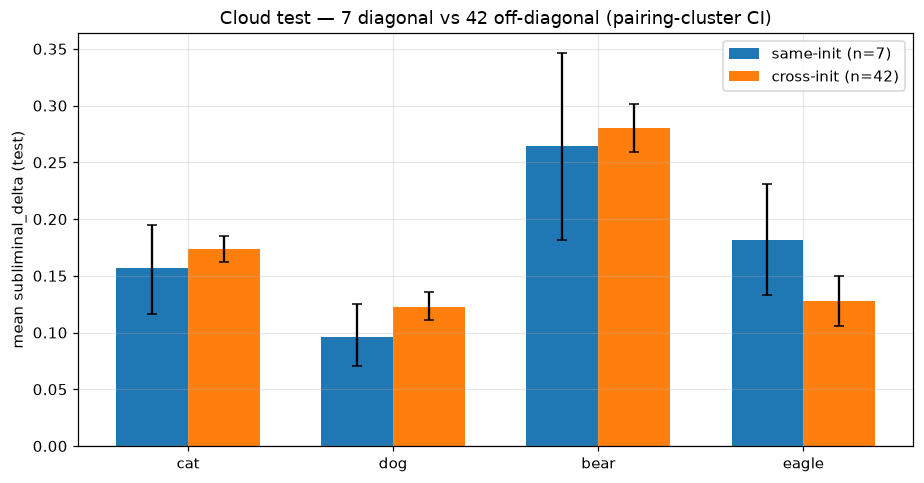

In [11]:
def cloud_rows(frame: pd.DataFrame) -> pd.DataFrame:
    rows: list[dict[str, Any]] = []
    for animal in ANIMALS:
        sub = frame[frame["animal"] == animal]
        same = sub.loc[sub["same_init_pair"], "subliminal_delta"]
        cross = sub.loc[~sub["same_init_pair"], "subliminal_delta"]
        same_est = pairing_cluster_ci(same.values) if len(same) else None
        cross_est = pairing_cluster_ci(cross.values) if len(cross) else None
        st_cross = sign_test(list(cross), 0.0, "greater")
        st_same = sign_test(list(same), 0.0, "greater")
        rows.append(
            {
                "animal": animal,
                "n_same": int(same.size),
                "n_cross": int(cross.size),
                "same_mean": float(same.mean()) if len(same) else np.nan,
                "same_ci_lo": same_est.ci_low if same_est else np.nan,
                "same_ci_hi": same_est.ci_high if same_est else np.nan,
                "cross_mean": float(cross.mean()) if len(cross) else np.nan,
                "cross_ci_lo": cross_est.ci_low if cross_est else np.nan,
                "cross_ci_hi": cross_est.ci_high if cross_est else np.nan,
                "cross_ci_width": (
                    (cross_est.ci_high - cross_est.ci_low) if cross_est else np.nan
                ),
                "cross_positive_frac": float((cross > 0).mean()) if len(cross) else np.nan,
                "cross_sign_n_pos": st_cross.n_positive,
                "cross_sign_n": st_cross.n_effective,
                "cross_sign_p": st_cross.p_value,
                "same_sign_p": st_same.p_value,
            }
        )
    return pd.DataFrame(rows)


cloud = cloud_rows(pd_delta)
print_scope(pd_delta, "Cloud test, full 49-pair grid (7 vs 42)")
print("Cloud shared-init test (pairing-cluster CIs; sign test on pairing Δs) — EXPLORATORY:")
display(cloud)
if not (cloud["n_same"] == 7).all() or not (cloud["n_cross"] == 42).all():
    raise AssertionError(cloud[["animal", "n_same", "n_cross"]])
print(
    "cross_positive_frac by animal:",
    {r.animal: r.cross_positive_frac for r in cloud.itertuples()},
)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
xpos = np.arange(len(ANIMALS))
width = 0.35
ax.bar(
    xpos - width / 2,
    cloud["same_mean"],
    width,
    yerr=np.vstack([
        cloud["same_mean"] - cloud["same_ci_lo"],
        cloud["same_ci_hi"] - cloud["same_mean"],
    ]),
    label="same-init (n=7)",
    color="C0",
    capsize=3,
)
ax.bar(
    xpos + width / 2,
    cloud["cross_mean"],
    width,
    yerr=np.vstack([
        cloud["cross_mean"] - cloud["cross_ci_lo"],
        cloud["cross_ci_hi"] - cloud["cross_mean"],
    ]),
    label="cross-init (n=42)",
    color="C1",
    capsize=3,
)
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(list(ANIMALS))
ax.set_ylabel(f"mean subliminal_delta ({PRIMARY_SET})")
ax.set_title("Cloud test — 7 diagonal vs 42 off-diagonal (pairing-cluster CI)")
ax.legend()
plt.tight_layout()
plt.show()


## 7. H1 contrast at n=12 vs n=12

**What this measures.** SI∩DS (shared init, different stream) versus
DI∩SS (different init, shared stream), per animal and pooled-z, with a
pairing-cluster bootstrap CI on the contrast
`mean(DI∩SS) − mean(SI∩DS)`. Roadmap H1 predicted that pairings sharing
*batch composition* (DI∩SS) transfer better than those sharing *weight
init* (SI∩DS). **H1/H2 adjudication remains out of scope** — this is a
descriptive contrast at the new power (was n=2 vs n=2 with degenerate
CIs on the headline tier). Exploratory / post-hoc.


H1 contrast mean(DI∩SS) − mean(SI∩DS) — DESCRIPTIVE, not an adjudication:


,animal,n_SI_DS,n_DI_SS,mean_SI_DS,mean_DI_SS,contrast_DI_minus_SI,ci_lo,ci_hi,p_boot
0,cat,12,12,0.173390,0.174595,0.001205,-0.027562,0.029820,0.9302
1,dog,12,12,0.137181,0.113136,-0.024046,-0.052422,0.001885,0.0772
2,bear,12,12,0.271570,0.281786,0.010217,-0.044783,0.061969,0.6890
3,eagle,12,12,0.119339,0.108484,-0.010855,-0.071785,0.051499,0.7178


Pooled-z contrast DI∩SS − SI∩DS: -0.139 CI[-0.514, 0.224] p_boot=0.4662 n=48 vs 48


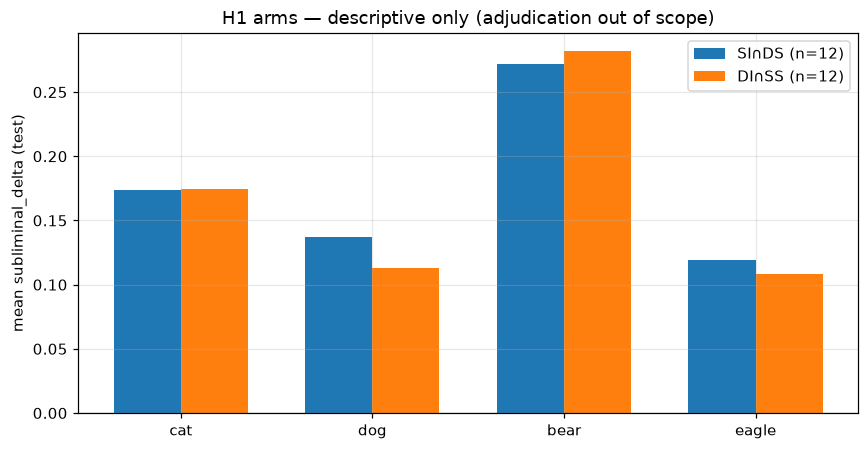

In [12]:
h1_rows = []
for animal in ANIMALS:
    sub = pd_delta[pd_delta["animal"] == animal]
    si_ds = sub.loc[sub["corner"] == CORNER_SHARED_INIT_DIFF_STREAM, "subliminal_delta"]
    di_ss = sub.loc[sub["corner"] == CORNER_DIFF_INIT_SHARED_STREAM, "subliminal_delta"]
    if len(si_ds) != 12 or len(di_ss) != 12:
        raise AssertionError((animal, len(si_ds), len(di_ss)))
    est = contrast_cluster_ci(di_ss.values, si_ds.values)
    h1_rows.append(
        {
            "animal": animal,
            "n_SI_DS": int(si_ds.size),
            "n_DI_SS": int(di_ss.size),
            "mean_SI_DS": float(si_ds.mean()),
            "mean_DI_SS": float(di_ss.mean()),
            "contrast_DI_minus_SI": est.estimate,
            "ci_lo": est.ci_low,
            "ci_hi": est.ci_high,
            "p_boot": est.p_boot,
        }
    )
h1 = pd.DataFrame(h1_rows)
print("H1 contrast mean(DI∩SS) − mean(SI∩DS) — DESCRIPTIVE, not an adjudication:")
display(h1)

z_h1 = standardize_within_animal(pd_delta.copy(), "subliminal_delta")
si_z = z_h1.loc[z_h1["corner"] == CORNER_SHARED_INIT_DIFF_STREAM, "subliminal_delta_z"]
di_z = z_h1.loc[z_h1["corner"] == CORNER_DIFF_INIT_SHARED_STREAM, "subliminal_delta_z"]
h1_z = contrast_cluster_ci(di_z.values, si_z.values)
print(
    f"Pooled-z contrast DI∩SS − SI∩DS: {h1_z.estimate:.3f} "
    f"CI[{h1_z.ci_low:.3f}, {h1_z.ci_high:.3f}] p_boot={h1_z.p_boot:.4g} "
    f"n={len(di_z)} vs {len(si_z)}"
)

fig, ax = plt.subplots(figsize=(8.0, 4.2))
xpos = np.arange(len(ANIMALS))
width = 0.35
ax.bar(xpos - width / 2, h1["mean_SI_DS"], width, label="SI∩DS (n=12)", color="C0")
ax.bar(xpos + width / 2, h1["mean_DI_SS"], width, label="DI∩SS (n=12)", color="C1")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xticks(xpos)
ax.set_xticklabels(list(ANIMALS))
ax.set_ylabel(f"mean subliminal_delta ({PRIMARY_SET})")
ax.set_title("H1 arms — descriptive only (adjudication out of scope)")
ax.legend()
plt.tight_layout()
plt.show()


## 8. Direction asymmetry (D1)

**What this measures.** All 21 reciprocal unordered base pairs × 4
animals = 84 directed contrasts. Per-animal mean signed asymmetry, a
sign test, and a comparison of mean |asymmetry| against 2× the pooled
within-cell replicate SD.

**Orientation caveat.** `reciprocal_asymmetries` orients each contrast
lex-smaller-as-teacher, and these labels sort `data-seed*` <
`original` < `weight-seed*`. A lex-oriented sign test therefore mostly
asks "does the data family teach better than the weight family", which
is confounded with the naming, not a direction-per-se test. The signed
mean and the sign test are reported because the roadmap rule names
them, then re-tested orientation-free: a per-contrast Welch test on the
three `teacher_ftseed` block means per direction, BH-corrected across
the 84 contrasts. That statistic does not depend on which direction is
called forward.

Also reproduces the roadmap §1.3 table shape
(`original`-as-teacher vs `original`-as-student) from the **complete**
grid, and flags that the roadmap's version was marked `[verify]` and
derived from the 31-pairing tier.

**Claim D1 (roadmap §4, verbatim):** Over the 21 unordered base pairs ×
4 animals, the mean signed |Δ(B←A) − Δ(A←B)| exceeds 2× the pooled
within-cell replicate SD, and the sign test over 84 contrasts has
p < 0.01.

**Exploratory / post-hoc** — no `PREREG_DIRECTION_RECEPTIVITY.md`.


Orientation assert: decomposition cells are (teacher, student, delta).
CornerPair is (student, teacher). Getting this backwards is the single biggest correctness risk in §8–§11.
toy emissivity: {'A': 0.20000000000000012, 'B': -0.20000000000000012}
toy receptivity: {'A': -0.20000000000000004, 'B': 0.20000000000000004}
Orientation OK: teacher-first cells give τ_A > τ_B and σ_B > σ_A.
hand-known cat data-seed1←data-seed1 Δ: 0.2264825690485304
SCOPE: 1764 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | gseed-level paired Δ test
Pooled within-cell replicate SD (tfs×gseed residuals): 0.0402
SCOPE: 84 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | 84 reciprocal contrasts (lex-smaller = base_a = forward teacher)
Per-animal signed / absolute asymmetry:


,mean_signed,mean_abs,n
animal,,,
cat,-0.028146,0.044963,21
dog,-0.046108,0.047654,21
bear,0.003541,0.070323,21
eagle,0.017778,0.085677,21


mean |asymmetry|=0.0622  2×pooled_SD=0.0804  exceeds=False
Scale note: the roadmap bar is 2× the SD of a single leaf, but each Δ cell averages 9 leaves, so the noise on one asymmetry is ≈√2·SD/√9 = 0.0190 and 2× that is 0.0379. Failing the roadmap bar therefore does not mean the asymmetries are within noise; the per-contrast test below is the noise comparison.
sign test over 84 lex-oriented contrasts: 28/84 p=0.002985 (two-sided)
CAUTION: the lex orientation is not a substantive hypothesis. Labels sort data-seed* < original < weight-seed*, so lex-smaller-as-teacher is mostly data-family-as-teacher; this sign test is confounded with family ordering and is NOT evidence that direction per se matters.
Block means vs headline Δ aggregation: max |diff| in asymmetry = 0.0000 (ftseed-block mean of gseed Δ vs the loader's aggregation)
Orientation-free per-contrast Welch test on ftseed blocks: 11/84 contrasts at BH q<0.05 (0.131)


,n_sig,min_q,n
animal,,,
cat,0,0.057993,21
dog,8,0.007179,21
bear,1,0.026097,21
eagle,2,0.018025,21


Each contrast has 3v3 ftseed blocks (Welch df≈4), so this count is a power-limited floor on how many pairs are individually asymmetric; it is orientation-free, unlike the sign test above.
Roadmap §1.3 table recomputed on the complete grid (roadmap was [verify] on the 31-pairing tier):


,animal,mean_original_as_teacher,mean_original_as_student,difference,ratio,sign,n_teacher,n_student
0,cat,0.204480,0.142837,0.061643,1.431559,6/6,6,6
1,dog,0.146977,0.116606,0.030370,1.260451,4/6,6,6
2,bear,0.338764,0.208160,0.130604,1.627420,6/6,6,6
3,eagle,0.145967,0.026872,0.119095,5.431876,6/6,6,6


Roadmap [verify] 31-pair numbers: cat 0.2143/0.1689/+0.0454/1.27×/5/6; dog 0.1466/0.1196/+0.0270/1.23×/3/6; bear 0.3782/0.1865/+0.1918/2.03×/6/6; eagle 0.1573/0.0230/+0.1343/6.84×/6/6; pooled 0.2241/0.1245/+0.0996/1.80×/20/24.
Agreement is a printed comparison, not an edit of the roadmap.


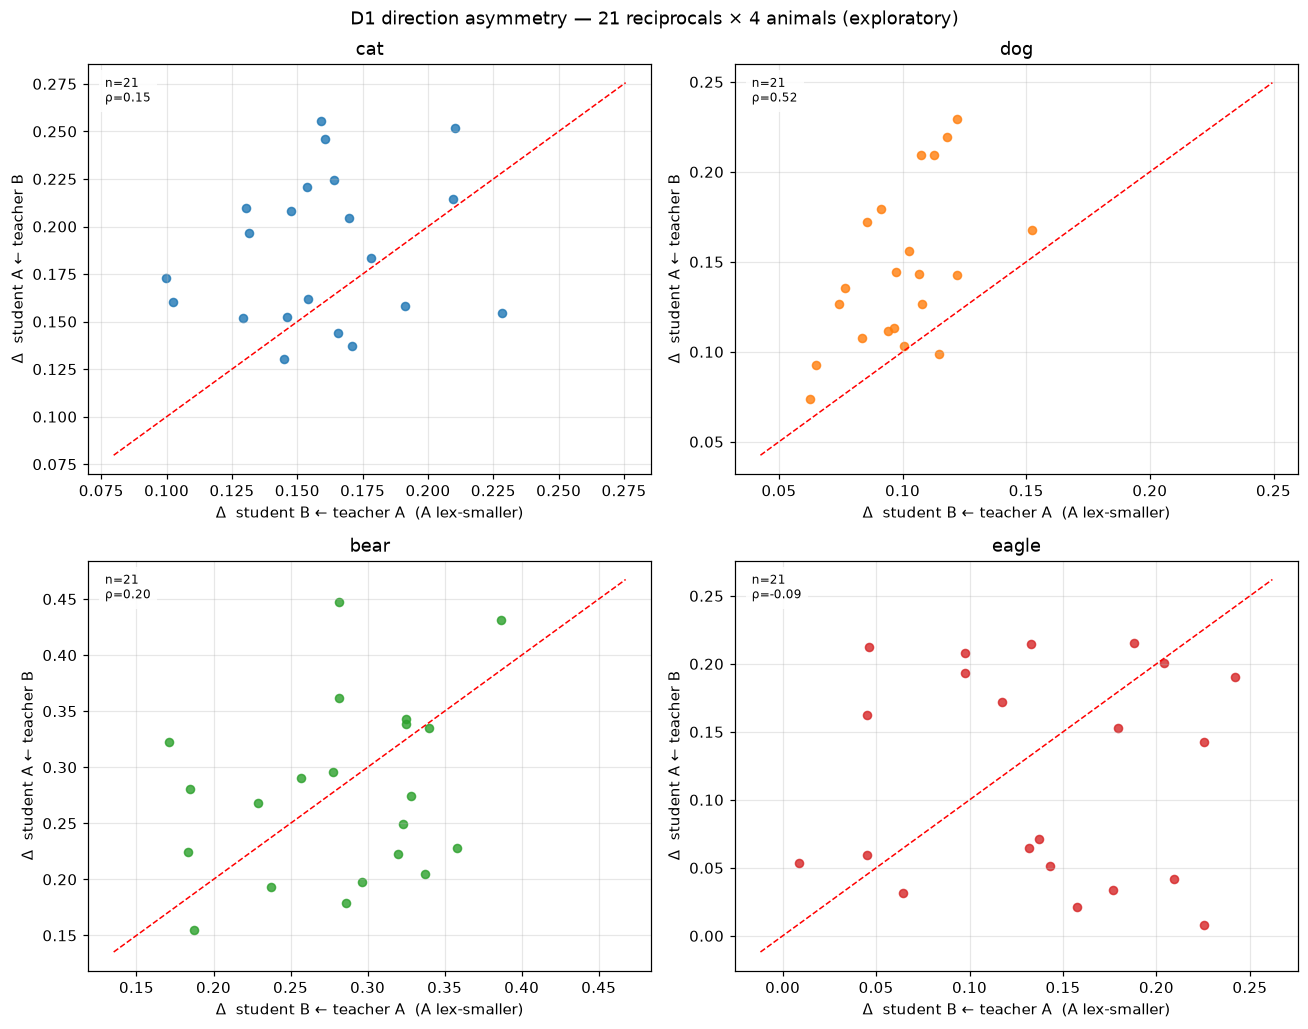

In [13]:
print("Orientation assert: decomposition cells are (teacher, student, delta).")
print(
    "CornerPair is (student, teacher). Getting this backwards is the "
    "single biggest correctness risk in §8–§11."
)
toy = [
    ("A", "A", 0.50),
    ("A", "B", 0.90),
    ("B", "A", 0.10),
    ("B", "B", 0.50),
]
toy_fit = fit_additive(toy)
print("toy emissivity:", toy_fit.emissivity)
print("toy receptivity:", toy_fit.receptivity)
if not (toy_fit.emissivity["A"] > toy_fit.emissivity["B"]):
    raise AssertionError("fit_additive orientation: expected τ_A > τ_B")
if not (toy_fit.receptivity["B"] > toy_fit.receptivity["A"]):
    raise AssertionError("fit_additive orientation: expected σ_B > σ_A")
print("Orientation OK: teacher-first cells give τ_A > τ_B and σ_B > σ_A.")

# Hand-known disk cell: data-seed1 teaching data-seed1 is same-init.
known = pd_delta[
    (pd_delta["animal"] == "cat")
    & (pd_delta["teacher_base"] == "data-seed1")
    & (pd_delta["student_base"] == "data-seed1")
]
if len(known) != 1:
    raise AssertionError(len(known))
print(
    "hand-known cat data-seed1←data-seed1 Δ:",
    float(known["subliminal_delta"].iloc[0]),
)

seed_delta = pairing_seed_deltas(pref, PRIMARY_SET)
print_scope(seed_delta, f"gseed-level paired Δ {PRIMARY_SET}")
cell_var = (
    seed_delta.groupby(["animal", "pairing"], dropna=False)["subliminal_delta"]
    .var(ddof=1)
    .dropna()
)
pooled_sd = float(np.sqrt(cell_var.mean()))
print(f"Pooled within-cell replicate SD (tfs×gseed residuals): {pooled_sd:.4f}")

d1_rows = []
for animal in ANIMALS:
    sub = pd_delta[pd_delta["animal"] == animal]
    cells = additive_cells(sub)
    contrasts = reciprocal_asymmetries(cells)
    if len(contrasts) != 21:
        raise AssertionError((animal, len(contrasts)))
    for c in contrasts:
        d1_rows.append(
            {
                "animal": animal,
                "base_a": c.base_a,
                "base_b": c.base_b,
                "delta_forward": c.delta_forward,
                "delta_reverse": c.delta_reverse,
                "asymmetry": c.asymmetry,
                "abs_asymmetry": abs(c.asymmetry),
            }
        )
d1 = pd.DataFrame(d1_rows)
print_scope(d1, "84 reciprocal contrasts (lex-smaller = base_a = forward teacher)")
if len(d1) != 84:
    raise AssertionError(len(d1))
d1_sum = (
    d1.groupby("animal")["asymmetry"]
    .agg(mean_signed="mean", mean_abs=lambda s: s.abs().mean(), n="size")
    .reindex(list(ANIMALS))
)
print("Per-animal signed / absolute asymmetry:")
display(d1_sum)
st84 = sign_test(list(d1["asymmetry"]), 0.0, "two-sided")
mean_abs = float(d1["abs_asymmetry"].mean())
print(
    f"mean |asymmetry|={mean_abs:.4f}  2×pooled_SD={2 * pooled_sd:.4f}  "
    f"exceeds={mean_abs > 2 * pooled_sd}"
)
n_rep = int(seed_delta.groupby(["animal", "pairing"]).size().min())
se_cell = pooled_sd / math.sqrt(n_rep)
se_asym = math.sqrt(2.0) * se_cell
print(
    f"Scale note: the roadmap bar is 2× the SD of a single leaf, but each Δ "
    f"cell averages {n_rep} leaves, so the noise on one asymmetry is "
    f"≈√2·SD/√{n_rep} = {se_asym:.4f} and 2× that is {2 * se_asym:.4f}. "
    "Failing the roadmap bar therefore does not mean the asymmetries are "
    "within noise; the per-contrast test below is the noise comparison."
)
print(
    f"sign test over 84 lex-oriented contrasts: "
    f"{st84.n_positive}/{st84.n_effective} p={st84.p_value:.4g} ({st84.alternative})"
)
print(
    "CAUTION: the lex orientation is not a substantive hypothesis. Labels "
    "sort data-seed* < original < weight-seed*, so lex-smaller-as-teacher "
    "is mostly data-family-as-teacher; this sign test is confounded with "
    "family ordering and is NOT evidence that direction per se matters."
)

# Orientation-free re-test: is each contrast's asymmetry larger than its
# own replicate noise? Blocks are teacher_ftseed (gseeds nested inside).
blocks = (
    seed_delta.groupby(
        ["animal", "teacher_base", "student_base", "teacher_ftseed"], dropna=False
    )["subliminal_delta"]
    .mean()
    .rename("block_delta")
    .reset_index()
)
block_lookup = {
    (a, t, s): g["block_delta"].to_numpy(dtype=float)
    for (a, t, s), g in blocks.groupby(["animal", "teacher_base", "student_base"])
}
sig_rows = []
for row in d1.itertuples(index=False):
    fwd = block_lookup[(row.animal, row.base_a, row.base_b)]
    rev = block_lookup[(row.animal, row.base_b, row.base_a)]
    if fwd.size < 2 or rev.size < 2:
        raise AssertionError((row.animal, row.base_a, row.base_b, fwd.size, rev.size))
    tt = ttest_ind(fwd, rev, equal_var=False)
    sig_rows.append(
        {
            "animal": row.animal,
            "pair": f"{row.base_a}|{row.base_b}",
            "asymmetry": row.asymmetry,
            "block_asymmetry": float(fwd.mean() - rev.mean()),
            "n_blocks": f"{fwd.size}v{rev.size}",
            "p_welch": float(tt.pvalue),
        }
    )
d1_sig = pd.DataFrame(sig_rows)
d1_sig["q_bh"] = false_discovery_control(d1_sig["p_welch"].to_numpy(), method="bh")
d1_n_sig = int((d1_sig["q_bh"] < 0.05).sum())
d1_sig_frac = d1_n_sig / len(d1_sig)
agg_gap = float((d1_sig["block_asymmetry"] - d1_sig["asymmetry"]).abs().max())
print(
    f"Block means vs headline Δ aggregation: max |diff| in asymmetry = {agg_gap:.4f} "
    "(ftseed-block mean of gseed Δ vs the loader's aggregation)"
)
print(
    f"Orientation-free per-contrast Welch test on ftseed blocks: "
    f"{d1_n_sig}/{len(d1_sig)} contrasts at BH q<0.05 ({d1_sig_frac:.3f})"
)
display(
    d1_sig.groupby("animal")
    .agg(
        n_sig=("q_bh", lambda s: int((s < 0.05).sum())),
        min_q=("q_bh", "min"),
        n=("q_bh", "size"),
    )
    .reindex(list(ANIMALS))
)
print(
    "Each contrast has 3v3 ftseed blocks (Welch df≈4), so this count is a "
    "power-limited floor on how many pairs are individually asymmetric; "
    "it is orientation-free, unlike the sign test above."
)

# Roadmap §1.3 table shape — original as teacher vs original as student.
orig_rows = []
for animal in ANIMALS:
    sub = pd_delta[pd_delta["animal"] == animal]
    as_t = sub.loc[
        (sub["teacher_base"] == "original") & (sub["student_base"] != "original"),
        "subliminal_delta",
    ]
    as_s = sub.loc[
        (sub["student_base"] == "original") & (sub["teacher_base"] != "original"),
        "subliminal_delta",
    ]
    partners = sorted(set(sub.loc[sub["teacher_base"] == "original", "student_base"]) - {"original"})
    n_pos = 0
    n_cmp = 0
    for other in partners:
        dt = sub.loc[
            (sub["teacher_base"] == "original") & (sub["student_base"] == other),
            "subliminal_delta",
        ]
        ds = sub.loc[
            (sub["student_base"] == "original") & (sub["teacher_base"] == other),
            "subliminal_delta",
        ]
        if len(dt) and len(ds):
            n_cmp += 1
            n_pos += int(float(dt.iloc[0]) > float(ds.iloc[0]))
    orig_rows.append(
        {
            "animal": animal,
            "mean_original_as_teacher": float(as_t.mean()),
            "mean_original_as_student": float(as_s.mean()),
            "difference": float(as_t.mean() - as_s.mean()),
            "ratio": float(as_t.mean() / as_s.mean()) if float(as_s.mean()) != 0 else np.nan,
            "sign": f"{n_pos}/{n_cmp}",
            "n_teacher": int(as_t.size),
            "n_student": int(as_s.size),
        }
    )
orig_tab = pd.DataFrame(orig_rows)
print(
    "Roadmap §1.3 table recomputed on the complete grid "
    "(roadmap was [verify] on the 31-pairing tier):"
)
display(orig_tab)
print(
    "Roadmap [verify] 31-pair numbers: "
    "cat 0.2143/0.1689/+0.0454/1.27×/5/6; "
    "dog 0.1466/0.1196/+0.0270/1.23×/3/6; "
    "bear 0.3782/0.1865/+0.1918/2.03×/6/6; "
    "eagle 0.1573/0.0230/+0.1343/6.84×/6/6; "
    "pooled 0.2241/0.1245/+0.0996/1.80×/20/24."
)
print("Agreement is a printed comparison, not an edit of the roadmap.")

fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = d1[d1["animal"] == animal]
    aplots.identity_scatter(
        ax,
        sub,
        "delta_forward",
        "delta_reverse",
        stat="spearman",
        diag_lim=(
            float(min(sub["delta_forward"].min(), sub["delta_reverse"].min())) - 0.02,
            float(max(sub["delta_forward"].max(), sub["delta_reverse"].max())) + 0.02,
        )
        if len(sub)
        else (0.0, 1.0),
        color=ANIMAL_COLORS[animal],
        s=28,
        alpha=0.8,
        title_stats=True,
        textbox=True,
    )
    ax.set_title(animal)
    ax.set_xlabel("Δ  student B ← teacher A  (A lex-smaller)")
    ax.set_ylabel("Δ  student A ← teacher B")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("D1 direction asymmetry — 21 reciprocals × 4 animals (exploratory)")
plt.tight_layout()
plt.show()


@g
**What this measures.** Fit `Δ_ij = μ + τ_i + σ_j` per animal
(`analysis.decomposition.fit_additive`; cells are
**(teacher, student, delta)**). In-sample R², τ/σ ranks, residual
heatmap overlaid on the 7×7, leave-one-reciprocal-pair-out CV, and a
pairing-cluster bootstrap CI on pooled `interaction`.

**Claim D2 (roadmap §4, verbatim):** Leave-one-reciprocal-pair-out CV of
the additive model. If held-out R² ≥ 0.85 **and** the pooled ι CI
covers 0 → conclude the asymmetry is **compositional** (separable
emissivity/receptivity). If ι CI excludes 0 at ≥0.05 absolute →
conclude a genuine **directional interaction**. Anything else →
inconclusive; report both models.

In-sample `interaction` on a complete grid is weak evidence (near-zero
by construction on additive data). The held-out CV is the honest test.
**Exploratory / post-hoc.**


cat: in-sample R²=0.842 n=49  held-out R²=0.738 Pearson=0.873 sign_agree=1.000 MAE=0.015 n_folds=21
  predict original←original: 0.1807
dog: in-sample R²=0.889 n=49  held-out R²=0.873 Pearson=0.942 sign_agree=0.905 MAE=0.011 n_folds=21
  predict original←original: 0.1434
bear: in-sample R²=0.839 n=49  held-out R²=0.742 Pearson=0.872 sign_agree=0.810 MAE=0.028 n_folds=21
  predict original←original: 0.2856
eagle: in-sample R²=0.806 n=49  held-out R²=0.880 Pearson=0.950 sign_agree=0.952 MAE=0.020 n_folds=21
  predict original←original: 0.0484
τ / σ ranks:


,base,emissivity,receptivity,emissivity_rank,receptivity_rank,animal
14,original,0.059885,-0.052061,1.0,6.0,bear
15,weight-seed1,0.048781,0.058145,2.0,2.0,bear
16,data-seed1,0.044050,0.092431,3.0,1.0,bear
17,data-seed2,0.000389,-0.031526,4.0,5.0,bear
18,weight-seed2,-0.034924,-0.004919,5.0,3.0,bear
19,weight-seed3,-0.044149,-0.006223,6.0,4.0,bear
20,data-seed3,-0.074032,-0.055847,7.0,7.0,bear
0,original,0.031209,-0.021628,1.0,5.0,cat
1,data-seed1,0.012019,0.050567,2.0,1.0,cat
2,weight-seed2,0.010556,-0.030229,3.0,7.0,cat


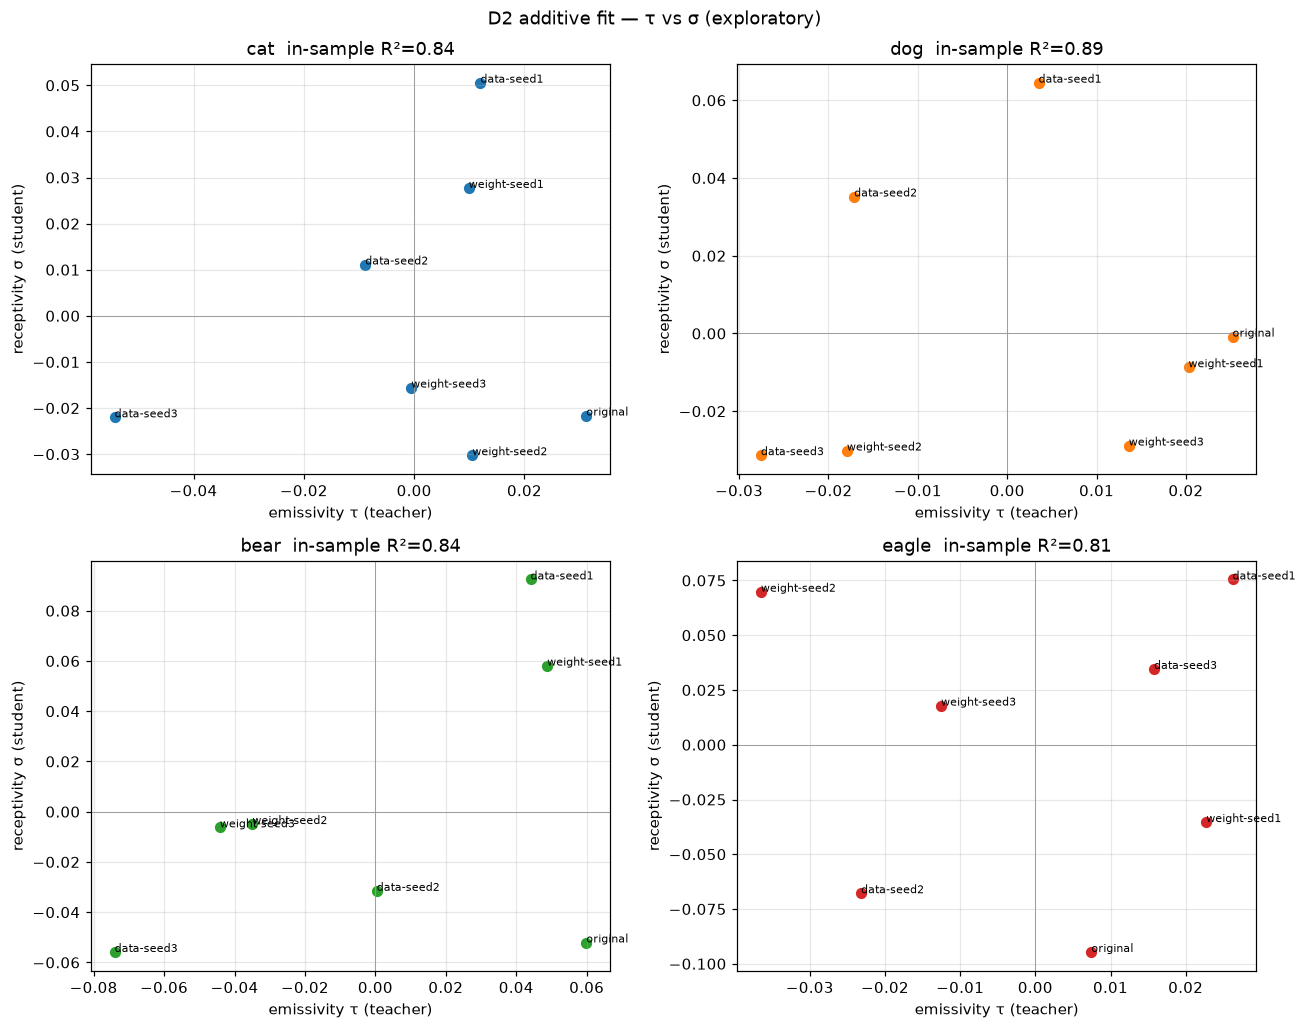

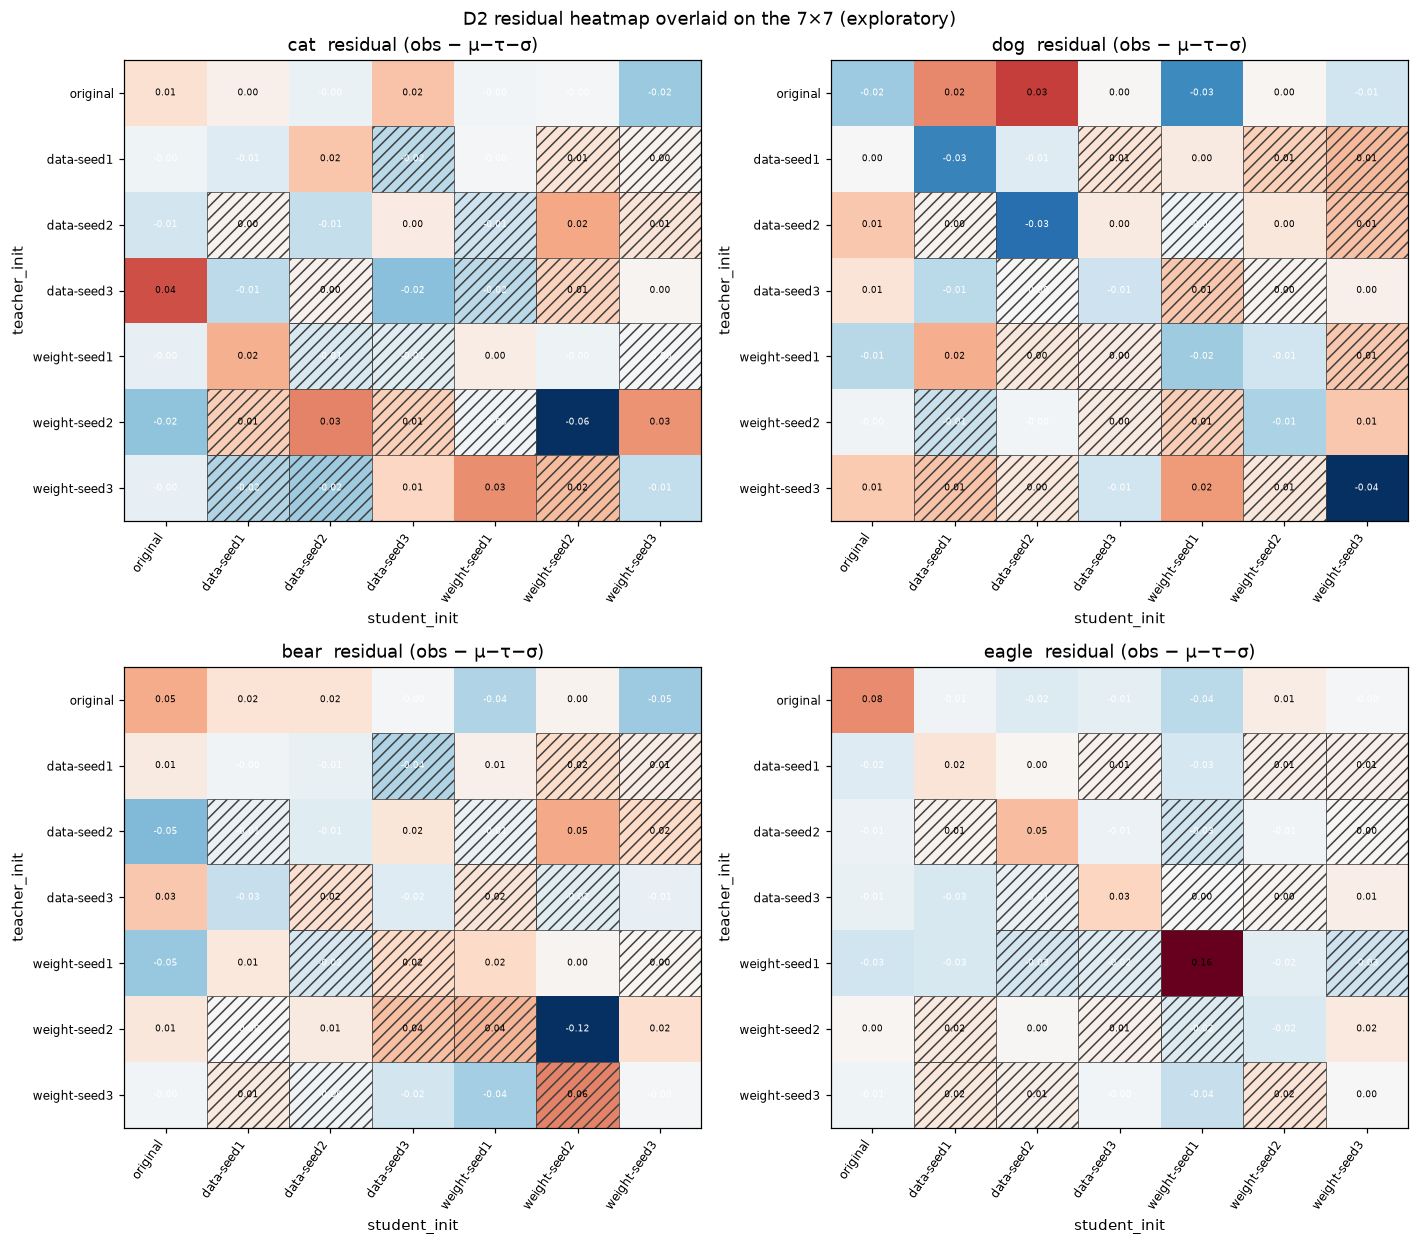

In [14]:
fits: dict[str, Any] = {}
held: dict[str, Any] = {}
role_frames = []
resid_rows = []
for animal in ANIMALS:
    sub = pd_delta[pd_delta["animal"] == animal]
    cells = additive_cells(sub)
    if len(cells) != 49:
        raise AssertionError((animal, len(cells)))
    fit = fit_additive(cells)
    ho = leave_one_reciprocal_pair_out(cells)
    fits[animal] = fit
    held[animal] = ho
    roles = role_effects_frame(fit).assign(animal=animal)
    role_frames.append(roles)
    for (t, s), r in fit.residuals.items():
        resid_rows.append(
            {"animal": animal, "teacher_base": t, "student_base": s, "residual": r}
        )
    print(
        f"{animal}: in-sample R²={fit.r_squared:.3f} n={fit.n_obs}  "
        f"held-out R²={ho.r_squared:.3f} Pearson={ho.pearson:.3f} "
        f"sign_agree={ho.sign_agreement:.3f} MAE={ho.mean_absolute_error:.3f} "
        f"n_folds={ho.n_folds}"
    )
    pred_aa = predict_additive(fit, "original", "original")
    print(f"  predict original←original: {pred_aa:.4f}")

roles = pd.concat(role_frames, ignore_index=True)
resid = pd.DataFrame(resid_rows)
print("τ / σ ranks:")
display(roles.sort_values(["animal", "emissivity_rank"]))

fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = roles[roles["animal"] == animal]
    ax.scatter(sub["emissivity"], sub["receptivity"], color=ANIMAL_COLORS[animal], s=40)
    for _, row in sub.iterrows():
        ax.annotate(row["base"], (row["emissivity"], row["receptivity"]), fontsize=7)
    ax.axhline(0, color="0.6", lw=0.6)
    ax.axvline(0, color="0.6", lw=0.6)
    ax.set_xlabel("emissivity τ (teacher)")
    ax.set_ylabel("receptivity σ (student)")
    ax.set_title(f"{animal}  in-sample R²={fits[animal].r_squared:.2f}")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("D2 additive fit — τ vs σ (exploratory)")
plt.tight_layout()
plt.show()

fig, axes = animal_axes(figsize=(13.0, 11.5))
for ax, animal in zip(axes, ANIMALS):
    sub = resid[resid["animal"] == animal]
    g = (
        sub.pivot_table(
            index="teacher_base",
            columns="student_base",
            values="residual",
            aggfunc="mean",
        )
        .reindex(index=BASE_ORDER, columns=BASE_ORDER)
    )
    lim = float(np.nanmax(np.abs(g.to_numpy()))) if np.isfinite(g.to_numpy()).any() else 0.1
    aplots.annotated_heatmap(
        ax,
        g,
        cmap="RdBu_r",
        vmin=-lim,
        vmax=lim,
        fmt="{:.2f}",
        origin="upper",
        mid=0.0,
        cell_fontsize=6.0,
        empty_facecolor="#f4f4f4",
    )
    hatch_b6_new_cells(ax, list(g.index), list(g.columns))
    ax.set_title(f"{animal}  residual (obs − μ−τ−σ)")
    ax.set_xlabel("student_init")
    ax.set_ylabel("teacher_init")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("D2 residual heatmap overlaid on the 7×7 (exploratory)")
plt.tight_layout()
plt.show()


In [15]:
inter_rows = []
for animal in ANIMALS:
    cells = additive_cells(pd_delta[pd_delta["animal"] == animal])
    for c in reciprocal_asymmetries(cells, fits[animal]):
        inter_rows.append(
            {
                "animal": animal,
                "pair": f"{c.base_a}|{c.base_b}",
                "interaction": c.interaction,
                "asymmetry": c.asymmetry,
                "additive_asymmetry": c.additive_asymmetry,
            }
        )
inter = pd.DataFrame(inter_rows)
print_scope(inter, "reciprocal interaction ι = asymmetry − additive_asymmetry")
print("Per-animal mean ι:")
display(inter.groupby("animal")["interaction"].agg(["mean", "std", "count"]).reindex(list(ANIMALS)))

arr = inter["interaction"].to_numpy(dtype=float)
iota_ci = astats.cluster_bootstrap(
    lambda idx: float(np.mean(arr[idx])),
    np.zeros(arr.size, dtype=int),
    inter["pair"].to_numpy(),
    n_boot=N_BOOT,
    seed=BOOTSTRAP_SEED,
)
print(
    f"Pooled interaction (clustered on unordered base pair): "
    f"{iota_ci.estimate:.4f} CI[{iota_ci.ci_low:.4f}, {iota_ci.ci_high:.4f}] "
    f"p_boot={iota_ci.p_boot:.4g}"
)
covers0 = iota_ci.ci_low <= 0.0 <= iota_ci.ci_high
excl_005 = (iota_ci.ci_low > 0.05) or (iota_ci.ci_high < -0.05)
print(f"ι CI covers 0: {covers0}; excludes 0 at ≥0.05 absolute: {excl_005}")
print(
    "D2 rule: held-out R² ≥ 0.85 AND covers0 → compositional; "
    "excl_005 → directional interaction; else inconclusive. Exploratory."
)
for animal in ANIMALS:
    print(
        f"  {animal} held-out R²={held[animal].r_squared:.3f} "
        f"(≥0.85: {held[animal].r_squared >= 0.85})"
    )


SCOPE: 84 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | reciprocal interaction ι = asymmetry − additive_asymmetry
Per-animal mean ι:


,mean,std,count
animal,,,
cat,0.000111,0.014187,21
dog,-0.001846,0.012432,21
bear,-0.004427,0.030883,21
eagle,0.001717,0.011695,21


Pooled interaction (clustered on unordered base pair): -0.0011 CI[-0.0055, 0.0033] p_boot=0.6352
ι CI covers 0: True; excludes 0 at ≥0.05 absolute: False
D2 rule: held-out R² ≥ 0.85 AND covers0 → compositional; excl_005 → directional interaction; else inconclusive. Exploratory.
  cat held-out R²=0.738 (≥0.85: False)
  dog held-out R²=0.873 (≥0.85: True)
  bear held-out R²=0.742 (≥0.85: False)
  eagle held-out R²=0.880 (≥0.85: True)


### 9b. Robustness — off-diagonal-only fit (42 cells)

The 7 diagonal cells are the **same-init** condition (`SI∩SS`), a
different experimental condition from cross-init transfer, and they sit
at the top of the Δ range. Pooling them with the 42 cross-init cells
lets them pull μ, τ and σ. This refits on the 42 off-diagonal cells
only, then extrapolates to the diagonal: if the same-init cells are
just "high τ meets high σ", the extrapolation error is small and
centred on 0; a systematic positive gap means same-init transfer beats
what separable emissivity/receptivity predicts.

τ/σ rank agreement between the two fits also says whether the D2 role
ordering is an artifact of including the diagonal. **Exploratory.**


In [16]:
off_rows = []
diag_gap_rows = []
for animal in ANIMALS:
    cells = additive_cells(pd_delta[pd_delta["animal"] == animal])
    observed = {(t, s): d for t, s, d in cells}
    off = [(t, s, d) for t, s, d in cells if t != s]
    if len(off) != 42:
        raise AssertionError((animal, len(off)))
    fit_off = fit_additive(off)
    ho_off = leave_one_reciprocal_pair_out(off)
    full = fits[animal]
    rho_tau = spearmanr(
        [full.emissivity[b] for b in BASE_ORDER],
        [fit_off.emissivity[b] for b in BASE_ORDER],
    ).statistic
    rho_sigma = spearmanr(
        [full.receptivity[b] for b in BASE_ORDER],
        [fit_off.receptivity[b] for b in BASE_ORDER],
    ).statistic
    for base in BASE_ORDER:
        diag_gap_rows.append(
            {
                "animal": animal,
                "base": base,
                "observed": observed[(base, base)],
                "predicted_offdiag_fit": predict_additive(fit_off, base, base),
                "gap": observed[(base, base)] - predict_additive(fit_off, base, base),
            }
        )
    off_rows.append(
        {
            "animal": animal,
            "r2_full_49": full.r_squared,
            "r2_offdiag_42": fit_off.r_squared,
            "heldout_r2_full": held[animal].r_squared,
            "heldout_r2_offdiag": ho_off.r_squared,
            "spearman_tau": float(rho_tau),
            "spearman_sigma": float(rho_sigma),
        }
    )
off_tab = pd.DataFrame(off_rows)
print("Off-diagonal-only (42-cell) refit vs the full 49-cell fit:")
display(off_tab)

diag_gap = pd.DataFrame(diag_gap_rows)
print_scope(diag_gap, "same-init extrapolation error (observed − off-diagonal fit)")
display(
    diag_gap.groupby("animal")["gap"]
    .agg(["mean", "min", "max", "count"])
    .reindex(list(ANIMALS))
)
gap_ci = pairing_cluster_ci(diag_gap["gap"])
print(
    f"Pooled same-init extrapolation gap: {gap_ci.estimate:.4f} "
    f"CI[{gap_ci.ci_low:.4f}, {gap_ci.ci_high:.4f}] n={len(diag_gap)}"
)
gap_excludes_zero = not (gap_ci.ci_low <= 0.0 <= gap_ci.ci_high)
print(
    "CI excludes 0: "
    f"{gap_excludes_zero} — if True and positive, same-init transfer exceeds "
    "the separable τ+σ prediction, i.e. the diagonal is its own condition "
    "and should not be pooled into the D2 fit."
)
display(
    diag_gap.pivot_table(index="base", columns="animal", values="gap").reindex(
        index=BASE_ORDER, columns=list(ANIMALS)
    )
)


Off-diagonal-only (42-cell) refit vs the full 49-cell fit:


,animal,r2_full_49,r2_offdiag_42,heldout_r2_full,heldout_r2_offdiag,spearman_tau,spearman_sigma
0,cat,0.841831,0.877142,0.737907,0.733265,0.964286,0.892857
1,dog,0.889030,0.943944,0.873145,0.880338,1.000000,1.000000
2,bear,0.839089,0.893492,0.742239,0.774164,0.964286,0.964286
3,eagle,0.805679,0.984856,0.880083,0.967807,0.857143,0.964286


SCOPE: 28 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | same-init extrapolation error (observed − off-diagonal fit)


,mean,min,max,count
animal,,,,
cat,-0.017036,-0.075758,0.015279,7
dog,-0.026386,-0.055243,-0.007356,7
bear,-0.015345,-0.170703,0.066996,7
eagle,0.053234,-0.045191,0.215749,7


Pooled same-init extrapolation gap: -0.0014 CI[-0.0240, 0.0235] n=28
CI excludes 0: False — if True and positive, same-init transfer exceeds the separable τ+σ prediction, i.e. the diagonal is its own condition and should not be pooled into the D2 fit.


animal,cat,dog,bear,eagle
base,,,,
original,0.015279,-0.016769,0.066996,0.097119
data-seed1,-0.006649,-0.035074,-0.003563,0.017694
data-seed2,-0.015715,-0.040365,-0.017752,0.059062
data-seed3,-0.029736,-0.007356,-0.018971,0.038043
weight-seed1,0.009385,-0.016093,0.036124,0.215749
weight-seed2,-0.075758,-0.013803,-0.170703,-0.045191
weight-seed3,-0.016058,-0.055243,0.000454,-0.009840


## 10. Teacher-strength confound (D3)

**What this measures.** Spearman correlation between the teacher
`p_target` advantage and the Δ advantage over the 84 reciprocal
contrasts, plus the subset where the `original`-side teacher is weaker.
Teacher `p_target` is SDF `favorite` at `TEACHER_PARAM_TAG_LORA`
(`ep5_lr5e-5_r128a128`); the teacher tree also holds HP leftovers and
the `dog` directory is a resolving symlink to a larger sweep — without
that filter, legacy cells leak in. The teacher side has no `test` set.

**Claim D3 (roadmap §4, verbatim):** Spearman(teacher `p_target`
advantage, Δ advantage) CI covers 0 or is negative, over all 84
contrasts.

**Exploratory / post-hoc.**


Teacher tree: /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260809_breadth4-teachers_160m dog symlink: True
  dog resolves to /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/20260726_crossinit_160m/dog
  Filter param_tag == TEACHER_PARAM_TAG_LORA strictly; extra legacy full-FT / other-tag cells exist behind the symlink.
teacher preference: 2496 rows in 0.3s
SCOPE: 28 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | T1 teacher favorite p_target (animal × init)
Teacher strength (favorite, mean over ftseeds):


animal,cat,dog,bear,eagle
teacher_base,,,,
original,0.092893,0.091781,0.260051,0.118189
data-seed1,0.155614,0.105427,0.307197,0.277680
data-seed2,0.082006,0.140078,0.254134,0.233686
data-seed3,0.059245,0.048107,0.116601,0.209758
weight-seed1,0.142208,0.061765,0.292256,0.279528
weight-seed2,0.102674,0.078872,0.164494,0.243364
weight-seed3,0.118962,0.068968,0.221485,0.220415


Teacher favorite table matches the verified snapshot to 1e-3.
original teacher rank (1 = highest p_target) vs roadmap §1.3:
  cat: 5 of 7  (roadmap 5 — MATCH)
  dog: 3 of 7  (roadmap 3 — MATCH)
  bear: 3 of 7  (roadmap 3 — MATCH)
  eagle: 7 of 7  (roadmap 7 — MATCH)
D3 Spearman(teacher_adv, Δ_adv) over 84: ρ=-0.180 p=0.1008 boot CI[-0.363, 0.017]
Pairs where original-side teacher is weaker: n=14  mean Δ advantage (orig as teacher − orig as student)=0.1029  n_pos=14/14


,animal,other,teacher_adv_orig,delta_adv_orig_as_t
0,cat,data-seed1,-0.062721,0.096616
1,cat,weight-seed1,-0.049315,0.073716
2,cat,weight-seed2,-0.009781,0.033771
3,cat,weight-seed3,-0.026069,0.021460
4,dog,data-seed1,-0.013646,0.107686
5,dog,data-seed2,-0.048297,0.096631
6,bear,data-seed1,-0.047146,0.166235
7,bear,weight-seed1,-0.032205,0.130360
8,eagle,data-seed1,-0.159490,0.166379
9,eagle,data-seed2,-0.115497,0.044976


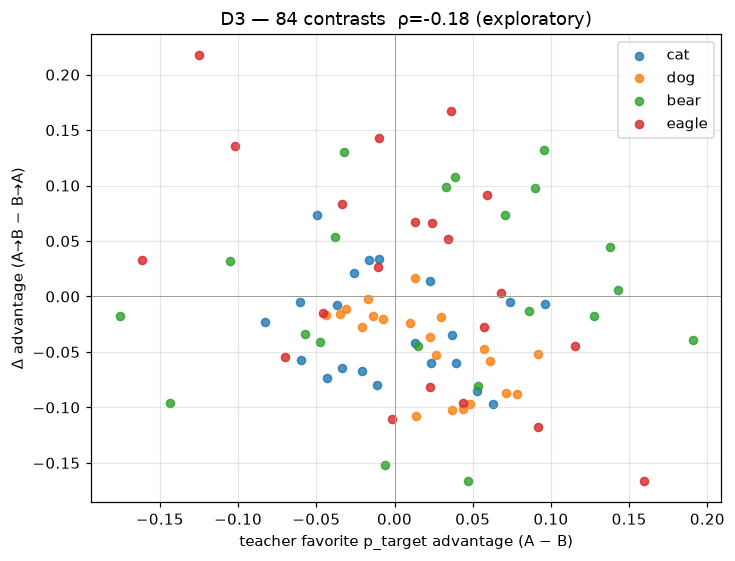

In [17]:
print("Teacher tree:", TEACHER_TREE, "dog symlink:", (TEACHER_TREE / "dog").is_symlink())
if (TEACHER_TREE / "dog").is_symlink():
    print("  dog resolves to", (TEACHER_TREE / "dog").resolve())
    print(
        "  Filter param_tag == TEACHER_PARAM_TAG_LORA strictly; extra legacy "
        "full-FT / other-tag cells exist behind the symlink."
    )

t0 = time.perf_counter()
tpref = load_sdf_preference_results(OUTPUT_ROOT, subdir=TEACHER_SUBDIR)
print(f"teacher preference: {len(tpref)} rows in {time.perf_counter() - t0:.1f}s")
if "dog" not in set(tpref["animal"]) and (TEACHER_TREE / "dog").exists():
    src = (TEACHER_TREE / "dog").resolve()
    alt_sub = str(src.parent.relative_to(OUTPUT_ROOT))
    print(f"dog missing from default glob; reloading via {alt_sub}")
    dog_pref = load_sdf_preference_results(
        OUTPUT_ROOT, subdir=alt_sub, animals=["dog"]
    )
    tpref = pd.concat([tpref, dog_pref], ignore_index=True)

tpref_f = tpref[
    (tpref["param_tag"] == TEACHER_PARAM_TAG_LORA) & (tpref["set"] == "favorite")
].copy()
tpref_f["teacher_base"] = tpref_f["model"].map(MODEL_TO_LABEL)
if tpref_f["teacher_base"].isna().any():
    raise ValueError(
        f"unmapped teacher models: {sorted(tpref_f.loc[tpref_f.teacher_base.isna(), 'model'].unique())}"
    )
teacher_28 = (
    tpref_f.groupby(["animal", "teacher_base"], dropna=False)
    .agg(teacher_p_target=("p_target", "mean"), n_seeds=("n_seeds", "first"))
    .reset_index()
)
print_scope(teacher_28, "T1 teacher favorite p_target (animal × init)")
teacher_wide = (
    teacher_28.pivot(index="teacher_base", columns="animal", values="teacher_p_target")
    .reindex(index=BASE_ORDER, columns=list(ANIMALS))
)
print("Teacher strength (favorite, mean over ftseeds):")
display(teacher_wide)
for base, expected in TEACHER_FAVORITE_EXPECTED.items():
    for animal, exp in expected.items():
        got = float(teacher_wide.loc[base, animal])
        if abs(got - exp) > 1e-3:
            raise AssertionError(f"{base} {animal}: {got:.4f} != {exp:.4f}")
print("Teacher favorite table matches the verified snapshot to 1e-3.")

print("original teacher rank (1 = highest p_target) vs roadmap §1.3:")
rank_rows = []
for animal in ANIMALS:
    s = teacher_wide[animal]
    ranks = s.rank(ascending=False, method="min")
    got = int(ranks.loc["original"])
    exp = ORIGINAL_TEACHER_RANK_ROADMAP[animal]
    rank_rows.append({"animal": animal, "rank": got, "roadmap": exp, "agree": got == exp})
    print(f"  {animal}: {got} of 7  (roadmap {exp}{' — MATCH' if got == exp else ' — DISAGREES'})")
orig_ranks = pd.DataFrame(rank_rows)

# 84-contrast teacher advantage vs Δ advantage.
t_map = teacher_28.set_index(["animal", "teacher_base"])["teacher_p_target"]
d3 = d1.copy()
d3["teacher_adv"] = [
    float(t_map[(a, ba)] - t_map[(a, bb)])
    for a, ba, bb in zip(d3["animal"], d3["base_a"], d3["base_b"])
]
d3["delta_adv"] = d3["asymmetry"]
rho84, p84 = spearmanr(d3["teacher_adv"], d3["delta_adv"])
arr_x = d3["teacher_adv"].to_numpy(dtype=float)
arr_y = d3["delta_adv"].to_numpy(dtype=float)
d3_ci = astats.cluster_bootstrap(
    lambda idx: float(spearmanr(arr_x[idx], arr_y[idx]).statistic),
    np.zeros(arr_x.size, dtype=int),
    d3["base_a"].str.cat(d3["base_b"], sep="|").to_numpy(),
    n_boot=N_BOOT,
    seed=BOOTSTRAP_SEED,
)
print(
    f"D3 Spearman(teacher_adv, Δ_adv) over 84: ρ={rho84:.3f} p={p84:.4g} "
    f"boot CI[{d3_ci.ci_low:.3f}, {d3_ci.ci_high:.3f}]"
)

# Subset: original-side teacher is weaker.
weak = []
for animal in ANIMALS:
    sub = pd_delta[pd_delta["animal"] == animal]
    for other in [b for b in BASE_ORDER if b != "original"]:
        p_orig = float(t_map[(animal, "original")])
        p_oth = float(t_map[(animal, other)])
        d_orig_as_t = float(
            sub.loc[
                (sub["teacher_base"] == "original") & (sub["student_base"] == other),
                "subliminal_delta",
            ].iloc[0]
        )
        d_orig_as_s = float(
            sub.loc[
                (sub["student_base"] == "original") & (sub["teacher_base"] == other),
                "subliminal_delta",
            ].iloc[0]
        )
        if p_orig < p_oth:
            weak.append(
                {
                    "animal": animal,
                    "other": other,
                    "teacher_adv_orig": p_orig - p_oth,
                    "delta_adv_orig_as_t": d_orig_as_t - d_orig_as_s,
                }
            )
weak_df = pd.DataFrame(weak)
print(
    f"Pairs where original-side teacher is weaker: n={len(weak_df)}  "
    f"mean Δ advantage (orig as teacher − orig as student)="
    f"{weak_df['delta_adv_orig_as_t'].mean() if len(weak_df) else float('nan'):.4f}  "
    f"n_pos="
    f"{int((weak_df['delta_adv_orig_as_t'] > 0).sum()) if len(weak_df) else 0}/{len(weak_df)}"
)
display(weak_df)

fig, ax = plt.subplots(figsize=(6.8, 5.2))
for animal in ANIMALS:
    sub = d3[d3["animal"] == animal]
    ax.scatter(
        sub["teacher_adv"],
        sub["delta_adv"],
        color=ANIMAL_COLORS[animal],
        label=animal,
        s=28,
        alpha=0.8,
    )
ax.axhline(0, color="0.6", lw=0.6)
ax.axvline(0, color="0.6", lw=0.6)
ax.legend()
ax.set_xlabel("teacher favorite p_target advantage (A − B)")
ax.set_ylabel("Δ advantage (A→B − B→A)")
ax.set_title(f"D3 — 84 contrasts  ρ={rho84:.2f} (exploratory)")
plt.tight_layout()
plt.show()


## 11. Receptivity predictor (D4)

**What this measures.** Student receptivity `σ_j` versus the base's own
SDF teacher `favorite` `p_target`, per animal and pooled, with a
pairing-cluster CI. Competing predictors: control-floor and the
untuned-base prior (`base_p_target` on the student preference summary,
and teacher-tree `base_control.json` `favorite.p_target`).

The roadmap's `teachers/animal_selection` curated scores are **not on
disk**. This notebook does not call `analysis.animals.*` and does not
fabricate those scores.

**Claim D4 (roadmap §4, verbatim):** σ_j correlates with the base's own
trait affinity (its SDF teacher `p_target` on `favorite`) at ρ > 0.5,
pooled over animals, with the CI excluding 0.

**Exploratory / post-hoc.**


animal_selection artifact present on checked paths:
  /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/teachers/animal_selection: False
  /home/vishesh/eleutherAI/EleutherAI_subliminal_learning/teachers/animal_selection: False
  /home/vishesh/eleutherAI/EleutherAI_subliminal_learning/data/animal_selection: False
ABSENT: the curated teachers/animal_selection scores are not on disk (checked in-repo and the hot output_root). Untuned-prior panels below use teacher-tree base_control.json favorite.p_target and the student preference `base_p_target` column — labelled as such.
teacher-tree base_control.json: 28/28
SCOPE: 28 configs | 4 animal(s) x 0 base model(s) | seeds pre-averaged | receptivity vs competing predictors (7 bases × 4 animals)


,animal,base,receptivity,emissivity,teacher_p_target,untuned_favorite_p,student_base_p_target,control_floor
0,cat,original,-0.021628,0.031209,0.092893,0.003633,0.003341,0.002628
1,cat,data-seed1,0.050567,0.012019,0.155614,0.004843,0.004770,0.003504
2,cat,weight-seed2,-0.030229,0.010556,0.102674,0.007434,0.007438,0.007497
3,cat,weight-seed1,0.027746,0.009905,0.142208,0.005293,0.005594,0.004437
4,cat,weight-seed3,-0.015558,-0.000531,0.118962,0.003697,0.003569,0.003209
5,cat,data-seed2,0.011127,-0.008862,0.082006,0.005785,0.005798,0.004360
6,cat,data-seed3,-0.022025,-0.054295,0.059245,0.004464,0.004817,0.004193
7,dog,original,-0.000815,0.025217,0.091781,0.009631,0.009627,0.008365
8,dog,weight-seed1,-0.008687,0.020289,0.061765,0.006125,0.007680,0.006829
9,dog,weight-seed3,-0.028844,0.013608,0.068968,0.006399,0.006657,0.006524


Spearman(σ, predictor) per animal / pooled:
  own SDF teacher favorite p_target / cat: ρ=0.643 p=0.119 CI[-0.269, 1.000] n=7
  own SDF teacher favorite p_target / dog: ρ=0.821 p=0.0234 CI[-0.087, 1.000] n=7
  own SDF teacher favorite p_target / bear: ρ=0.643 p=0.119 CI[-0.222, 1.000] n=7
  own SDF teacher favorite p_target / eagle: ρ=0.429 p=0.337 CI[-0.647, 1.000] n=7
  own SDF teacher favorite p_target / pooled: ρ=0.274 p=0.159 CI[-0.147, 0.650] n=28
  GKD control floor / cat: ρ=-0.143 p=0.76 CI[-0.887, 0.961] n=7
  GKD control floor / dog: ρ=0.429 p=0.337 CI[-0.647, 1.000] n=7
  GKD control floor / bear: ρ=0.643 p=0.119 CI[-0.348, 1.000] n=7
  GKD control floor / eagle: ρ=0.679 p=0.0938 CI[-0.148, 1.000] n=7
  GKD control floor / pooled: ρ=0.189 p=0.336 CI[-0.240, 0.561] n=28
  student preference base_p_target (untuned) / cat: ρ=-0.179 p=0.702 CI[-1.000, 0.867] n=7
  student preference base_p_target (untuned) / dog: ρ=0.286 p=0.535 CI[-0.647, 1.000] n=7
  student preference base_p_t

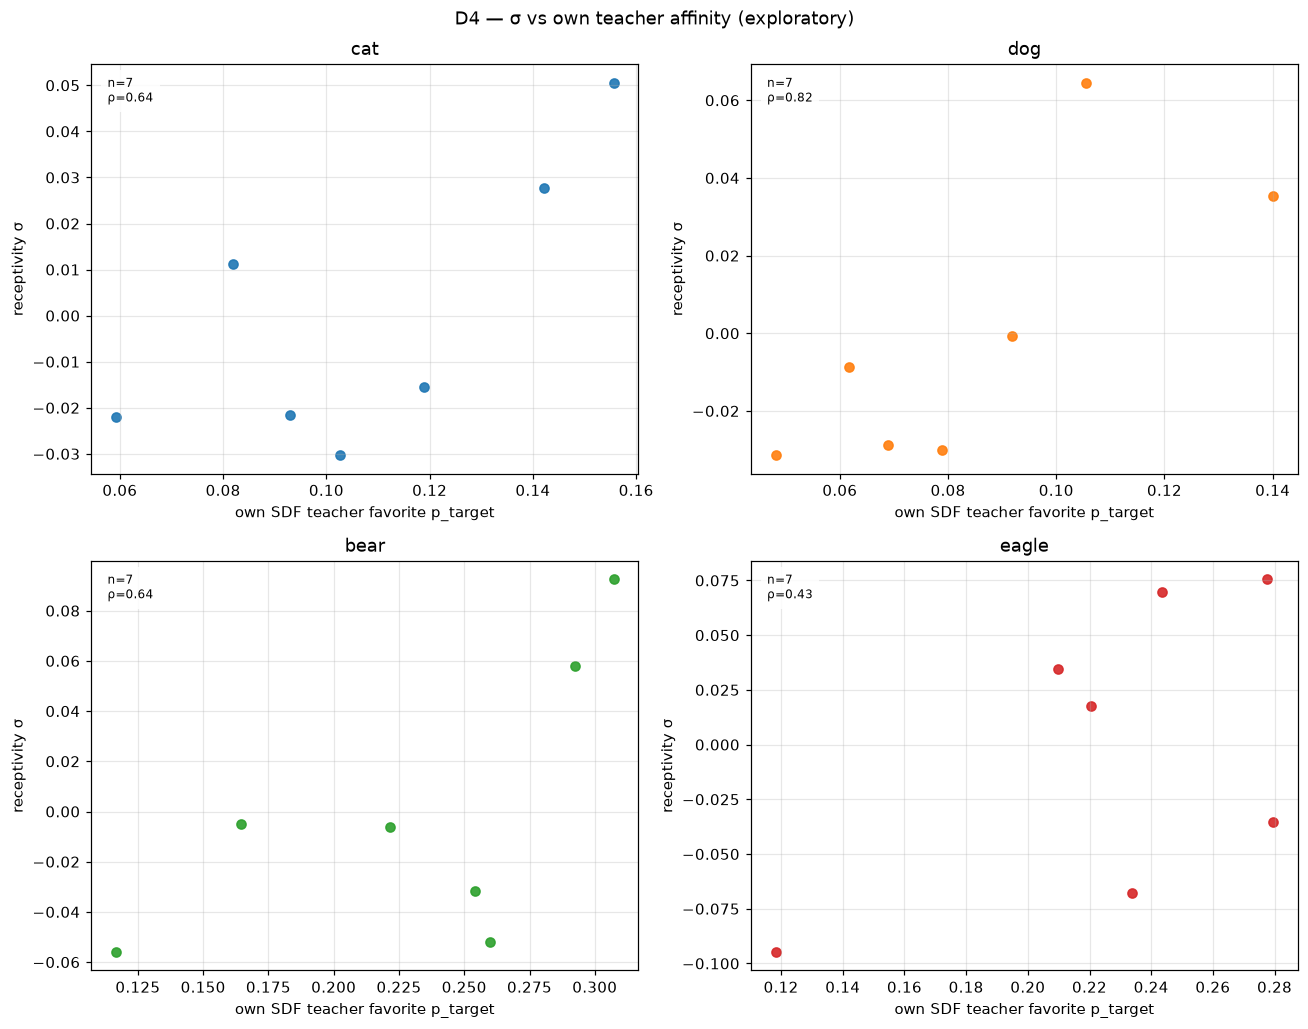

In [18]:
sel_guesses = [
    OUTPUT_ROOT / "teachers" / "animal_selection",
    ROOT / "teachers" / "animal_selection",
    ROOT / "data" / "animal_selection",
]
print("animal_selection artifact present on checked paths:")
for p in sel_guesses:
    print(f"  {p}: {p.exists()}")
print(
    "ABSENT: the curated teachers/animal_selection scores are not on disk "
    "(checked in-repo and the hot output_root). Untuned-prior panels below "
    "use teacher-tree base_control.json favorite.p_target and the student "
    "preference `base_p_target` column — labelled as such."
)

# Untuned prior from teacher-tree base_control.json (28/28).
base_ctrl_rows = []
for animal in ANIMALS:
    for label, model in LABEL_TO_MODEL.items():
        path = TEACHER_TREE / animal / model / "base_control.json"
        if not path.is_file():
            continue
        doc = json.loads(path.read_text())
        fav = doc.get("favorite") or {}
        base_ctrl_rows.append(
            {
                "animal": animal,
                "base": label,
                "untuned_favorite_p": fav.get("p_target"),
            }
        )
base_ctrl = pd.DataFrame(base_ctrl_rows)
print("teacher-tree base_control.json:", f"{len(base_ctrl)}/28")
if len(base_ctrl) != 28:
    raise AssertionError(len(base_ctrl))

# Student preference untuned prior (mean over configs of base_p_target on test).
untuned_student = (
    annotate_pairing(pref[(~pref["is_control"]) & (pref["set"] == PRIMARY_SET)].copy())
    .groupby(["animal", "student_base"], dropna=False)["base_p_target"]
    .mean()
    .reset_index()
    .rename(columns={"student_base": "base", "base_p_target": "student_base_p_target"})
)
floor_by_base = (
    ctrl_pref.groupby(["animal", "student_base"], dropna=False)["p_target"]
    .mean()
    .reset_index()
    .rename(columns={"student_base": "base", "p_target": "control_floor"})
)

pred = roles.rename(columns={"base": "base"})[
    ["animal", "base", "receptivity", "emissivity"]
].merge(
    teacher_28.rename(columns={"teacher_base": "base"})[
        ["animal", "base", "teacher_p_target"]
    ],
    on=["animal", "base"],
    how="left",
)
pred = pred.merge(base_ctrl, on=["animal", "base"], how="left")
pred = pred.merge(untuned_student, on=["animal", "base"], how="left")
pred = pred.merge(floor_by_base, on=["animal", "base"], how="left")
print_scope(pred, "receptivity vs competing predictors (7 bases × 4 animals)")
display(pred)

print("Spearman(σ, predictor) per animal / pooled:")
d4_rows = []
for pred_col, name in (
    ("teacher_p_target", "own SDF teacher favorite p_target"),
    ("control_floor", "GKD control floor"),
    ("student_base_p_target", "student preference base_p_target (untuned)"),
    ("untuned_favorite_p", "teacher-tree base_control.json favorite.p_target"),
):
    for animal in (*ANIMALS, "pooled"):
        sub = pred if animal == "pooled" else pred[pred["animal"] == animal]
        xy = sub[["receptivity", pred_col]].dropna()
        if len(xy) < 3:
            continue
        rho, pval = spearmanr(xy["receptivity"], xy[pred_col])
        x = xy["receptivity"].to_numpy(dtype=float)
        y = xy[pred_col].to_numpy(dtype=float)
        spear_ci = astats.cluster_bootstrap(
            lambda idx: float(spearmanr(x[idx], y[idx]).statistic),
            np.zeros(len(xy), dtype=int),
            np.arange(len(xy)),
            n_boot=N_BOOT,
            seed=BOOTSTRAP_SEED,
        )
        d4_rows.append(
            {
                "predictor": name,
                "animal": animal,
                "rho": rho,
                "p": pval,
                "ci_lo": spear_ci.ci_low,
                "ci_hi": spear_ci.ci_high,
                "n": len(xy),
            }
        )
        print(
            f"  {name} / {animal}: ρ={rho:.3f} p={pval:.3g} "
            f"CI[{spear_ci.ci_low:.3f}, {spear_ci.ci_high:.3f}] n={len(xy)}"
        )
d4_tab = pd.DataFrame(d4_rows)

fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = pred[pred["animal"] == animal]
    aplots.identity_scatter(
        ax,
        sub,
        "teacher_p_target",
        "receptivity",
        stat="spearman",
        diag_lim=None,
        color=ANIMAL_COLORS[animal],
        s=36,
        alpha=0.9,
        title_stats=True,
        textbox=True,
    )
    ax.set_title(animal)
    ax.set_xlabel("own SDF teacher favorite p_target")
    ax.set_ylabel("receptivity σ")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("D4 — σ vs own teacher affinity (exploratory)")
plt.tight_layout()
plt.show()


## 12. Animal heterogeneity

**What this measures.** Whether animal is a real factor rather than a
label to pool over. Variance components over animal / pairing / gseed,
Kruskal–Wallis on pairing-mean Δ, and a pairing-blocked Friedman test
on the **49 pairings now shared by all four animals**. Report
per-animal; never pooled-only.


SCOPE: 1764 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | gseed-level paired Δ test
Variance components (order animal → pairing → gseed):
{'animal': 0.4259, 'pairing': 0.2088, 'gseed': 0.0008, 'residual': 0.3645} n_obs 1764
Kruskal-Wallis on pairing-mean Δ across animals: H=92.188 p=7.422e-20
Friedman (pairing-blocked, 49 pairings × 4 animals): Q=98.853 p=2.742e-21
Per-animal pairing-mean Δ:


,mean,std,count
animal,,,
cat,0.171080,0.041442,49
dog,0.118999,0.042134,49
bear,0.277812,0.078401,49
eagle,0.135573,0.074206,49


SCOPE: 196 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | animal heterogeneity strip


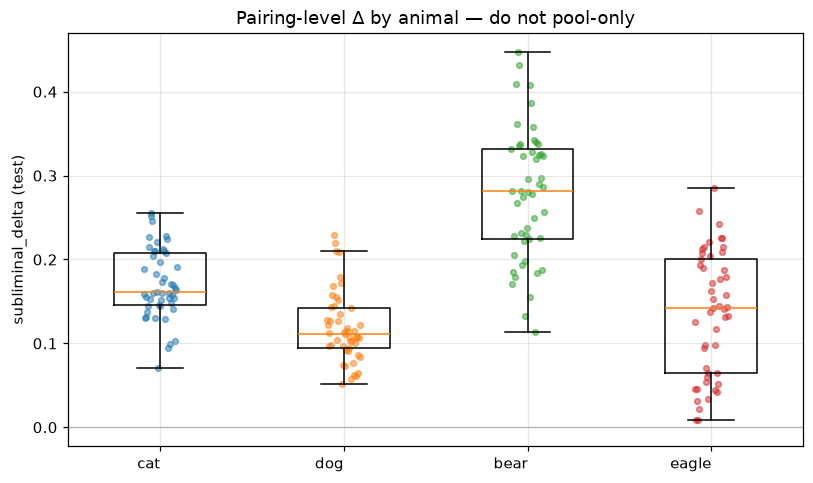

In [19]:
print_scope(seed_delta, f"gseed-level paired Δ {PRIMARY_SET}")
vc_df = seed_delta.dropna(subset=["subliminal_delta"]).copy()
vc = astats.variance_components(
    vc_df["subliminal_delta"].to_numpy(),
    {
        "animal": vc_df["animal"].tolist(),
        "pairing": vc_df["pairing"].tolist(),
        "gseed": vc_df["gseed"].astype(str).tolist(),
    },
    order=("animal", "pairing", "gseed"),
)
print("Variance components (order animal → pairing → gseed):")
print({k: round(v, 4) for k, v in vc.fractions.items()}, "n_obs", vc.n_obs)

pairing_means_animal = (
    pd_delta.groupby(["animal", "pairing"], dropna=False)["subliminal_delta"]
    .mean()
    .reset_index()
)
kw_groups = [
    pairing_means_animal.loc[pairing_means_animal["animal"] == a, "subliminal_delta"].to_numpy()
    for a in ANIMALS
]
kw = kruskal(*kw_groups)
print(f"Kruskal-Wallis on pairing-mean Δ across animals: H={kw.statistic:.3f} p={kw.pvalue:.4g}")

wide = pairing_means_animal.pivot(index="pairing", columns="animal", values="subliminal_delta")
wide = wide.reindex(columns=list(ANIMALS)).dropna()
if len(wide) != 49:
    raise AssertionError(f"Friedman block count {len(wide)} != 49")
fried = friedmanchisquare(*[wide[a].to_numpy() for a in ANIMALS])
print(
    f"Friedman (pairing-blocked, {len(wide)} pairings × {len(ANIMALS)} animals): "
    f"Q={fried.statistic:.3f} p={fried.pvalue:.4g}"
)

print("Per-animal pairing-mean Δ:")
display(
    pd_delta.groupby("animal")["subliminal_delta"]
    .agg(["mean", "std", "count"])
    .reindex(list(ANIMALS))
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
aplots.strip_box(
    ax,
    groups_for_strip(pd_delta, "animal", "subliminal_delta", ANIMALS),
    list(ANIMALS),
    colors=[ANIMAL_COLORS[a] for a in ANIMALS],
    zero_line=True,
    rotation=0,
)
ax.set_ylabel(f"subliminal_delta ({PRIMARY_SET})")
ax.set_title("Pairing-level Δ by animal — do not pool-only")
print_scope(pd_delta, "animal heterogeneity strip")
plt.tight_layout()
plt.show()


## 13. Prompt-set ladder + metric head-to-head (M1–M3)

**What this measures.** Δ across all 7 prompt sets; Spearman and sign
concordance between `test` p_target Δ and storytelling sampling Δ per
animal, against the roadmap's ≥0.6 / ≥0.8 thresholds; Bland–Altman;
forced choice as **specificity only**.

**M1 (verbatim):** Adopted iff Spearman(p_target Δ, storytelling Δ) ≥ 0.6
per animal **and** sign concordance ≥ 0.8 over the 124+ pairing×animal
cells (here 196).

**M2 (verbatim):** If sign concordance < 0.8 on any animal, report both
metrics side by side and make no single-metric ranking claim for that
animal.

**M3 (verbatim):** FC `target_share` reported as a **specificity**
control only, never as the effect size.

**Exploratory / post-hoc** — no `PREREG_HEADLINE_METRIC.md`.


SCOPE: 1372 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | Δ all prompt sets
Set scoring / n_prompts:


,scoring,n_prompts
set,,
test,prob,50
favorite,prob,50
dislike,prob,50
validation,prob,50
consensus,prob,50
register,prob,40
storytelling,sample,16


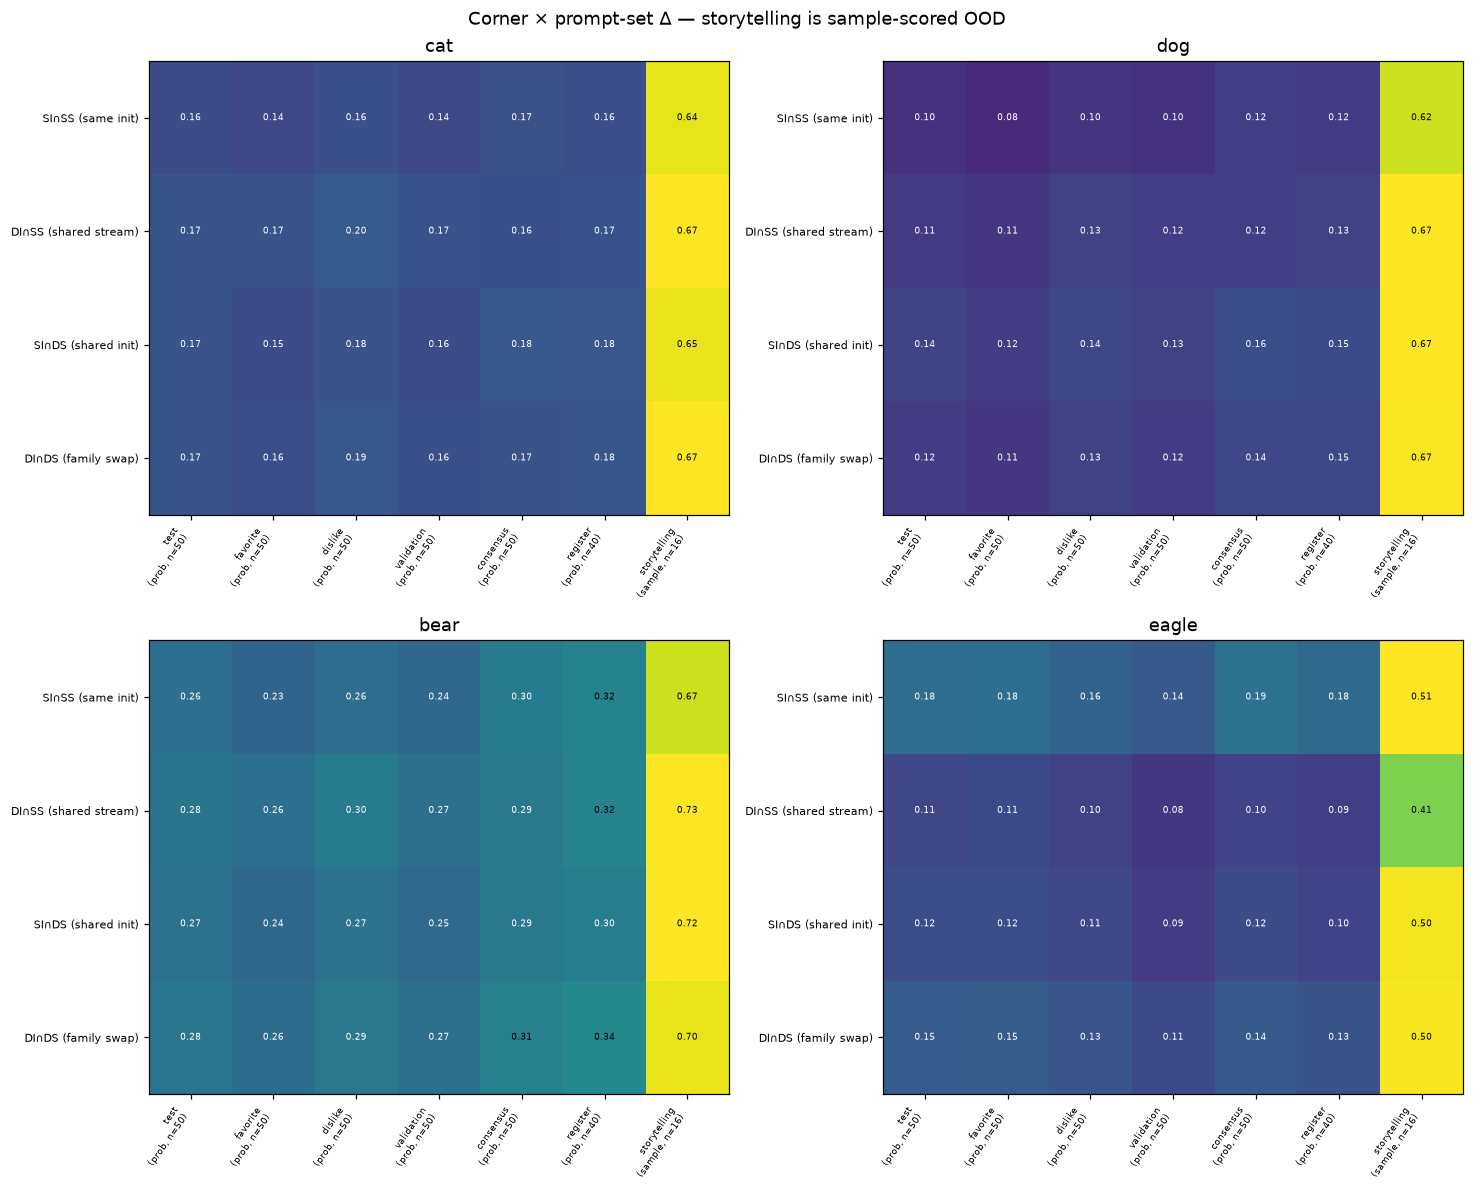

Storytelling vs test (pairing-level) — M1/M2 exploratory:
  cat: ρ=0.452 p=0.0011 sign_conc=1.000 n=49
  dog: ρ=0.565 p=2.33e-05 sign_conc=1.000 n=49
  bear: ρ=0.666 p=1.82e-07 sign_conc=1.000 n=49
  eagle: ρ=0.713 p=9.19e-09 sign_conc=1.000 n=49
Pooled sign concordance over 196 cells: 1.000 (M1 wants ≥0.8)


,animal,spearman,p,sign_concordance,n,m1_spearman_ok,m1_sign_ok
0,cat,0.452256,1.104663e-03,1.0,49,False,True
1,dog,0.565102,2.333839e-05,1.0,49,False,True
2,bear,0.665510,1.816564e-07,1.0,49,True,True
3,eagle,0.712755,9.187513e-09,1.0,49,True,True


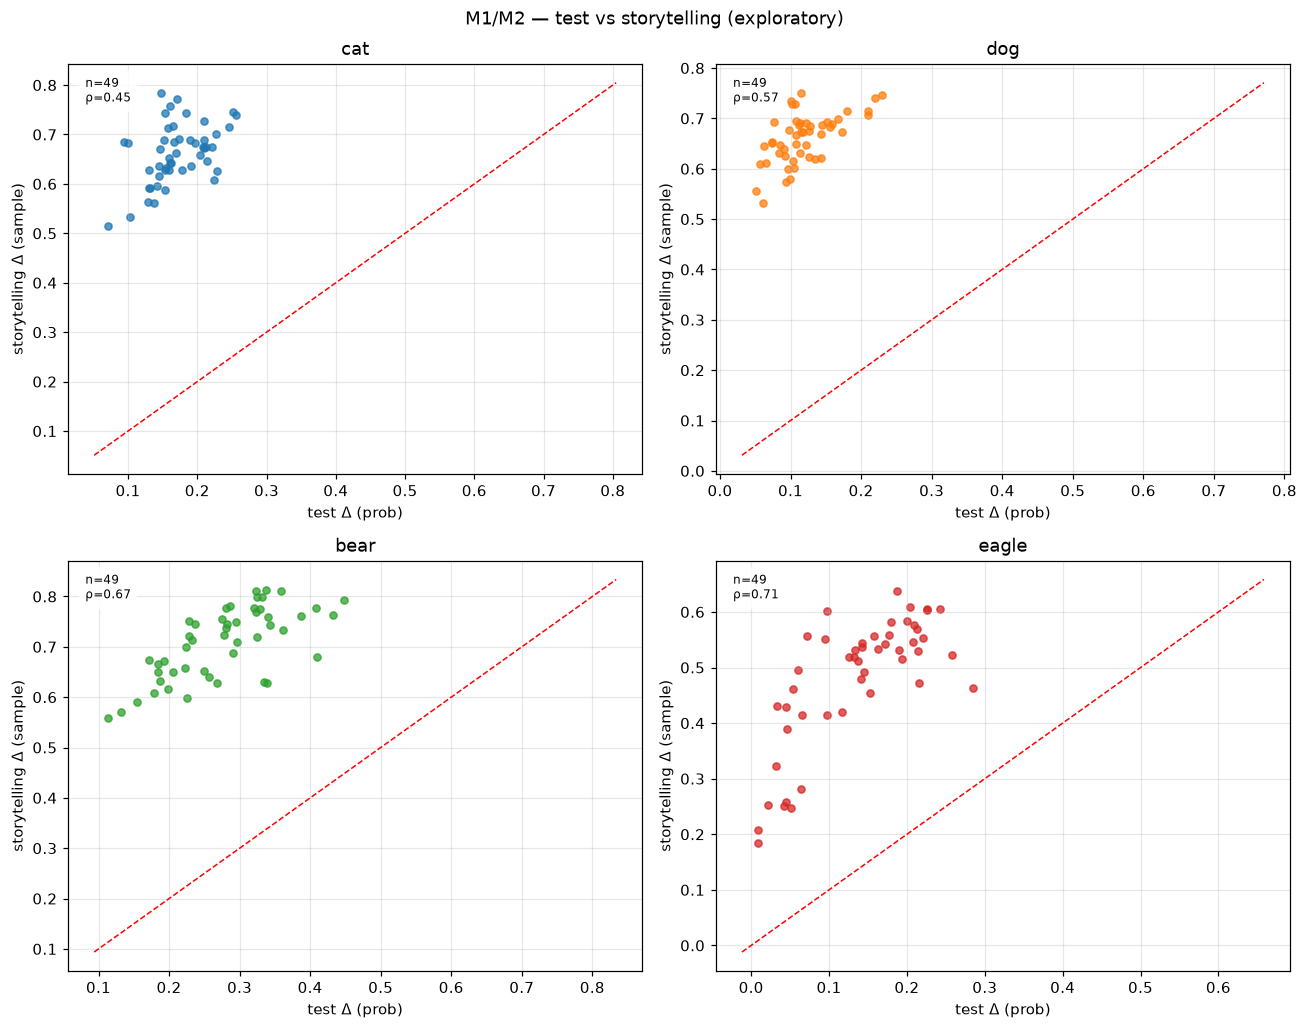

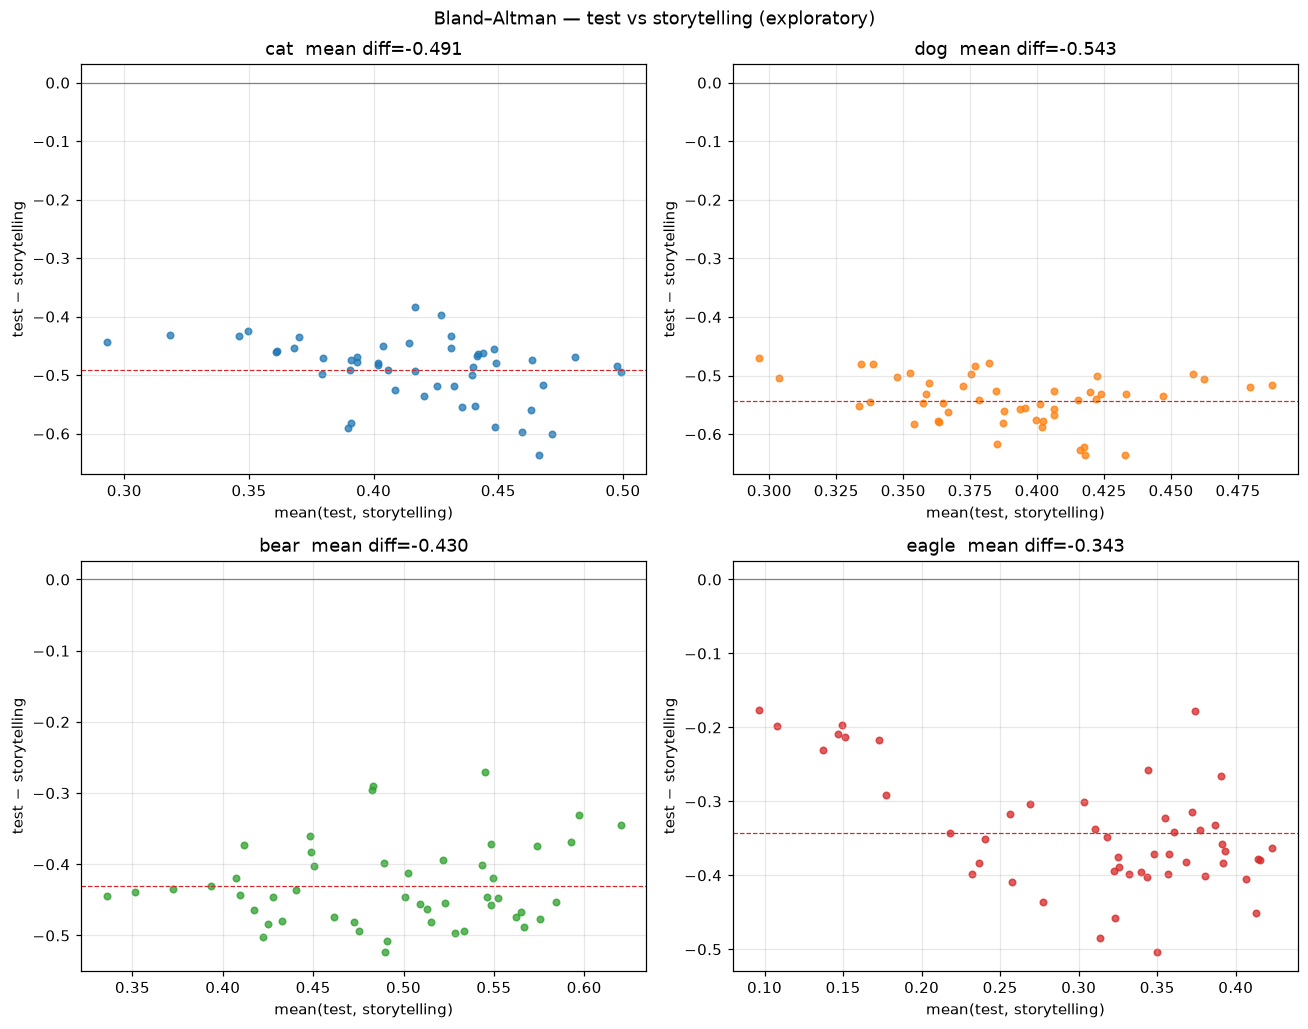

M3: forced choice is reported in §14 as a specificity control only, never as Δ.


In [20]:
delta_all = annotate_pairing(delta)
print_scope(delta_all, "Δ all prompt sets")
print("Set scoring / n_prompts:")
display(set_meta.reindex(list(PROMPT_SETS)))

fig, axes = animal_axes(figsize=(13.5, 11.0))
for ax, animal in zip(axes, ANIMALS):
    sub = delta_all[delta_all["animal"] == animal]
    g = (
        sub.pivot_table(
            index="corner",
            columns="set",
            values="subliminal_delta",
            aggfunc="mean",
        )
        .reindex(index=CORNER_ORDER, columns=list(PROMPT_SETS))
    )
    aplots.annotated_heatmap(
        ax,
        g,
        cmap="viridis",
        vmin=0.0,
        vmax=max(float(np.nanpercentile(g.to_numpy(), 98)), 0.05),
        fmt="{:.2f}",
        origin="upper",
        cell_fontsize=6.0,
    )
    ax.set_title(animal)
    ax.set_yticklabels([CORNER_SHORT[c] for c in CORNER_ORDER], fontsize=7)
    ax.set_xticklabels(
        [
            f"{s}\n({set_meta.loc[s, 'scoring']}, n={int(set_meta.loc[s, 'n_prompts'])})"
            for s in PROMPT_SETS
        ],
        fontsize=6,
    )
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("Corner × prompt-set Δ — storytelling is sample-scored OOD")
plt.tight_layout()
plt.show()

st_vs_test = (
    delta_all[delta_all["set"].isin(["test", "storytelling"])]
    .pivot_table(
        index=["animal", "pairing"],
        columns="set",
        values="subliminal_delta",
        aggfunc="mean",
    )
    .reset_index()
    .dropna()
)
print("Storytelling vs test (pairing-level) — M1/M2 exploratory:")
m12_rows = []
for animal in ANIMALS:
    sub = st_vs_test[st_vs_test["animal"] == animal]
    rho, pval = spearmanr(sub["test"], sub["storytelling"])
    same_sign = float(np.mean(np.sign(sub["test"]) == np.sign(sub["storytelling"])))
    m12_rows.append(
        {
            "animal": animal,
            "spearman": rho,
            "p": pval,
            "sign_concordance": same_sign,
            "n": len(sub),
            "m1_spearman_ok": rho >= 0.6,
            "m1_sign_ok": same_sign >= 0.8,
        }
    )
    print(
        f"  {animal}: ρ={rho:.3f} p={pval:.3g} sign_conc={same_sign:.3f} n={len(sub)}"
    )
m12 = pd.DataFrame(m12_rows)
all_sign = float(
    np.mean(np.sign(st_vs_test["test"]) == np.sign(st_vs_test["storytelling"]))
)
print(f"Pooled sign concordance over {len(st_vs_test)} cells: {all_sign:.3f} (M1 wants ≥0.8)")
display(m12)

fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = st_vs_test[st_vs_test["animal"] == animal]
    aplots.identity_scatter(
        ax,
        sub,
        "test",
        "storytelling",
        stat="spearman",
        diag_lim=(
            float(min(sub["test"].min(), sub["storytelling"].min())) - 0.02,
            float(max(sub["test"].max(), sub["storytelling"].max())) + 0.02,
        ),
        color=ANIMAL_COLORS[animal],
        s=22,
        alpha=0.75,
        title_stats=True,
        textbox=True,
    )
    ax.set_title(animal)
    ax.set_xlabel("test Δ (prob)")
    ax.set_ylabel("storytelling Δ (sample)")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("M1/M2 — test vs storytelling (exploratory)")
plt.tight_layout()
plt.show()

# Bland–Altman
ba = st_vs_test.copy()
ba["mean_delta"] = (ba["test"] + ba["storytelling"]) / 2
ba["diff"] = ba["test"] - ba["storytelling"]
fig, axes = animal_axes(figsize=(12.0, 9.5))
for ax, animal in zip(axes, ANIMALS):
    sub = ba[ba["animal"] == animal]
    ax.scatter(sub["mean_delta"], sub["diff"], color=ANIMAL_COLORS[animal], s=18, alpha=0.75)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.axhline(sub["diff"].mean(), color="C3", lw=0.8, ls="--")
    ax.set_title(f"{animal}  mean diff={sub['diff'].mean():.3f}")
    ax.set_xlabel("mean(test, storytelling)")
    ax.set_ylabel("test − storytelling")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("Bland–Altman — test vs storytelling (exploratory)")
plt.tight_layout()
plt.show()
print("M3: forced choice is reported in §14 as a specificity control only, never as Δ.")


## 14. Specificity and capability

**What this measures.** Forced-choice target share and off-target roster
shares; a **notebook-local** Cloud-style FC Δ (treatment
`target_share_mean` − matched control on `(animal, model, gkd_tag)` —
**not** a `src/` `subliminal_delta`); `perplexity_ratio`; and lm-eval
**restricted to the 96 configs that have it**.

492 of 588 treatment configs have no `benchmarks` key **by design**
(only the 8 `legacy_headline` pairings × 3 tfs × 4 animals). Never
impute. Do not quote the roadmap's stale "175/617".


SCOPE: 588 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | forced-choice target share (treat)
FC roster (10-candidate): ['bear', 'cat', 'dog', 'eagle', 'fox', 'horse', 'lion', 'pig', 'rabbit', 'tiger']
delta_vs_base on FC is versus the UNTUNED base, not the Cloud effect.
SCOPE: 588 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | notebook-local Cloud-style FC Δ (not a src/ metric)
NOTE: this join is notebook-local. There is no forced-choice subliminal_delta in src/.


,mean,std,count
animal,,,
cat,0.701827,0.038586,147
dog,0.477163,0.049319,147
bear,0.894700,0.037084,147
eagle,0.719469,0.187350,147


FC target_share by corner (mean over pairings) — specificity, not effect size:


corner,shared_init_shared_stream,diff_init_shared_stream,shared_init_diff_stream,diff_init_diff_stream
animal,,,,
cat,0.828534,0.833539,0.840765,0.839713
dog,0.790048,0.838190,0.857252,0.840019
bear,0.899805,0.921341,0.923098,0.930964
eagle,0.838756,0.653331,0.689151,0.771013


4×4 off-target matrix (mean candidate_share; diagonal = target):


candidate,cat,dog,bear,eagle
animal,,,,
cat,0.836862,0.087378,0.008161,0.000808
dog,0.058751,0.836652,0.014005,0.001928
bear,0.007916,0.025818,0.922230,0.001561
eagle,0.015555,0.050091,0.026446,0.731823


SCOPE: 2352 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | 4×4 campaign-animal FC shares


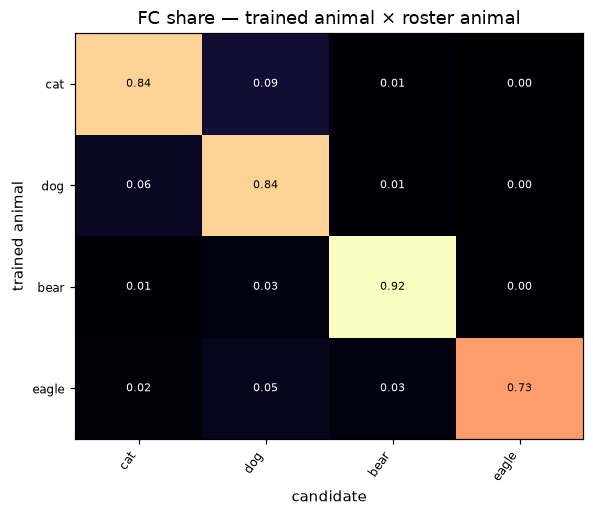

perplexity_ratio non-null: 588/588
perplexity_ratio non-finite: 0
SCOPE: 588 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | finite PPL ratios
bench_* columns present: ['bench_lambada_openai_sample_len', 'bench_lambada_openai_perplexity', 'bench_lambada_openai_acc', 'bench_arc_easy_sample_len', 'bench_arc_easy_acc', 'bench_arc_easy_acc_norm', 'bench_sciq_sample_len', 'bench_sciq_acc', 'bench_sciq_acc_norm']
lm-eval coverage: legacy_headline treat 96/96 (design 96/96 = 8 pairings × 3 tfs × 4 animals); other treat 0/492 (492 have none BY DESIGN); controls 28/28
Do not quote roadmap 175/617 (all gkd_tags, pre-B6). Never impute.
Legacy-headline treat lm-eval means (96 configs only):


,mean
bench_lambada_openai_sample_len,5153.000000
bench_lambada_openai_perplexity,808.965331
bench_lambada_openai_acc,0.083040
bench_arc_easy_sample_len,2376.000000
bench_arc_easy_acc,0.379774
bench_arc_easy_acc_norm,0.349550
bench_sciq_sample_len,1000.000000
bench_sciq_acc,0.580378
bench_sciq_acc_norm,0.515017


Control lm-eval means:


,mean
bench_lambada_openai_sample_len,5153.000000
bench_lambada_openai_perplexity,177.024428
bench_lambada_openai_acc,0.183393
bench_arc_easy_sample_len,2376.000000
bench_arc_easy_acc,0.419613
bench_arc_easy_acc_norm,0.379239
bench_sciq_sample_len,1000.000000
bench_sciq_acc,0.682274
bench_sciq_acc_norm,0.589512


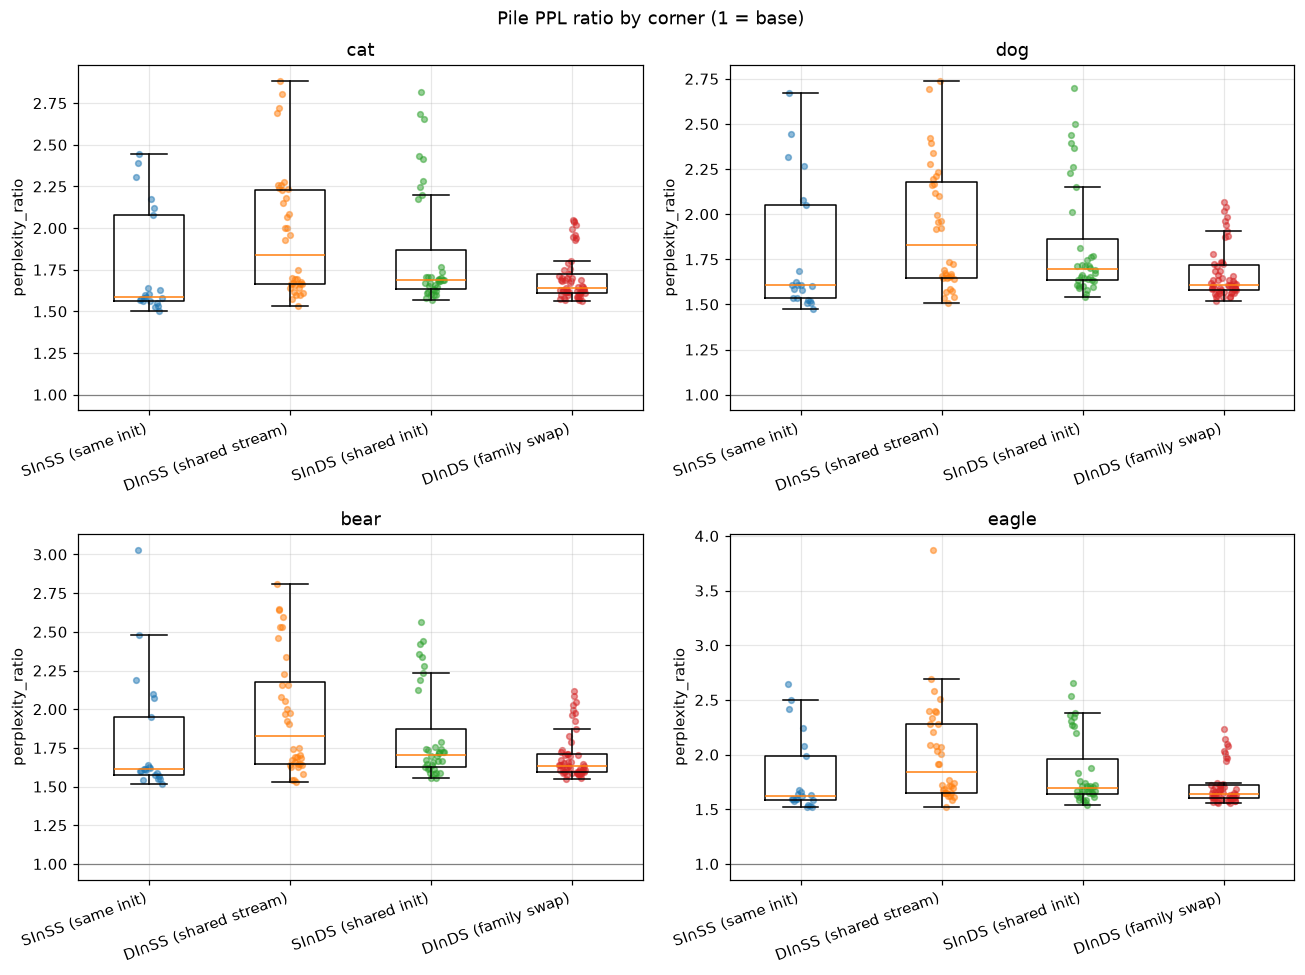

In [21]:
fc_t = annotate_pairing(fc[~fc["is_control"]].copy())
fc_c = fc[fc["is_control"]].copy()
fc_target = fc_t[fc_t["is_target"]].copy()
print_scope(fc_target, "forced-choice target share (treat)")
print("FC roster (10-candidate):", sorted(fc_t["candidate"].dropna().unique()))
if set(fc_t["candidate"].dropna().unique()) != set(FC_ROSTER):
    raise AssertionError(sorted(fc_t["candidate"].dropna().unique()))
if not set(ANIMALS).issubset(set(FC_ROSTER)):
    raise AssertionError("campaign animals missing from FC roster")
if fc_target["target_share_mean"].isna().any() or fc_target["delta_vs_base"].isna().any():
    raise AssertionError("FC target_share_mean / delta_vs_base has nulls")
print(
    "delta_vs_base on FC is versus the UNTUNED base, not the Cloud effect."
)

# Notebook-local Cloud-style FC Δ.
fc_t_cfg = (
    fc_target.drop_duplicates(["animal", "model", "teacher_tag", "gkd_tag"])
    .copy()
)
fc_c_cfg = (
    fc_c[fc_c["is_target"]]
    .drop_duplicates(["animal", "model", "gkd_tag"])
    [["animal", "model", "gkd_tag", "target_share_mean"]]
    .rename(columns={"target_share_mean": "fc_control"})
)
fc_cloud = fc_t_cfg.merge(fc_c_cfg, on=["animal", "model", "gkd_tag"], how="left")
fc_cloud["fc_subliminal_delta_notebook"] = (
    fc_cloud["target_share_mean"] - fc_cloud["fc_control"]
)
print_scope(fc_cloud, "notebook-local Cloud-style FC Δ (not a src/ metric)")
print("NOTE: this join is notebook-local. There is no forced-choice subliminal_delta in src/.")
display(
    fc_cloud.groupby("animal")["fc_subliminal_delta_notebook"]
    .agg(["mean", "std", "count"])
    .reindex(list(ANIMALS))
)

print("FC target_share by corner (mean over pairings) — specificity, not effect size:")
display(
    fc_target.groupby(["animal", "corner"])["target_share_mean"]
    .mean()
    .unstack()
    .reindex(index=list(ANIMALS), columns=CORNER_ORDER)
)

off = fc_t[fc_t["candidate"].isin(ANIMALS)].copy()
leak = (
    off.groupby(["animal", "candidate"], dropna=False)["candidate_share"]
    .mean()
    .unstack()
    .reindex(index=list(ANIMALS), columns=list(ANIMALS))
)
print("4×4 off-target matrix (mean candidate_share; diagonal = target):")
display(leak)
print_scope(off, "4×4 campaign-animal FC shares")
fig, ax = plt.subplots(figsize=(5.5, 4.8))
aplots.annotated_heatmap(
    ax,
    leak,
    cmap="magma",
    vmin=0.0,
    vmax=max(float(np.nanmax(leak.to_numpy())), 0.1),
    fmt="{:.2f}",
    origin="upper",
)
ax.set_title("FC share — trained animal × roster animal")
ax.set_xlabel("candidate")
ax.set_ylabel("trained animal")
plt.tight_layout()
plt.show()

cap_ann = annotate_pairing(cap[~cap["is_control"]].copy())
cap_ctrl = cap[cap["is_control"]].copy()
n_ppl_null = int(cap_ann["perplexity_ratio"].isna().sum())
n_ppl_bad = int((~np.isfinite(cap_ann["perplexity_ratio"])).sum())
print(f"perplexity_ratio non-null: {len(cap_ann) - n_ppl_null}/{len(cap_ann)}")
print(f"perplexity_ratio non-finite: {n_ppl_bad}")
if n_ppl_null != 0 or n_ppl_bad != 0:
    raise AssertionError((n_ppl_null, n_ppl_bad))
finite = cap_ann[np.isfinite(cap_ann["perplexity_ratio"])].copy()
print_scope(finite, "finite PPL ratios")

bench_cols = [c for c in cap.columns if c.startswith("bench_")]
print("bench_* columns present:", bench_cols)
cap_ann["has_benchmarks"] = (
    cap_ann[bench_cols].notna().any(axis=1) if bench_cols else False
)
cap_ctrl["has_benchmarks"] = (
    cap_ctrl[bench_cols].notna().any(axis=1) if bench_cols else False
)
n_legacy_bench = int(cap_ann.loc[cap_ann["legacy_headline"], "has_benchmarks"].sum())
n_legacy = int(cap_ann["legacy_headline"].sum())
n_other_bench = int(cap_ann.loc[~cap_ann["legacy_headline"], "has_benchmarks"].sum())
n_other = int((~cap_ann["legacy_headline"]).sum())
n_ctrl_bench = int(cap_ctrl["has_benchmarks"].sum())
print(
    f"lm-eval coverage: legacy_headline treat {n_legacy_bench}/{n_legacy} "
    f"(design 96/96 = 8 pairings × 3 tfs × 4 animals); "
    f"other treat {n_other_bench}/{n_other} (492 have none BY DESIGN); "
    f"controls {n_ctrl_bench}/{len(cap_ctrl)}"
)
if n_legacy_bench != 96 or n_legacy != 96:
    raise AssertionError((n_legacy_bench, n_legacy))
if n_other_bench != 0 or n_other != 492:
    raise AssertionError((n_other_bench, n_other))
if n_ctrl_bench != 28:
    raise AssertionError(n_ctrl_bench)
print(
    "Do not quote roadmap 175/617 (all gkd_tags, pre-B6). Never impute."
)

if bench_cols:
    bench_h = cap_ann[cap_ann["legacy_headline"]].copy()
    print("Legacy-headline treat lm-eval means (96 configs only):")
    display(bench_h[bench_cols].mean().to_frame("mean"))
    print("Control lm-eval means:")
    display(cap_ctrl[bench_cols].mean().to_frame("mean"))

fig, axes = animal_axes(figsize=(12.0, 9.0))
for ax, animal in zip(axes, ANIMALS):
    sub = finite[finite["animal"] == animal]
    aplots.strip_box(
        ax,
        groups_for_strip(sub, "corner", "perplexity_ratio", CORNER_ORDER),
        [CORNER_SHORT[c] for c in CORNER_ORDER],
        rotation=20,
    )
    ax.axhline(1.0, color="0.5", lw=0.8)
    ax.set_title(animal)
    ax.set_ylabel("perplexity_ratio")
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("Pile PPL ratio by corner (1 = base)")
plt.tight_layout()
plt.show()


## 15. Probe trajectories by corner

**What this measures.** In-training `p_target` after **deduplicating**
resume-append rows by `(run_dir, step)` and dropping **whole**
`diverged` leaves. Median ± IQR bands per corner, per animal.
`end_of_run_probes` / `peak_probes` / `probe_subliminal_delta`. Probe
metrics are not eval-grade. Step grid is `0, 25, …, 625` (26 steps).


Loading probe trajectories ...
  probes: 79375 rows in 5.5s
Dedup by (run_dir, step) keep=last: 48272 → 48048 rows; leaves with duplicate steps: 32  extra rows: 224
SCOPE: 45864 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | deduped B6 probes (treat)
probe step grid: (0, 25, 50, 75, 100, 125, 150, 175, 200, 225, 250, 275, 300, 325, 350, 375, 400, 425, 450, 475, 500, 525, 550, 575, 600, 625)
treat probe leaves: 1764  ctrl: 84
Diverged treat leaves: 10  (DIVERGENCE_PPL_FACTOR=10.0)


,animal,pairing,student_base,teacher_base,run_dir,gseed,teacher_ftseed
702,bear,original|data-seed2,original,data-seed2,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,0,1.0
546,bear,original|original,original,original,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,0,1.0
520,bear,original|weight-seed3,original,weight-seed3,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,2,0.0
12168,cat,original|data-seed2,original,data-seed2,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,0,1.0
12376,cat,original|weight-seed1,original,weight-seed1,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,2,1.0
24076,dog,original|original,original,original,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,2,2.0
30914,dog,weight-seed1|original,weight-seed1,original,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,1,2.0
35698,eagle,original|data-seed2,original,data-seed2,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,2,2.0
35828,eagle,original|weight-seed1,original,weight-seed1,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,1,2.0
35854,eagle,original|weight-seed1,original,weight-seed1,/mnt/ssd-3/soar-subliminal/vishesh/subliminal_...,2,2.0


SCOPE: 45604 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | probes ~diverged (whole leaf dropped)
SCOPE: 11414 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | probe bands cat ~diverged
SCOPE: 11414 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | probe bands dog ~diverged
SCOPE: 11388 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | probe bands bear ~diverged
SCOPE: 11388 configs | 1 animal(s) x 7 base model(s) | seeds pre-averaged | probe bands eagle ~diverged


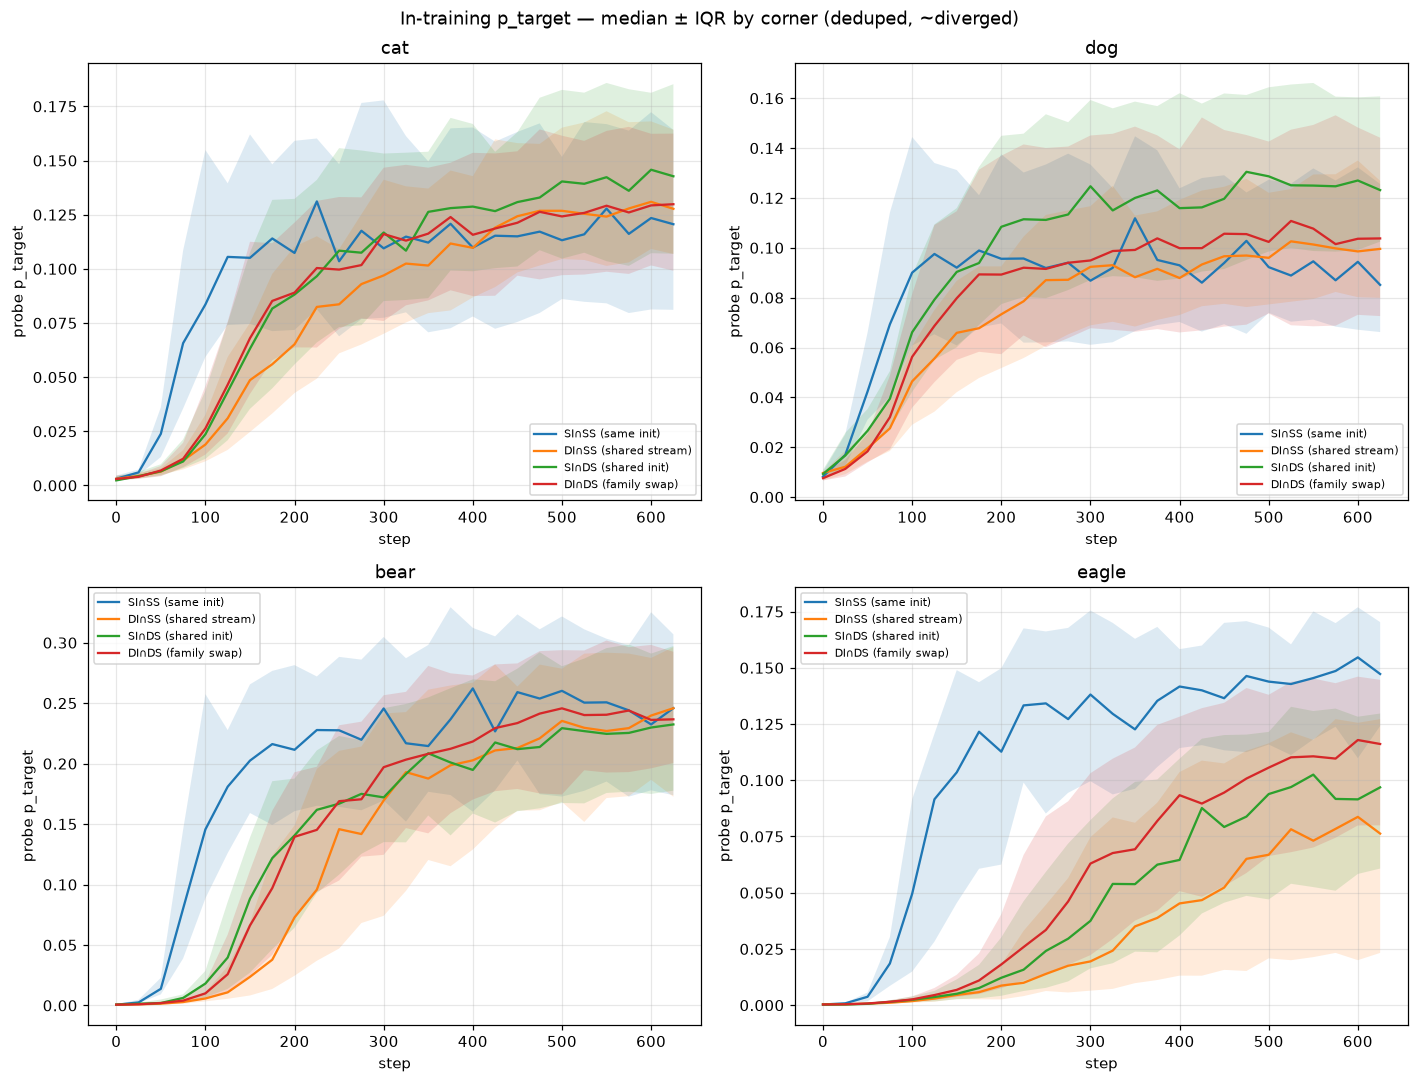

End-of-run vs peak (non-diverged treat):
  eor p_target mean 0.1488902549999504
  peak p_target mean 0.18587379298558984
Step-0 present: True
SCOPE: 45604 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | probe_subliminal_delta (~diverged, matched control)
probe_delta columns: ['animal', 'model', 'gkd_tag', 'gseed', 'step', 'diverged_treatment', 'p_target_treatment', 'fc_share_treatment', 'diverged_control', 'p_target_control', 'fc_share_control', 'delta_p_target', 'delta_fc_share']


In [22]:
print("Loading probe trajectories ...", flush=True)
t0 = time.perf_counter()
probes_all = load_gkd_probe_trajectories(OUTPUT_ROOT, SUBDIR)
print(f"  probes: {len(probes_all)} rows in {time.perf_counter() - t0:.1f}s")
probes = probes_all[probes_all["gkd_tag"] == FROZEN].copy()
n_before = len(probes)
dup_heavy = probes.groupby("run_dir")["step"].apply(lambda s: int(s.duplicated().sum()))
n_dup_leaves = int((dup_heavy > 0).sum())
n_extra = int(dup_heavy.sum())
probes = dedup_probe_steps(probes)
print(
    f"Dedup by (run_dir, step) keep=last: {n_before} → {len(probes)} rows; "
    f"leaves with duplicate steps: {n_dup_leaves}  extra rows: {n_extra}"
)
if n_dup_leaves != 32:
    print(f"NOTE: duplicate-step leaves {n_dup_leaves} != 32 snapshot")
if n_extra != 224:
    print(f"NOTE: extra rows {n_extra} != 224 snapshot")
probes = annotate_pairing(probes)
treat_pr = probes[~probes["is_control"]].copy()
ctrl_pr = probes[probes["is_control"]].copy()
print_scope(treat_pr, "deduped B6 probes (treat)")

step_grid = tuple(sorted(int(s) for s in treat_pr["step"].dropna().unique()))
print("probe step grid:", step_grid)
if step_grid != tuple(range(0, 626, 25)):
    raise AssertionError(step_grid)
n_leaves_pr = treat_pr["run_dir"].nunique()
print(f"treat probe leaves: {n_leaves_pr}  ctrl: {ctrl_pr['run_dir'].nunique()}")
if n_leaves_pr != B6_TREAT_CELLS:
    raise AssertionError(n_leaves_pr)
if ctrl_pr["run_dir"].nunique() != B_CONTROL_CELLS:
    raise AssertionError(ctrl_pr["run_dir"].nunique())

div_leaves = (
    treat_pr.loc[treat_pr["diverged"], ["animal", "pairing", "student_base", "teacher_base", "run_dir", "gseed", "teacher_ftseed"]]
    .drop_duplicates("run_dir")
)
print(f"Diverged treat leaves: {len(div_leaves)}  (DIVERGENCE_PPL_FACTOR={DIVERGENCE_PPL_FACTOR})")
if len(div_leaves) != 10:
    raise AssertionError(len(div_leaves))
display(div_leaves.sort_values(["animal", "pairing", "teacher_ftseed", "gseed"]))

clean = treat_pr[~treat_pr["diverged"]].copy()
print_scope(clean, "probes ~diverged (whole leaf dropped)")
fig, axes = animal_axes(figsize=(13.0, 10.0))
for ax, animal in zip(axes, ANIMALS):
    sub = clean[clean["animal"] == animal]
    print_scope(sub, f"probe bands {animal} ~diverged")
    for corner in CORNER_ORDER:
        g = sub[sub["corner"] == corner]
        if g.empty:
            continue
        band = g.groupby("step")["p_target"].agg(
            med="median",
            lo=lambda s: s.quantile(0.25),
            hi=lambda s: s.quantile(0.75),
        )
        ax.plot(band.index, band["med"], label=CORNER_SHORT[corner], lw=1.5)
        ax.fill_between(band.index, band["lo"], band["hi"], alpha=0.15)
    ax.set_title(animal)
    ax.set_xlabel("step")
    ax.set_ylabel("probe p_target")
    ax.legend(fontsize=7)
for ax in axes[len(ANIMALS):]:
    ax.set_visible(False)
plt.suptitle("In-training p_target — median ± IQR by corner (deduped, ~diverged)")
plt.tight_layout()
plt.show()

eor = end_of_run_probes(clean)
peak = peak_probes(clean)
print("End-of-run vs peak (non-diverged treat):")
print("  eor p_target mean", float(eor["p_target"].mean()))
print("  peak p_target mean", float(peak["p_target"].mean()))
print("Step-0 present:", 0 in set(treat_pr["step"].dropna().astype(int)))

probe_delta = probe_subliminal_delta(probes[~probes["diverged"]].copy())
print_scope(probe_delta, "probe_subliminal_delta (~diverged, matched control)")
print("probe_delta columns:", list(probe_delta.columns))


## 16. Divergence QC and the `original`-as-student pattern

**What this measures.** The 10 `diverged` treatment leaves
(`DIVERGENCE_PPL_FACTOR=10.0`; 0 controls). By animal: bear 3, cat 2,
dog 2, eagle 3. By corner: DI∩SS 5, SI∩DS 3, SI∩SS 2, **DI∩DS 0**.
**9 of the 10 have `original` as the student.** That is evidence
bearing on the receptivity claim (roadmap §1.3: `original` is the worst
student for bear and eagle). Instability of `original` as a student is
an alternative / contributing explanation for its low measured
receptivity.

Eval summaries still include these leaves in their `n_seeds=3` config
means. Primary Δ is therefore unfiltered. This section reports
diverged rate by student base and a **sensitivity** re-run of §6 / §9
with the affected configs dropped.


In [23]:
print("Diverged treat leaves (10) / controls (0):")
print(div_leaves.groupby("animal").size().reindex(list(ANIMALS)))
div_ann = div_leaves.copy()
div_ann["corner"] = [
    corner_of(
        init_seed(s) == init_seed(t),
        stream_seed(s) == stream_seed(t),
    )
    for s, t in zip(div_ann["student_base"], div_ann["teacher_base"])
]
print("by corner:", div_ann["corner"].value_counts().to_dict())
print("by student_base:", div_ann["student_base"].value_counts().to_dict())
n_orig_student = int((div_ann["student_base"] == "original").sum())
print(f"original as STUDENT: {n_orig_student}/10")
if n_orig_student != 9:
    print(f"NOTE: original-as-student count {n_orig_student} != 9 snapshot")

# Rate: diverged leaves / all treat leaves, by student base.
leaf_n = treat_m.groupby("student_base").size()
div_n = div_ann.groupby("student_base").size().reindex(BASE_ORDER).fillna(0)
rate = (div_n / leaf_n.reindex(BASE_ORDER)).rename("diverged_rate")
print("Diverged rate by student base:")
display(pd.DataFrame({"n_leaves": leaf_n.reindex(BASE_ORDER), "n_diverged": div_n, "rate": rate}))
print(
    f"original-as-student diverged rate={float(rate.loc['original']):.4f}  "
    f"other-students pooled="
    f"{float(div_n.drop(labels=['original']).sum() / leaf_n.drop(labels=['original']).sum()):.4f}"
)
print(
    "Instability of original as a student is an alternative/contributing "
    "explanation for its low measured receptivity. Primary Δ still includes "
    "these leaves (eval summaries average them into n_seeds=3)."
)

affected = (
    div_ann[["animal", "student_base", "teacher_base", "teacher_ftseed"]]
    .drop_duplicates()
)
print(f"Affected configs (animal, pairing, tfs): {len(affected)}")
pref_sens = annotate_pairing(pref[~pref["is_control"]].copy())
key = ["animal", "student_base", "teacher_base", "teacher_ftseed"]
drop_keys = set(map(tuple, affected[key].itertuples(index=False, name=None)))
keep_mask = [
    (a, s, t, f) not in drop_keys
    for a, s, t, f in zip(
        pref_sens["animal"],
        pref_sens["student_base"],
        pref_sens["teacher_base"],
        pref_sens["teacher_ftseed"],
    )
]
pref_keep = pd.concat(
    [
        pref_sens.loc[keep_mask],
        pref[pref["is_control"]],
    ],
    ignore_index=True,
)
delta_sens = pairing_delta_frame(subliminal_delta(pref_keep), PRIMARY_SET)
print_scope(delta_sens, "sensitivity Δ after dropping affected configs")
cloud_sens = cloud_rows(delta_sens)
print("Sensitivity Cloud test (affected configs dropped):")
display(cloud_sens[["animal", "same_mean", "cross_mean", "cross_positive_frac", "cross_sign_p"]])
print("Primary Cloud (for comparison):")
display(cloud[["animal", "same_mean", "cross_mean", "cross_positive_frac", "cross_sign_p"]])

print("Sensitivity D2 held-out R² / sign agreement:")
for animal in ANIMALS:
    cells = additive_cells(delta_sens[delta_sens["animal"] == animal])
    try:
        ho = leave_one_reciprocal_pair_out(cells)
        fit = fit_additive(cells)
        print(
            f"  {animal}: in-sample R²={fit.r_squared:.3f}  "
            f"held-out R²={ho.r_squared:.3f} sign_agree={ho.sign_agreement:.3f} n={fit.n_obs}"
        )
    except ValueError as exc:
        print(f"  {animal}: fit failed after drop ({exc})")

if DROP_DIVERGED_CONFIGS:
    print("DROP_DIVERGED_CONFIGS=True — subsequent cells would need a re-run from §4.")
else:
    print("DROP_DIVERGED_CONFIGS=False — primary frames unchanged (sensitivity only).")


Diverged treat leaves (10) / controls (0):
animal
cat      2
dog      2
bear     3
eagle    3
dtype: int64
by corner: {'diff_init_shared_stream': 5, 'shared_init_diff_stream': 3, 'shared_init_shared_stream': 2}
by student_base: {'original': 9, 'weight-seed1': 1}
original as STUDENT: 9/10
Diverged rate by student base:


,n_leaves,n_diverged,rate
student_base,,,
original,252,9.0,0.035714
data-seed1,252,0.0,0.000000
data-seed2,252,0.0,0.000000
data-seed3,252,0.0,0.000000
weight-seed1,252,1.0,0.003968
weight-seed2,252,0.0,0.000000
weight-seed3,252,0.0,0.000000


original-as-student diverged rate=0.0357  other-students pooled=0.0007
Instability of original as a student is an alternative/contributing explanation for its low measured receptivity. Primary Δ still includes these leaves (eval summaries average them into n_seeds=3).
Affected configs (animal, pairing, tfs): 9
SCOPE: 196 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | sensitivity Δ after dropping affected configs
Sensitivity Cloud test (affected configs dropped):


,animal,same_mean,cross_mean,cross_positive_frac,cross_sign_p
0,cat,0.156478,0.173729,1.0,2.273737e-13
1,dog,0.095462,0.122913,1.0,2.273737e-13
2,bear,0.264705,0.279801,1.0,2.273737e-13
3,eagle,0.181202,0.128253,1.0,2.273737e-13


Primary Cloud (for comparison):


,animal,same_mean,cross_mean,cross_positive_frac,cross_sign_p
0,cat,0.156478,0.173514,1.0,2.273737e-13
1,dog,0.096383,0.122769,1.0,2.273737e-13
2,bear,0.264659,0.280004,1.0,2.273737e-13
3,eagle,0.181202,0.127968,1.0,2.273737e-13


Sensitivity D2 held-out R² / sign agreement:
  cat: in-sample R²=0.841  held-out R²=0.735 sign_agree=1.000 n=49
  dog: in-sample R²=0.890  held-out R²=0.880 sign_agree=0.905 n=49
  bear: in-sample R²=0.838  held-out R²=0.740 sign_agree=0.810 n=49
  eagle: in-sample R²=0.806  held-out R²=0.879 sign_agree=0.952 n=49
DROP_DIVERGED_CONFIGS=False — primary frames unchanged (sensitivity only).


## 17. Optimization / loss matching

**What this measures.** `final_train_loss` by corner, gradient norms,
and end-step KL monitors. `grad_concentration.jsonl` is absent (the
probe was off) — stated in one line, no section depends on it.


SCOPE: 1764 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | train manifests, treat
n_train_steps unique: [np.int64(625)]
n_train_prompts unique: [np.int64(20000)]
final_train_loss null: 0
final_train_loss by corner:


corner,shared_init_shared_stream,diff_init_shared_stream,shared_init_diff_stream,diff_init_diff_stream
animal,,,,
cat,0.499297,1.004662,0.900664,0.753001
dog,0.507393,0.994123,0.881066,0.743853
bear,0.509380,1.008169,0.893547,0.756417
eagle,0.506775,1.011786,0.888769,0.757324


Loading trainer logs ...
  logs: 189366 rows in 5.3s
trainer log leaves treat=1764 ctrl=84
SCOPE: 1764 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | end-step trainer scalars
End-step GKD monitors by corner:


,fwd_kl,rev_kl,student_entropy,loss,grad_norm
corner,,,,,
shared_init_shared_stream,0.503289,0.434383,2.696378,0.434384,7.366768
diff_init_shared_stream,1.117737,0.929987,2.567157,0.929989,10.146325
shared_init_diff_stream,0.962248,0.818634,2.686397,0.818633,9.216978
diff_init_diff_stream,0.801577,0.691596,2.762647,0.691599,4.169640


Loading grad_concentration (expected empty) ...
grad_concentration rows: 0 — probe was off; no section depends on it.
rollouts_summary.json: treat 1764/1764  ctrl 84/84
Not opening rollouts_sample.jsonl (~18–19 MB/leaf).


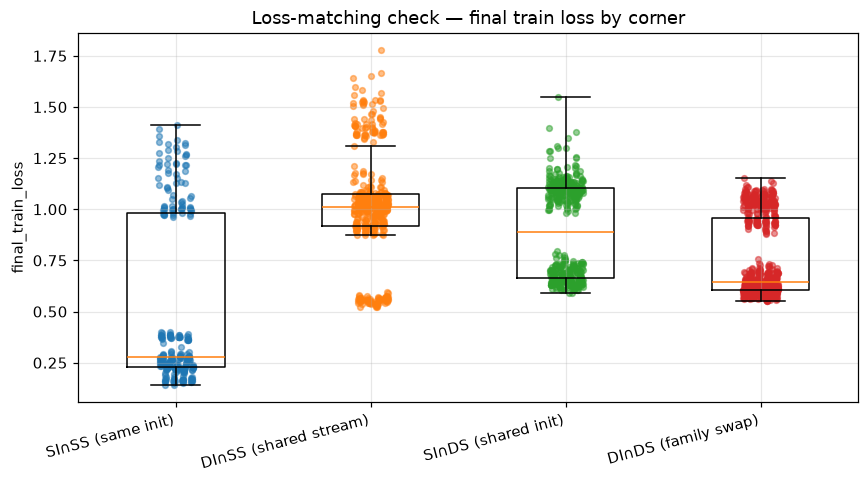

In [24]:
man_t = annotate_pairing(manifests[~manifests["is_control"]].copy())
print_scope(man_t, "train manifests, treat")
print("n_train_steps unique:", sorted(man_t["n_train_steps"].dropna().unique()))
print("n_train_prompts unique:", sorted(man_t["n_train_prompts"].dropna().unique()))
print("final_train_loss null:", int(man_t["final_train_loss"].isna().sum()))
print("final_train_loss by corner:")
display(
    man_t.groupby(["animal", "corner"])["final_train_loss"]
    .mean()
    .unstack()
    .reindex(index=list(ANIMALS), columns=CORNER_ORDER)
)

print("Loading trainer logs ...", flush=True)
t0 = time.perf_counter()
logs_all = load_gkd_training_logs(OUTPUT_ROOT, SUBDIR)
print(f"  logs: {len(logs_all)} rows in {time.perf_counter() - t0:.1f}s")
logs = annotate_pairing(logs_all[logs_all["gkd_tag"] == FROZEN].copy())
logs_t = logs[~logs["is_control"]].copy()
print(
    f"trainer log leaves treat={logs_t['run_dir'].nunique()} "
    f"ctrl={logs[logs.is_control]['run_dir'].nunique()}"
)
if logs_t["run_dir"].nunique() != B6_TREAT_CELLS:
    raise AssertionError(logs_t["run_dir"].nunique())
end_logs = logs_t.sort_values("step").groupby("run_dir", as_index=False).tail(1)
print_scope(end_logs, "end-step trainer scalars")
print("End-step GKD monitors by corner:")
display(
    end_logs.groupby("corner")[["fwd_kl", "rev_kl", "student_entropy", "loss", "grad_norm"]]
    .mean()
    .reindex(CORNER_ORDER)
)

print("Loading grad_concentration (expected empty) ...", flush=True)
grad = load_gkd_grad_concentration(OUTPUT_ROOT, SUBDIR)
print(f"grad_concentration rows: {len(grad)} — probe was off; no section depends on it.")

# rollouts_summary presence (do NOT open rollouts_sample.jsonl)
n_roll_t = 0
n_roll_c = 0
for d in treat_dirs:
    for g in d.glob("gseed*"):
        if (g / "rollouts_summary.json").is_file():
            n_roll_t += 1
for d in ctrl_dirs:
    for g in d.glob("gseed*"):
        if (g / "rollouts_summary.json").is_file():
            n_roll_c += 1
print(f"rollouts_summary.json: treat {n_roll_t}/{B6_TREAT_CELLS}  ctrl {n_roll_c}/{B_CONTROL_CELLS}")
if n_roll_t != B6_TREAT_CELLS or n_roll_c != B_CONTROL_CELLS:
    raise AssertionError((n_roll_t, n_roll_c))
print("Not opening rollouts_sample.jsonl (~18–19 MB/leaf).")

fig, ax = plt.subplots(figsize=(8.0, 4.5))
aplots.strip_box(
    ax,
    groups_for_strip(man_t, "corner", "final_train_loss", CORNER_ORDER),
    [CORNER_SHORT[c] for c in CORNER_ORDER],
    rotation=15,
)
ax.set_ylabel("final_train_loss")
ax.set_title("Loss-matching check — final train loss by corner")
plt.tight_layout()
plt.show()


## 18. What B6 changed vs the 31-pairing Stage B

**What this measures.** Side-by-side design table (corner counts
7/9/9/6 → 7/12/12/18, leaves/animal 141 → 441, Cloud n, H1 n) and
**measured CI-width shrinkage** on pairings that existed before
(`~b6_new`) and on the 8 `legacy_headline` pairings, versus the full
grid. This is the section that justifies the campaign. Depth is
uniform, so `legacy_headline` is not a precision tier — it is the
old headline subset used only to show what the previous notebook was
forced to report.


In [25]:
stage_b_corner = Counter()
for p in stage_b_pairs():
    si = init_seed(p.student) == init_seed(p.teacher)
    ss = stream_seed(p.student) == stream_seed(p.teacher)
    stage_b_corner[corner_of(si, ss)] += 1
change = pd.DataFrame(
    [
        {
            "quantity": "directed pairings",
            "stage_b": 31,
            "b6": 49,
        },
        {
            "quantity": "SI∩SS / DI∩SS / SI∩DS / DI∩DS",
            "stage_b": "7 / 9 / 9 / 6",
            "b6": "7 / 12 / 12 / 18",
        },
        {
            "quantity": "leaves / animal",
            "stage_b": 141,
            "b6": B6_TREAT_CELLS_PER_ANIMAL,
        },
        {
            "quantity": "treatment leaves",
            "stage_b": B_TREAT_CELLS,
            "b6": B6_TREAT_CELLS,
        },
        {
            "quantity": "tier structure",
            "stage_b": "8 headline @ 3 tfs + 23 extension @ 1 tfs",
            "b6": "uniform 3 tfs × 3 gseeds",
        },
        {
            "quantity": "Cloud test n (same / cross)",
            "stage_b": "headline 2 / 6 (degenerate CIs) or pooled-tiers caveat",
            "b6": "7 / 42 uniform",
        },
        {
            "quantity": "H1 n (SI∩DS vs DI∩SS)",
            "stage_b": "headline 2 vs 2",
            "b6": "12 vs 12",
        },
        {
            "quantity": "reciprocals / animal",
            "stage_b": "3 complete (headline) / incomplete elsewhere",
            "b6": "21 of 21",
        },
    ]
)
print("Design change (B6 vs Stage B 31-pair):")
display(change)
print("Stage B corner counts from stage_b_pairs():", dict(stage_b_corner))

# CI-width shrinkage: same statistic on subsets vs full grid.
legacy = pd_delta[pd_delta["legacy_headline"]].copy()
preexist = pd_delta[~pd_delta["b6_new"]].copy()
print_scope(legacy, "legacy_headline subset (8 pairings, provenance only)")
print_scope(preexist, "~b6_new subset (31 Stage B pairings)")

cloud_legacy = cloud_rows(legacy)
cloud_pre = cloud_rows(preexist)
shrink = cloud[["animal", "cross_ci_width"]].rename(columns={"cross_ci_width": "full_42"})
shrink = shrink.merge(
    cloud_legacy[["animal"]].assign(
        legacy_headline_cross=cloud_legacy["cross_ci_hi"] - cloud_legacy["cross_ci_lo"]
    ),
    on="animal",
)
shrink = shrink.merge(
    cloud_pre[["animal"]].assign(
        stage_b_31_cross=cloud_pre["cross_ci_hi"] - cloud_pre["cross_ci_lo"]
    ),
    on="animal",
)
print("Cloud cross-init CI width (pairing-cluster) — full vs subsets:")
display(shrink)

# H1 contrast CI width: full 12 vs 12 vs the 31-pair corners (9 vs 9).
h1_width_rows = []
for animal in ANIMALS:
    for label, frame, n_expect in (
        ("full_12v12", pd_delta, 12),
        ("stage_b_31", preexist, None),
        ("legacy_headline", legacy, None),
    ):
        sub = frame[frame["animal"] == animal]
        si = sub.loc[sub["corner"] == CORNER_SHARED_INIT_DIFF_STREAM, "subliminal_delta"]
        di = sub.loc[sub["corner"] == CORNER_DIFF_INIT_SHARED_STREAM, "subliminal_delta"]
        if len(si) < 2 or len(di) < 2:
            h1_width_rows.append(
                {
                    "animal": animal,
                    "subset": label,
                    "n_SI": int(si.size),
                    "n_DI": int(di.size),
                    "ci_width": np.nan,
                    "note": "n<2 — skip",
                }
            )
            continue
        est = contrast_cluster_ci(di.values, si.values)
        h1_width_rows.append(
            {
                "animal": animal,
                "subset": label,
                "n_SI": int(si.size),
                "n_DI": int(di.size),
                "ci_width": est.ci_high - est.ci_low,
                "contrast": est.estimate,
                "note": "",
            }
        )
h1_width = pd.DataFrame(h1_width_rows)
print("H1 contrast CI width by subset:")
display(h1_width)
print(
    "legacy_headline is a provenance flag, not a precision tier. "
    "The CI-width comparison is what B6 bought: the 31-pair and 8-pair "
    "subsets versus the complete uniform grid."
)

# Corner CI widths full vs 31-pair.
c31 = pd.concat(
    [
        corner_bootstrap_table(preexist, animal=a, n_boot=N_BOOT, seed=BOOTSTRAP_SEED)
        for a in ANIMALS
    ],
    ignore_index=True,
)
cmp_w = corner_ci[["animal", "corner", "ci_width", "n_pairings"]].merge(
    c31[["animal", "corner", "ci_width", "n_pairings"]],
    on=["animal", "corner"],
    suffixes=("_full", "_stage_b"),
)
print("Corner CI width full vs 31-pair Stage B subset:")
display(cmp_w)


Design change (B6 vs Stage B 31-pair):


,quantity,stage_b,b6
0,directed pairings,31,49
1,SI∩SS / DI∩SS / SI∩DS / DI∩DS,7 / 9 / 9 / 6,7 / 12 / 12 / 18
2,leaves / animal,141,441
3,treatment leaves,564,1764
4,tier structure,8 headline @ 3 tfs + 23 extension @ 1 tfs,uniform 3 tfs × 3 gseeds
5,Cloud test n (same / cross),headline 2 / 6 (degenerate CIs) or pooled-tier...,7 / 42 uniform
6,H1 n (SI∩DS vs DI∩SS),headline 2 vs 2,12 vs 12
7,reciprocals / animal,3 complete (headline) / incomplete elsewhere,21 of 21


Stage B corner counts from stage_b_pairs(): {'shared_init_shared_stream': 7, 'shared_init_diff_stream': 9, 'diff_init_shared_stream': 9, 'diff_init_diff_stream': 6}
SCOPE: 32 configs | 4 animal(s) x 6 base model(s) | seeds pre-averaged | legacy_headline subset (8 pairings, provenance only)
SCOPE: 124 configs | 4 animal(s) x 7 base model(s) | seeds pre-averaged | ~b6_new subset (31 Stage B pairings)
Cloud cross-init CI width (pairing-cluster) — full vs subsets:


,animal,full_42,legacy_headline_cross,stage_b_31_cross
0,cat,0.022998,0.057143,0.032362
1,dog,0.024696,0.076714,0.034215
2,bear,0.042270,0.111554,0.061021
3,eagle,0.043761,0.073384,0.057368


H1 contrast CI width by subset:


,animal,subset,n_SI,n_DI,ci_width,contrast,note
0,cat,full_12v12,12,12,0.057381,0.001205,
1,cat,stage_b_31,9,9,0.069280,-0.002761,
2,cat,legacy_headline,2,2,0.108587,-0.007688,
3,dog,full_12v12,12,12,0.054307,-0.024046,
4,dog,stage_b_31,9,9,0.069989,-0.025530,
5,dog,legacy_headline,2,2,0.094651,-0.021113,
6,bear,full_12v12,12,12,0.106752,0.010217,
7,bear,stage_b_31,9,9,0.131259,-0.005573,
8,bear,legacy_headline,2,2,0.112166,0.031617,
9,eagle,full_12v12,12,12,0.123284,-0.010855,


legacy_headline is a provenance flag, not a precision tier. The CI-width comparison is what B6 bought: the 31-pair and 8-pair subsets versus the complete uniform grid.
Corner CI width full vs 31-pair Stage B subset:


,animal,corner,ci_width_full,n_pairings_full,ci_width_stage_b,n_pairings_stage_b
0,cat,shared_init_shared_stream,0.078495,7,0.078495,7
1,cat,diff_init_shared_stream,0.033396,12,0.041100,9
2,cat,shared_init_diff_stream,0.045504,12,0.052454,9
3,cat,diff_init_diff_stream,0.038107,18,0.081090,6
4,dog,shared_init_shared_stream,0.054807,7,0.054807,7
5,dog,diff_init_shared_stream,0.019014,12,0.024925,9
6,dog,shared_init_diff_stream,0.050490,12,0.062105,9
7,dog,diff_init_diff_stream,0.043576,18,0.080407,6
8,bear,shared_init_shared_stream,0.164454,7,0.164454,7
9,bear,diff_init_shared_stream,0.062640,12,0.077188,9


## 19. Takeaways + claims-status table

**What this measures.** Numbers recomputed from frames as f-strings —
never pasted literals. Claims-status values are only
`exploratory-supported` / `exploratory-not-supported` /
`exploratory-inconclusive` / `not-computable` / `not-triggered`.
Roadmap decision rules are quoted verbatim. D5 / D6 are
`not-computable` (R1 and D-causal have not been run). M2 is a
conditional guardrail rather than a hypothesis, so it reads
`not-triggered` when every animal clears the 0.8 sign-concordance bar.

D1's `status` deviates from the literal rule in one direction only: it
requires the orientation-free per-contrast test of §8 to survive BH
correction before it will say `exploratory-supported`, because the
roadmap's sign test is confounded with label/family ordering.


In [26]:
def _fmt(x: float, nd: int = 3) -> str:
    return f"{x:.{nd}f}" if x == x else "nan"


def _status_d1() -> str:
    # The roadmap's sign test is lex-oriented and therefore confounded with
    # family ordering (§8), so "supported" additionally requires the
    # orientation-free per-contrast test to survive BH correction.
    mag = mean_abs > 2 * pooled_sd
    sig = (st84.p_value == st84.p_value) and (st84.p_value < 0.01)
    if mag and sig and d1_n_sig > 0:
        return "exploratory-supported"
    if (not mag) and (not sig) and d1_n_sig == 0:
        return "exploratory-not-supported"
    return "exploratory-inconclusive"


def _status_d2() -> str:
    r2_ok = all(held[a].r_squared >= 0.85 for a in ANIMALS)
    if r2_ok and covers0:
        return "exploratory-supported"
    if excl_005:
        return "exploratory-supported"
    return "exploratory-inconclusive"


def _status_d3() -> str:
    if d3_ci.ci_high <= 0.0 or (d3_ci.ci_low <= 0.0 <= d3_ci.ci_high):
        return "exploratory-supported"
    return "exploratory-not-supported"


def _status_d4() -> str:
    row = d4_tab[
        (d4_tab["predictor"] == "own SDF teacher favorite p_target")
        & (d4_tab["animal"] == "pooled")
    ]
    if row.empty:
        return "not-computable"
    rho = float(row["rho"].iloc[0])
    lo, hi = float(row["ci_lo"].iloc[0]), float(row["ci_hi"].iloc[0])
    excl0 = (hi < 0) or (lo > 0)
    if rho > 0.5 and excl0:
        return "exploratory-supported"
    if (rho <= 0.5) and (not excl0):
        return "exploratory-inconclusive"
    return "exploratory-not-supported"


def _status_m1() -> str:
    if bool(m12["m1_spearman_ok"].all()) and all_sign >= 0.8:
        return "exploratory-supported"
    return "exploratory-not-supported"


def _status_m2() -> str:
    # M2 is a conditional guardrail, not a hypothesis: it only applies when
    # some animal falls below 0.8 sign concordance.
    if bool((m12["sign_concordance"] < 0.8).any()):
        return "exploratory-supported"
    return "not-triggered"


d2_measured = (
    "held-out R² "
    + ", ".join(f"{a}={held[a].r_squared:.3f}" for a in ANIMALS)
    + f"; pooled ι={iota_ci.estimate:.4f} CI[{iota_ci.ci_low:.4f}, {iota_ci.ci_high:.4f}]"
)
if all(held[a].r_squared >= 0.85 for a in ANIMALS) and covers0:
    d2_measured += " → compositional"
elif excl_005:
    d2_measured += " → directional interaction"
else:
    d2_measured += " → inconclusive under the written rule"
d2_measured += (
    "; off-diagonal-only (42-cell) held-out R² "
    + ", ".join(
        f"{r.animal}={r.heldout_r2_offdiag:.3f}" for r in off_tab.itertuples()
    )
    + f"; same-init extrapolation gap {gap_ci.estimate:.4f} "
    f"CI[{gap_ci.ci_low:.4f}, {gap_ci.ci_high:.4f}]"
)

claims = pd.DataFrame(
    [
        {
            "id": "D1",
            "roadmap_rule": (
                "Over the 21 unordered base pairs × 4 animals, the mean signed "
                "|Δ(B←A) − Δ(A←B)| exceeds 2× the pooled within-cell replicate "
                "SD, and the sign test over 84 contrasts has p < 0.01"
            ),
            "measured": (
                f"mean|asym|={mean_abs:.4f}; 2×SD={2 * pooled_sd:.4f}; "
                f"exceeds={mean_abs > 2 * pooled_sd}; "
                f"sign {st84.n_positive}/{st84.n_effective} p={st84.p_value:.4g} "
                "(lex orientation — confounded with family order); "
                f"orientation-free per-contrast Welch: {d1_n_sig}/84 at BH q<0.05"
            ),
            "status": _status_d1(),
        },
        {
            "id": "D2",
            "roadmap_rule": (
                "Leave-one-reciprocal-pair-out CV of the additive model. If "
                "held-out R² ≥ 0.85 and the pooled ι CI covers 0 → "
                "compositional. If ι CI excludes 0 at ≥0.05 absolute → "
                "directional interaction. Else inconclusive."
            ),
            "measured": d2_measured,
            "status": _status_d2(),
        },
        {
            "id": "D3",
            "roadmap_rule": (
                "Spearman(teacher p_target advantage, Δ advantage) CI covers 0 "
                "or is negative, over all 84 contrasts"
            ),
            "measured": (
                f"ρ={rho84:.3f} boot CI[{d3_ci.ci_low:.3f}, {d3_ci.ci_high:.3f}]"
            ),
            "status": _status_d3(),
        },
        {
            "id": "D4",
            "roadmap_rule": (
                "σ_j correlates with the base's own trait affinity (its SDF "
                "teacher p_target on favorite) at ρ > 0.5, pooled over animals, "
                "with the CI excluding 0"
            ),
            "measured": (
                d4_tab.loc[
                    (d4_tab["predictor"] == "own SDF teacher favorite p_target")
                    & (d4_tab["animal"] == "pooled"),
                    ["rho", "ci_lo", "ci_hi"],
                ]
                .iloc[0]
                .to_string()
                if not d4_tab.empty
                else "n/a"
            ),
            "status": _status_d4(),
        },
        {
            "id": "D5",
            "roadmap_rule": (
                "From R1: original-as-student at its own best (LR, rank) "
                "recovers ≤ 50% of the receptivity deficit measured at the "
                "frozen recipe. If it recovers > 50%, D4 is withdrawn."
            ),
            "measured": "R1 not run",
            "status": "not-computable",
        },
        {
            "id": "D6",
            "roadmap_rule": (
                "From D-causal: under teachers dose-matched to within 10% on "
                "p_target, the asymmetry retains ≥ 50% of its magnitude"
            ),
            "measured": "D-causal not run",
            "status": "not-computable",
        },
        {
            "id": "M1",
            "roadmap_rule": (
                "Headline stays subliminal_delta on test/prob iff "
                "Spearman(p_target Δ, storytelling Δ) ≥ 0.6 per animal and "
                "sign concordance ≥ 0.8 over the 124+ pairing×animal cells"
            ),
            "measured": (
                "; ".join(
                    f"{r.animal} ρ={r.spearman:.3f} sign={r.sign_concordance:.3f}"
                    for r in m12.itertuples()
                )
                + f"; pooled sign={all_sign:.3f} n={len(st_vs_test)}"
            ),
            "status": _status_m1(),
        },
        {
            "id": "M2",
            "roadmap_rule": (
                "If sign concordance < 0.8 on any animal, report both metrics "
                "side by side and make no single-metric ranking claim for that animal"
            ),
            "measured": "; ".join(
                f"{r.animal}={r.sign_concordance:.3f}" for r in m12.itertuples()
            ),
            "status": _status_m2(),
        },
        {
            "id": "M3",
            "roadmap_rule": (
                "FC target_share reported as a specificity control only, never "
                "as the effect size"
            ),
            "measured": (
                "FC reported as specificity in §14; Cloud-style FC Δ is "
                "labelled notebook-local"
            ),
            "status": "exploratory-supported",
        },
    ]
)
if (claims["status"] == "supported").any():
    raise AssertionError("bare 'supported' is forbidden")
print("CLAIMS STATUS (exploratory — no prereg was filed):")
display(claims)

takeaways = [
    f"B6 wrote into {RUN_SET_ID} at frozen tag {FROZEN}; "
    f"{len(treat_dirs)} treat configs / {len(treat_leaves)} leaves, "
    f"{len(ctrl_dirs)} control configs / {len(ctrl_leaves)} leaves. "
    f"No CAMPAIGN_DONE_B6; completion is the three b6-* queues (all rc=0) "
    f"plus these coverage asserts.",
    f"Directed pairings=49; corners={CORNER_COUNTS_EXPECTED}; "
    f"reciprocals=21/21 per animal; Cloud n=7 vs 42; H1 n=12 vs 12.",
    f"subliminal_delta rows={len(delta)} (1372=196×7); "
    f"n_pairs!=3 rows=0; triad 588/588.",
    f"Control floor max={floor_cell.p_target.max():.4f} "
    f"(CONTROL_FLOOR_MAX={CONTROL_FLOOR_MAX}); 0 cells exceed.",
]
for row in cloud.itertuples():
    takeaways.append(
        f"Cloud {row.animal}: same={_fmt(row.same_mean)} "
        f"cross={_fmt(row.cross_mean)} "
        f"cross_positive_frac={_fmt(row.cross_positive_frac, 2)} "
        f"sign p={_fmt(row.cross_sign_p, 4)}."
    )
for row in h1.itertuples():
    takeaways.append(
        f"H1 {row.animal}: SI∩DS={_fmt(row.mean_SI_DS)} "
        f"DI∩SS={_fmt(row.mean_DI_SS)} "
        f"contrast={_fmt(row.contrast_DI_minus_SI)} "
        f"CI[{_fmt(row.ci_lo)}, {_fmt(row.ci_hi)}]."
    )
for animal in ANIMALS:
    takeaways.append(
        f"D1 {animal}: mean signed asym (lex orientation, family-confounded)"
        f"={_fmt(float(d1_sum.loc[animal, 'mean_signed']))} "
        f"mean|asym|={_fmt(float(d1_sum.loc[animal, 'mean_abs']))}; "
        f"orientation-free {int((d1_sig.loc[d1_sig.animal == animal, 'q_bh'] < 0.05).sum())}/21 "
        "contrasts at BH q<0.05; "
        f"original-as-T={_fmt(float(orig_tab.loc[orig_tab.animal==animal, 'mean_original_as_teacher'].iloc[0]))} "
        f"original-as-S={_fmt(float(orig_tab.loc[orig_tab.animal==animal, 'mean_original_as_student'].iloc[0]))} "
        f"sign={orig_tab.loc[orig_tab.animal==animal, 'sign'].iloc[0]}."
    )
for animal in ANIMALS:
    takeaways.append(
        f"D2 {animal}: in-sample R²={fits[animal].r_squared:.3f} "
        f"held-out R²={held[animal].r_squared:.3f} "
        f"sign_agree={held[animal].sign_agreement:.3f} "
        f"Pearson={held[animal].pearson:.3f}."
    )
takeaways.append(
    f"D3 Spearman ρ={rho84:.3f} CI[{d3_ci.ci_low:.3f}, {d3_ci.ci_high:.3f}]. "
    f"original teacher ranks: "
    + ", ".join(f"{r.animal}={r.rank}/{r.roadmap}" for r in orig_ranks.itertuples())
    + "."
)
for animal in ANIMALS:
    sub = d4_tab[
        (d4_tab["predictor"] == "own SDF teacher favorite p_target")
        & (d4_tab["animal"] == animal)
    ]
    if not sub.empty:
        takeaways.append(
            f"D4 {animal}: ρ={float(sub.rho.iloc[0]):.3f} "
            f"CI[{float(sub.ci_lo.iloc[0]):.3f}, {float(sub.ci_hi.iloc[0]):.3f}]."
        )
takeaways.append(
    f"Animal heterogeneity: KW H={kw.statistic:.2f} p={kw.pvalue:.3g}; "
    f"Friedman Q={fried.statistic:.2f} p={fried.pvalue:.3g}; "
    f"VC animal share={vc.fractions['animal']:.3f}."
)
takeaways.append(
    f"lm-eval: {n_legacy_bench}/{n_legacy} legacy_headline, "
    f"{n_other_bench}/{n_other} other (absent by design), "
    f"controls {n_ctrl_bench}/{len(cap_ctrl)}."
)
takeaways.append(
    f"Divergence: {len(div_leaves)} treat leaves; "
    f"original-as-student {n_orig_student}/10; "
    f"probe dups {n_dup_leaves} leaves / {n_extra} extra rows."
)
takeaways.append(
    "Every D1–D6 / M1–M3 status is exploratory-* or not-computable "
    "(no prereg was filed before B6 evals were read)."
)

print("TAKEAWAYS (recomputed from frames):")
for i, line in enumerate(takeaways, 1):
    print(f"{i:2d}. {line}")

print("\n--- Claims this notebook will not make ---")
print("- No confirmatory / pre-registered D1–D6 or M1–M3 verdict.")
print("- No H1/H2 adjudication (descriptive contrast only).")
print("- No D5/D6 (R1 and D-causal have not been run).")
print("- No lm-eval claim on the 492 configs that lack benchmarks.")
print("- No probe p_target treated as eval-grade preference.")
print("- No animal-selection prior (artifact absent). No fabricated scores.")


CLAIMS STATUS (exploratory — no prereg was filed):


,id,roadmap_rule,measured,status
0,D1,"Over the 21 unordered base pairs × 4 animals, ...",mean|asym|=0.0622; 2×SD=0.0804; exceeds=False;...,exploratory-inconclusive
1,D2,Leave-one-reciprocal-pair-out CV of the additi...,"held-out R² cat=0.738, dog=0.873, bear=0.742, ...",exploratory-inconclusive
2,D3,"Spearman(teacher p_target advantage, Δ advanta...","ρ=-0.180 boot CI[-0.363, 0.017]",exploratory-supported
3,D4,σ_j correlates with the base's own trait affin...,rho 0.273673\nci_lo -0.147350\nci_hi ...,exploratory-inconclusive
4,D5,From R1: original-as-student at its own best (...,R1 not run,not-computable
5,D6,From D-causal: under teachers dose-matched to ...,D-causal not run,not-computable
6,M1,Headline stays subliminal_delta on test/prob i...,cat ρ=0.452 sign=1.000; dog ρ=0.565 sign=1.000...,exploratory-not-supported
7,M2,"If sign concordance < 0.8 on any animal, repor...",cat=1.000; dog=1.000; bear=1.000; eagle=1.000,not-triggered
8,M3,FC target_share reported as a specificity cont...,FC reported as specificity in §14; Cloud-style...,exploratory-supported


TAKEAWAYS (recomputed from frames):
 1. B6 wrote into 20260809_breadth4_160m at frozen tag lmb1.0_b1.0_lora_lr4e-4_e1_r8a16; 588 treat configs / 1764 leaves, 28 control configs / 84 leaves. No CAMPAIGN_DONE_B6; completion is the three b6-* queues (all rc=0) plus these coverage asserts.
 2. Directed pairings=49; corners={'shared_init_shared_stream': 7, 'diff_init_shared_stream': 12, 'shared_init_diff_stream': 12, 'diff_init_diff_stream': 18}; reciprocals=21/21 per animal; Cloud n=7 vs 42; H1 n=12 vs 12.
 3. subliminal_delta rows=1372 (1372=196×7); n_pairs!=3 rows=0; triad 588/588.
 4. Control floor max=0.0144 (CONTROL_FLOOR_MAX=0.02); 0 cells exceed.
 5. Cloud cat: same=0.156 cross=0.174 cross_positive_frac=1.00 sign p=0.0000.
 6. Cloud dog: same=0.096 cross=0.123 cross_positive_frac=1.00 sign p=0.0000.
 7. Cloud bear: same=0.265 cross=0.280 cross_positive_frac=1.00 sign p=0.0000.
 8. Cloud eagle: same=0.181 cross=0.128 cross_positive_frac=1.00 sign p=0.0000.
 9. H1 cat: SI∩DS=0.173 DI∩

### How to extend

Knobs in the setup cell:

| Knob | Role |
|---|---|
| `PRIMARY_SET` | Endpoint for Δ / Cloud / corners / D1–D4 (`test`). |
| `DEEP_ANIMAL` | Which animal gets the raw `p_target` companion heatmap. |
| `ANIMALS` | Imported from `breadth_plan`; slice to a subset to re-run plots. |
| `N_BOOT` / `BOOTSTRAP_SEED` | Pairing-cluster bootstrap (`astats` defaults). |
| `DROP_DIVERGED_CONFIGS` | Sensitivity toggle documented in §16; primary stays unfiltered. |

Re-run from the load cell downward after changing a knob. Do not write
under `output_root`. Do not save figures unless you add a local path
yourself (display-only is the default). Do not treat
`legacy_headline` as a precision gate. Do not emit a bare `supported`.
Do not load `rollouts_sample.jsonl`.
